# Zollerqu: PDE Mesh Partitioning Workbench

**Workflow:** one small task at a time. Each task gets a short description, one implementation cell, and a printed result that we inspect before moving on.

## Project scope and guardrails
- Use a classical PDE mesh; a future quantum optimizer would only optimize how regions are assigned to resources.
- Keep this project focused exclusively on mesh partitioning.
- Start with a deterministic small prototype and compare against classical baselines later.
- Do not claim quantum advantage, measured HPC performance, or measured energy savings without real supporting experiments. Runtime values from a performance model must be labelled as estimates.
- Work one task at a time. Do not begin the next task until the current cell runs and its output has been reviewed.

**Current status:** run settings (small / large benchmark), Task 01 (main mesh), Task 01b (four benchmark plates), Task 01c (complexity ladder, five more cases on the L-plate), Task 02 (coarsening into regions), Task 03 (Ising objective and exact reference), Task 03b (synthetic HPC pool and researcher goals), Task 04 (local QAOA benchmark against classical methods), Task 04b (varQITE), Task 04c (the region graph before and after the cut) and Task 05 (the single IonQ batch for Qollab) are implemented; meshes and region assignments are data files (Tasks 01d, 02b). The IonQ job itself has not been run yet.

## Run settings — small or large benchmark

One switch controls the size of every later benchmark step: set `RUN_MODE = "small"` or `RUN_MODE = "large"` in the cell below, then run the notebook again.

| Mode | Qubits (= regions) | Seeds | IonQ runs on | Use |
|---|---|---|---|---|
| `small` | 12 | 7 | all nine cases | quick full benchmark and QAOA stress test of every case |
| `large` | 12, 16, 20, 24 | 7, 8, 9 | cases 2 and 9 (editable list) | full benchmark; 24 qubits is a labelled stress test |

Both modes run the classical baselines on all nine mesh cases (four plates + the five-step complexity ladder) and use two device scenarios: two equal devices (α = 0.5) and CPU + GPU with the GPU assumed 4× faster (α = 0.8). A three-device scenario is a switchable stretch goal. **Device speeds are assumptions**, not measurements.

Tasks 01 and 01b (the meshes) do not depend on these settings. Later tasks will read them.

**Phase 2 (after the hackathon):** measure real device speeds and run the partitioned mesh on our HPC resources (CPUs and different GPUs), replacing the assumed speeds.

In [1]:
# RUN_SETTINGS_CELL_START
# Control panel for the whole benchmark: change RUN_MODE to switch between the quick small-qubit
# benchmark and the full large-qubit benchmark. Later tasks read these settings.
RUN_MODE = "small"                       # "small" or "large"

# Classical methods run on every case. Cases 1-4: four plates. Cases 5-9: complexity ladder on the L-plate.
BENCHMARK_CASES = ["1 control", "2 main", "3 hard", "4 structural",
                   "5 L uniform", "6 three sources", "7 materials", "8 coupling", "9 priority"]

RUN_MODES = {
    # Quick: the whole benchmark at 12 qubits, one seed; QAOA stress test on every case.
    "small": dict(region_counts=[12], seeds=[7], qaoa_layers=[1, 2], shots=1000,
                  quantum_cases=list(BENCHMARK_CASES)),
    # Full: the whole benchmark from 12 to 24 qubits, three seeds; 24 is a labelled stress test.
    # QAOA on the main case and the hardest ladder case (edit the list to add more).
    "large": dict(region_counts=[12, 16, 20, 24], seeds=[7, 8, 9], qaoa_layers=[1, 2], shots=1000,
                  quantum_cases=["2 main", "9 priority"]),
}

# Devices: relative speeds are ASSUMPTIONS until Phase 2 measures them on real HPC hardware.
DEVICE_SCENARIOS = {
    "2 equal devices":    {"CPU-A": 1.0, "CPU-B": 1.0},
    "CPU + GPU (GPU 4x)": {"CPU": 1.0, "GPU": 4.0},
}
RUN_THREE_DEVICE_STRETCH = False         # stretch goal: two recursive two-way splits
THREE_DEVICE_SCENARIO = {"CPU": 1.0, "GPU small": 2.0, "GPU large": 4.0}

# Limits from the platform and the project spec
IONQ_SIMULATOR_MAX_QUBITS = 29           # IonQ Forte 1 noise-model simulator on Qollab
LOCAL_STATEVECTOR_MAX_QUBITS = 20        # noiseless QAOA is simulated locally only up to this size
EXACT_BRUTE_FORCE_MAX_QUBITS = 22        # above this, "exact" is replaced by the best classical result (labelled)
STRESS_TEST_FROM_QUBITS = 24             # sizes from here on are labelled stress tests

assert RUN_MODE in RUN_MODES, f"RUN_MODE must be one of {list(RUN_MODES)}"
RUN = RUN_MODES[RUN_MODE]
assert max(RUN["region_counts"]) <= IONQ_SIMULATOR_MAX_QUBITS, "more qubits than the IonQ simulator has"
assert set(RUN["quantum_cases"]) <= set(BENCHMARK_CASES)


def target_share_of_second(speeds):
    """Two devices: the second device's target share of the work, alpha = s_B / (s_A + s_B)."""
    s_a, s_b = speeds.values()
    return s_b / (s_a + s_b)


TARGET_SHARES = {name: target_share_of_second(sp) for name, sp in DEVICE_SCENARIOS.items()}
circuits_per_size = (1 + len(RUN["qaoa_layers"])) * len(RUN["quantum_cases"]) * len(TARGET_SHARES)

print(f"RUN SETTINGS: mode '{RUN_MODE}'")
print(f"  seeds {RUN['seeds']}, QAOA layers p = 0 (control) + {RUN['qaoa_layers']}, {RUN['shots']} shots per circuit")
print(f"  classical benchmark on: {', '.join(BENCHMARK_CASES)}")
print(f"  IonQ runs on: {', '.join(RUN['quantum_cases'])}")
print("  device scenarios (assumed speeds): " + "; ".join(f"{n} -> alpha = {a:.2f}" for n, a in TARGET_SHARES.items()))
if RUN_THREE_DEVICE_STRETCH:
    s = THREE_DEVICE_SCENARIO
    print("  three-device stretch, target shares: " + ", ".join(f"{k} {v / sum(s.values()):.2f}" for k, v in s.items()))
print(f"  {'qubits':>6} {'2q gates/layer':>15} {'IonQ circuits':>14}  noiseless local sim   optimum from         label")
for n in RUN["region_counts"]:
    print(f"  {n:>6} {n * (n - 1) // 2:>15} {circuits_per_size:>14}  "
          f"{'yes' if n <= LOCAL_STATEVECTOR_MAX_QUBITS else 'no (IonQ ideal sim)':<20} "
          f"{'brute force' if n <= EXACT_BRUTE_FORCE_MAX_QUBITS else 'best classical':<20} "
          f"{'stress test' if n >= STRESS_TEST_FROM_QUBITS else 'main result'}")
# RUN_SETTINGS_CELL_END

RUN SETTINGS: mode 'small'
  seeds [7], QAOA layers p = 0 (control) + [1, 2], 1000 shots per circuit
  classical benchmark on: 1 control, 2 main, 3 hard, 4 structural, 5 L uniform, 6 three sources, 7 materials, 8 coupling, 9 priority
  IonQ runs on: 1 control, 2 main, 3 hard, 4 structural, 5 L uniform, 6 three sources, 7 materials, 8 coupling, 9 priority
  device scenarios (assumed speeds): 2 equal devices -> alpha = 0.50; CPU + GPU (GPU 4x) -> alpha = 0.80
  qubits  2q gates/layer  IonQ circuits  noiseless local sim   optimum from         label
      12              66             54  yes                  brute force          main result


## Task 01 — Generate the 2D mesh and cell-adjacency graph

**Goal:** Generate a reproducible triangular mesh for an L-shaped heat-transfer domain, with finer points near a heat source, then build a graph whose nodes are triangles and whose edges connect triangles sharing a complete mesh edge.

**Why this comes first:** every later partitioning method needs the same mesh and adjacency graph. If the geometry or graph is wrong, later QAOA/classical comparisons are meaningless.

**Acceptance checks**
1. Fixed random seed `7`; repeated runs should reproduce the same mesh.
2. Approximately 1,000–3,000 triangles, all inside the L-shaped domain.
3. Higher mesh-point density near a clearly marked heat source.
4. Each triangle is a cell; neighbouring cells share a complete edge, weighted by shared-edge length.
5. Print point/triangle/adjacency counts, graph connected components, isolated cells, and triangle-area statistics.
6. Display and save the plot as `results/mesh_seed7.png`.

**Scope limit:** do not implement PDE solving, coarsening, partitioning, Ising/QUBO, QAOA, HPC measurements, runtime models, or energy models in this task.

**Claude Code instructions:** see `TASK_01_PROMPT.md`. Replace only the marked code-cell placeholder below.

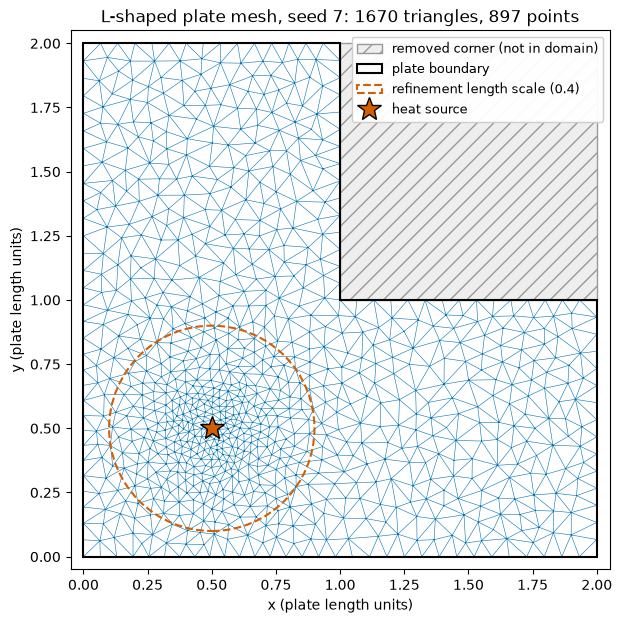

TASK 01 RESULT: all checks passed
  seed                          : 7 (reproduced exactly on a second build; fingerprint b8ea37b094b1)
  points / triangles (cells)    : 897 / 1670
  adjacency edges               : 2444  (shared-edge length min/mean/max 0.0175 / 0.0638 / 0.1276)
  connected components          : 1
  isolated cells                : 0
  triangle area min/mean/max    : 1.76e-04 / 1.80e-03 / 4.80e-03
  area covered / boundary length: 3.000000000 (L = 3.0) / 8.000000000 (L = 8.0)
  Euler characteristic V-E+T    : 1 (1 = one piece, no holes)
  point density near source     : 4.0x the rest of the plate (within r = 0.25 of the source at (0.5, 0.5))
  smallest triangle angle       : 27.5 degrees
  plot saved                    : results/mesh_seed7.png


In [2]:
# TASK_01_IMPLEMENTATION_CELL_START
# Task 01: deterministic triangular mesh of an L-shaped heat plate + its cell-adjacency graph.
import hashlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon, Rectangle
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import Delaunay

# ---- Geometry and mesh-size settings (design choices, not measurements) ----
SEED = 7
L_VERTICES = np.array([[0, 0], [2, 0], [2, 1], [1, 1], [1, 2], [0, 2]], dtype=float)  # counter-clockwise
NOTCH_X, NOTCH_Y = (1.0, 2.0), (1.0, 2.0)  # removed corner: the L is [0,2]^2 minus this square
L_AREA, L_PERIMETER = 3.0, 8.0             # exact values for this L, used as coverage checks
HEAT_SOURCE = np.array([0.5, 0.5])         # centre of the heat source (in the lower-left leg)
H_MIN, H_MAX = 0.02, 0.07                  # target point spacing at the source / far from it
GRADING_RADIUS = 0.4                       # distance over which the spacing grows from H_MIN to H_MAX
SPACING_FACTOR = 0.85                      # interior points keep >= 0.85*h from all points (must be > 1/sqrt(2))
N_CANDIDATES = 60_000                      # random candidate points for the spacing-controlled sampling
TRIANGLE_RANGE = (1000, 3000)
RESULTS_DIR = Path("results")


def target_spacing(xy):
    """Desired point spacing h(x, y): H_MIN at the heat source, growing smoothly to H_MAX."""
    dist = np.linalg.norm(xy - HEAT_SOURCE, axis=-1)
    return H_MAX - (H_MAX - H_MIN) * np.exp(-(dist / GRADING_RADIUS) ** 2)


def in_L(xy, tol=1e-12):
    """True for points in the closed L-shaped domain (boundary included)."""
    x, y = xy[..., 0], xy[..., 1]
    in_square = (x >= -tol) & (x <= 2 + tol) & (y >= -tol) & (y <= 2 + tol)
    in_open_notch = (x > NOTCH_X[0] + tol) & (y > NOTCH_Y[0] + tol)
    return in_square & ~in_open_notch


def boundary_points():
    """Points on all six L edges (including the two inner-corner edges), spaced by h along each edge."""
    pts = []
    for a, b in zip(L_VERTICES, np.roll(L_VERTICES, -1, axis=0)):
        s = np.linspace(0.0, 1.0, 2001)
        inv_h = 1.0 / target_spacing(a + s[:, None] * (b - a))
        # cumulative integral of ds / h along the edge; equal steps in it give spacing <= local h
        steps = np.concatenate([[0.0], np.cumsum(0.5 * (inv_h[1:] + inv_h[:-1]) * np.diff(s))])
        steps *= np.linalg.norm(b - a)
        n_segments = int(np.ceil(steps[-1]))
        s_nodes = np.interp(np.linspace(0.0, steps[-1], n_segments + 1), steps, s)
        pts.append(a + s_nodes[:-1, None] * (b - a))  # the edge's end vertex starts the next edge
    return np.vstack(pts)


def interior_points(rng, fixed_pts):
    """Spacing-controlled random sampling: accept a candidate only if it keeps
    SPACING_FACTOR * max(h_candidate, h_neighbour) from every accepted point."""
    cand = rng.uniform(0.0, 2.0, size=(N_CANDIDATES, 2))
    cand = cand[in_L(cand)]
    h_cand = target_spacing(cand)
    pts = np.empty((len(fixed_pts) + len(cand), 2))
    h_pts = np.empty(len(pts))
    pts[: len(fixed_pts)], h_pts[: len(fixed_pts)] = fixed_pts, target_spacing(fixed_pts)
    n = len(fixed_pts)
    for p, hp in zip(cand, h_cand):
        min_dist = SPACING_FACTOR * np.maximum(hp, h_pts[:n])
        if np.all(np.sum((pts[:n] - p) ** 2, axis=1) >= min_dist**2):
            pts[n], h_pts[n] = p, hp
            n += 1
    return pts[len(fixed_pts) : n]


def overlaps_open_notch(tri_xy, eps=1e-12):
    """Separating-axis test between each triangle and the open removed square.
    Two convex shapes share interior area iff no axis (the square's 2 normals or the
    triangle's 3 edge normals) separates them; touching along the L boundary counts as separated."""
    square = np.array([[NOTCH_X[0], NOTCH_Y[0]], [NOTCH_X[1], NOTCH_Y[0]],
                       [NOTCH_X[1], NOTCH_Y[1]], [NOTCH_X[0], NOTCH_Y[1]]])
    edges = np.roll(tri_xy, -1, axis=1) - tri_xy                        # (T, 3, 2)
    tri_normals = np.stack([-edges[..., 1], edges[..., 0]], axis=-1)    # (T, 3, 2)
    square_normals = np.broadcast_to(np.eye(2), (len(tri_xy), 2, 2))
    axes = np.concatenate([tri_normals, square_normals], axis=1)       # (T, 5, 2)
    tri_proj = np.einsum("tvd,tad->tav", tri_xy, axes)                 # (T, 5, 3)
    sq_proj = np.einsum("vd,tad->tav", square, axes)                   # (T, 5, 4)
    scale = eps * (1.0 + np.abs(axes).sum(axis=-1))
    separated = (tri_proj.max(-1) <= sq_proj.min(-1) + scale) | (sq_proj.max(-1) <= tri_proj.min(-1) + scale)
    return ~separated.any(axis=1)


def build_mesh(seed):
    """Return (points, triangles) for the L-shaped plate; triangles are counter-clockwise."""
    rng = np.random.default_rng(seed)
    b_pts = boundary_points()
    pts = np.vstack([b_pts, interior_points(rng, b_pts)])
    # Delaunay fills the convex hull, which includes part of the removed corner.
    # Boundary points are spaced <= h and interior points keep > h/sqrt(2) from them, so every
    # boundary segment's diametral circle is empty: each segment is a Delaunay edge and the mesh
    # follows the L boundary. Triangles in the removed corner are dropped by the exact
    # separating-axis test (not just a centroid test); the coverage checks below verify the result.
    tri = Delaunay(pts).simplices
    tri = tri[~overlaps_open_notch(pts[tri])]
    p0, p1, p2 = pts[tri[:, 0]], pts[tri[:, 1]], pts[tri[:, 2]]
    signed = (p1[:, 0] - p0[:, 0]) * (p2[:, 1] - p0[:, 1]) - (p1[:, 1] - p0[:, 1]) * (p2[:, 0] - p0[:, 0])
    tri[signed < 0] = tri[signed < 0][:, [0, 2, 1]]                    # make all counter-clockwise
    used = np.unique(tri)                                              # drop any point no triangle uses
    remap = np.full(len(pts), -1)
    remap[used] = np.arange(len(used))
    return pts[used], remap[tri]


def dist_to_L_boundary(xy):
    """Distance from each point to the nearest of the six L edges."""
    a, b = L_VERTICES, np.roll(L_VERTICES, -1, axis=0)
    ab = b - a
    t = np.clip(np.einsum("nkd,kd->nk", xy[:, None, :] - a, ab) / np.sum(ab**2, axis=1), 0, 1)
    nearest = a + t[..., None] * ab
    return np.linalg.norm(xy[:, None, :] - nearest, axis=-1).min(axis=1)


# ---- Build the mesh twice to check that seed 7 reproduces it exactly ----
points, triangles = build_mesh(SEED)
points_again, triangles_again = build_mesh(SEED)
assert np.array_equal(points, points_again) and np.array_equal(triangles, triangles_again), "mesh not reproducible"
fingerprint = hashlib.sha256(points.tobytes() + triangles.tobytes()).hexdigest()[:12]

# ---- Geometric checks ----
tri_xy = points[triangles]                                             # (T, 3, 2)
e1, e2 = tri_xy[:, 1] - tri_xy[:, 0], tri_xy[:, 2] - tri_xy[:, 0]
cell_areas = 0.5 * (e1[:, 0] * e2[:, 1] - e1[:, 1] * e2[:, 0])
cell_centroids = tri_xy.mean(axis=1)
edge_midpoints = 0.5 * (tri_xy + np.roll(tri_xy, -1, axis=1))
n_cells = len(triangles)

assert np.all(cell_areas > 1e-10), "degenerate or clockwise triangle"
assert np.all(in_L(points)), "mesh point outside the L"
assert np.all(in_L(cell_centroids)) and np.all(in_L(edge_midpoints.reshape(-1, 2))), "triangle part outside the L"
assert not overlaps_open_notch(tri_xy).any(), "triangle overlaps the removed corner"
assert abs(cell_areas.sum() - L_AREA) < 1e-9, f"cells cover {cell_areas.sum():.12f}, not the L area {L_AREA}"
assert TRIANGLE_RANGE[0] <= n_cells <= TRIANGLE_RANGE[1], f"{n_cells} triangles outside {TRIANGLE_RANGE}"

# ---- Cell-adjacency graph: two cells are neighbours when they share a complete mesh edge ----
local_edges = np.array([[0, 1], [1, 2], [2, 0]])
all_edges = np.sort(triangles[:, local_edges].reshape(-1, 2), axis=1)  # (3T, 2) vertex pairs
edge_owner = np.repeat(np.arange(n_cells), 3)
mesh_edges, edge_id, edge_count = np.unique(all_edges, axis=0, return_inverse=True, return_counts=True)
edge_id = edge_id.ravel()
assert edge_count.max() <= 2, "an edge is shared by more than two triangles (invalid mesh)"
edge_lengths = np.linalg.norm(points[mesh_edges[:, 0]] - points[mesh_edges[:, 1]], axis=1)

order = np.argsort(edge_id, kind="stable")
first = np.concatenate([[0], np.cumsum(edge_count)[:-1]])              # start of each edge's owners in `order`
interior = np.flatnonzero(edge_count == 2)
adjacency_pairs = np.stack([edge_owner[order[first[interior]]], edge_owner[order[first[interior] + 1]]], axis=1)
adjacency_weights = edge_lengths[interior]                             # shared-edge length; unit weights are an option later
n_adj = len(adjacency_pairs)
adjacency_matrix = coo_matrix(
    (np.concatenate([adjacency_weights, adjacency_weights]),
     (np.concatenate([adjacency_pairs[:, 0], adjacency_pairs[:, 1]]),
      np.concatenate([adjacency_pairs[:, 1], adjacency_pairs[:, 0]]))),
    shape=(n_cells, n_cells)).tocsr()

boundary = edge_count == 1
boundary_length = edge_lengths[boundary].sum()
boundary_midpoints = 0.5 * (points[mesh_edges[boundary, 0]] + points[mesh_edges[boundary, 1]])
cell_degree = np.bincount(adjacency_pairs.ravel(), minlength=n_cells)
n_components, _ = connected_components(adjacency_matrix, directed=False)
n_isolated = int(np.sum(cell_degree == 0))
euler = len(points) - len(mesh_edges) + n_cells                        # 1 for a hole-free mesh of one piece

assert abs(boundary_length - L_PERIMETER) < 1e-9, f"boundary length {boundary_length:.12f} != {L_PERIMETER}"
assert dist_to_L_boundary(boundary_midpoints).max() < 1e-9, "a boundary edge is not on the L boundary"
assert euler == 1, f"Euler characteristic {euler} != 1 (holes or several pieces)"
assert cell_degree.max() <= 3
assert n_components == 1 and n_isolated == 0, "cell graph is not connected"

# ---- Refinement check: point density near the source vs. elsewhere ----
NEAR_RADIUS = 0.25                                                     # this disc lies fully inside the L
near = np.linalg.norm(points - HEAT_SOURCE, axis=1) <= NEAR_RADIUS
density_near = near.sum() / (np.pi * NEAR_RADIUS**2)
density_rest = (~near).sum() / (L_AREA - np.pi * NEAR_RADIUS**2)
assert density_near > density_rest, "mesh is not denser near the heat source"

# Smallest interior angle (mesh-quality diagnostic)
sides = np.linalg.norm(np.roll(tri_xy, -1, axis=1) - tri_xy, axis=-1)  # side k joins vertices k and k+1
a_, b_, c_ = sides[:, 1], sides[:, 2], sides[:, 0]                     # side opposite vertex 0, 1, 2
cos_angles = np.stack([(b_**2 + c_**2 - a_**2) / (2 * b_ * c_),
                       (a_**2 + c_**2 - b_**2) / (2 * a_ * c_),
                       (a_**2 + b_**2 - c_**2) / (2 * a_ * b_)], axis=1)
min_angle_deg = np.degrees(np.arccos(np.clip(cos_angles, -1, 1))).min()

# ---- Plot ----
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
plot_path = RESULTS_DIR / f"mesh_seed{SEED}.png"
fig, ax = plt.subplots(figsize=(7, 7))
ax.add_patch(Rectangle((NOTCH_X[0], NOTCH_Y[0]), 1, 1, facecolor="#EEEEEE", edgecolor="#999999",
                       hatch="//", label="removed corner (not in domain)"))
ax.triplot(points[:, 0], points[:, 1], triangles, color="#0072B2", lw=0.4)
ax.add_patch(Polygon(L_VERTICES, closed=True, fill=False, edgecolor="black", lw=1.5, label="plate boundary"))
ax.add_patch(Circle(HEAT_SOURCE, GRADING_RADIUS, fill=False, ls="--", lw=1.5, edgecolor="#D55E00",
                    label=f"refinement length scale ({GRADING_RADIUS})"))
ax.plot(*HEAT_SOURCE, marker="*", ms=18, color="#D55E00", mec="black", ls="none", label="heat source")
ax.set_aspect("equal")
ax.set_xlim(-0.05, 2.05)
ax.set_ylim(-0.05, 2.05)
ax.set_xlabel("x (plate length units)")
ax.set_ylabel("y (plate length units)")
ax.set_title(f"L-shaped plate mesh, seed {SEED}: {n_cells} triangles, {len(points)} points")
ax.legend(loc="upper right", fontsize=9, framealpha=0.95)
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
assert plot_path.exists()

# ---- Summary (only reached if every assertion above passed) ----
print("TASK 01 RESULT: all checks passed")
print(f"  seed                          : {SEED} (reproduced exactly on a second build; fingerprint {fingerprint})")
print(f"  points / triangles (cells)    : {len(points)} / {n_cells}")
print(f"  adjacency edges               : {n_adj}  (shared-edge length min/mean/max "
      f"{adjacency_weights.min():.4f} / {adjacency_weights.mean():.4f} / {adjacency_weights.max():.4f})")
print(f"  connected components          : {n_components}")
print(f"  isolated cells                : {n_isolated}")
print(f"  triangle area min/mean/max    : {cell_areas.min():.2e} / {cell_areas.mean():.2e} / {cell_areas.max():.2e}")
print(f"  area covered / boundary length: {cell_areas.sum():.9f} (L = {L_AREA}) / {boundary_length:.9f} (L = {L_PERIMETER})")
print(f"  Euler characteristic V-E+T    : {euler} (1 = one piece, no holes)")
print(f"  point density near source     : {density_near / density_rest:.1f}x the rest of the plate "
      f"(within r = {NEAR_RADIUS} of the source at ({HEAT_SOURCE[0]}, {HEAT_SOURCE[1]}))")
print(f"  smallest triangle angle       : {min_angle_deg:.1f} degrees")
print(f"  plot saved                    : {plot_path}")
# TASK_01_IMPLEMENTATION_CELL_END

### Review checklist (complete after running Task 01)
- [ ] The cell runs without errors.
- [ ] The reported triangle count is between 1,000 and 3,000.
- [ ] The L-shaped missing corner contains no triangles.
- [ ] The heat source is visible and refinement is denser nearby.
- [ ] Every cell has the expected graph adjacency; no unexpected isolated cells.
- [ ] `results/mesh_seed7.png` exists.
- [ ] Actual output is reviewed before beginning Task 02.

## Task 01b — Benchmark mesh cases (same method, four plates)

**Goal:** build a small, fixed set of test meshes now, before any partitioning or QAOA result exists, so later results cannot be cherry-picked. The mesh method is exactly the Task 01 method, generalised to other shapes.

| Case | Plate | Refinement | Why it is in the set |
|---|---|---|---|
| 1 control | Rectangle 2 × 1 | none (uniform mesh) | Known answer: the best equal split should be close to a straight vertical cut at x = 1. If the pipeline misses it, something is broken. |
| 2 main | L-plate (Task 01) | one heat source, strength 1.0 at (0.5, 0.5) | Headline case; the live Qollab run uses it. Must be identical to the Task 01 mesh (checked). |
| 3 hard | L-plate | two heat sources: strength 1.0 at (0.5, 0.5), 0.5 at (1.55, 0.5) | Work concentrated at both ends, so a simple "cut at an x-position" baseline should struggle; best test for unequal devices. |
| 4 structural | Rectangle 2 × 1 with a hole (radius 0.2) under uniform tension at both ends | around the hole edge, where stress concentrates | Same kind of structural FEA mesh as the IonQ/Synopsys LS-DYNA work. **No stress is computed**; the mesh is only refined the way a stress solver would need. |

**Assumption:** "stronger source → finer mesh" is our modelling choice; what really needs fine cells is a steep change in the solution.

**Acceptance checks (per case):** the Task 01 invariants — 1,000–3,000 triangles, all inside the domain, covered area and boundary length equal to the exact values, Euler characteristic = 1 − number of holes, one connected cell graph, no isolated cells, reproducible with seed 7 — plus: case 2 identical to Task 01, cells finer near each feature, and the strength-1.0 source finer than the strength-0.5 source.

**Scope limit:** still mesh only — no coarsening, partitioning, Ising/QUBO, QAOA, PDE or stress solving.

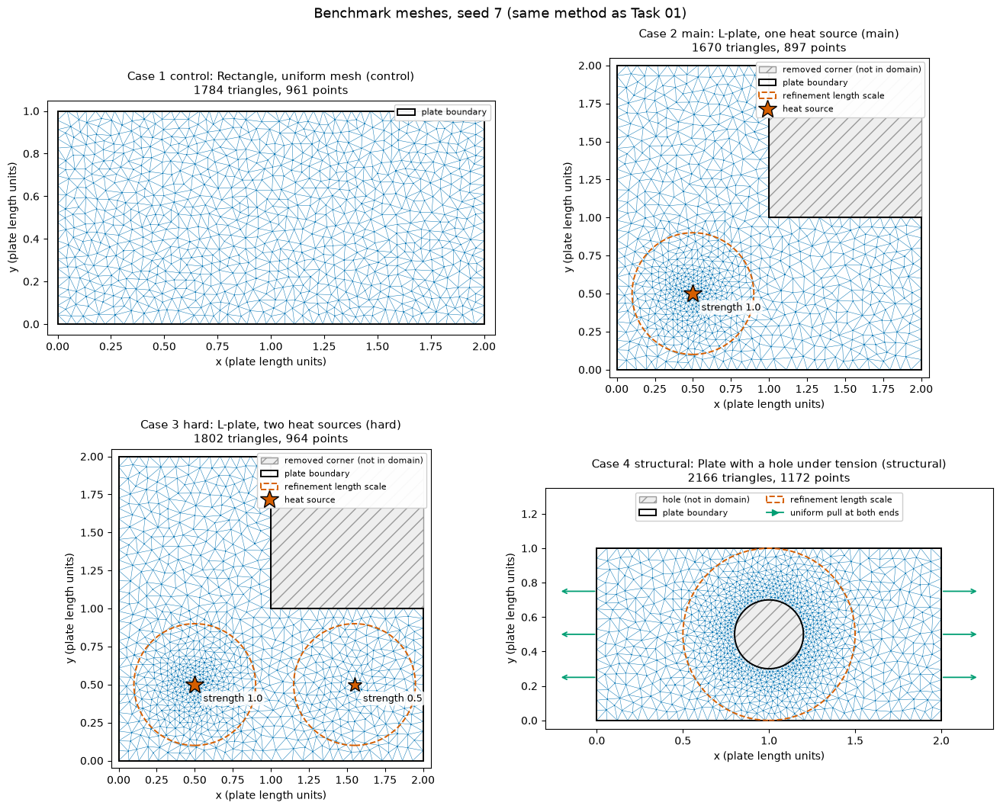

TASK 01b RESULT: all checks passed for 4 cases (seed 7, each rebuilt identically)
  case          points  cells adj.edges comp. isol. Euler           area min/mean/max min angle  finer near feature   fingerprint
  1 control        961   1784      2608     1     0     1   6.74e-04 / 1.12e-03 / 2.17e-03    29.1°  - (uniform)          113f8857911b
  2 main           897   1670      2444     1     0     1   1.76e-04 / 1.80e-03 / 4.80e-03    27.5°  5.1x                 b8ea37b094b1
  3 hard           964   1802      2641     1     0     1   1.76e-04 / 1.66e-03 / 4.80e-03    27.5°  4.7x, 1.4x           ad4c94b1df84
  4 structural    1172   2166      3160     1     0     0   1.20e-04 / 8.65e-04 / 3.32e-03    23.7°  4.6x                 593b05f3bf00
  1 control    area covered 2.000000000 (exact 2.000000000), boundary 6.000000000 (exact 6.000000000)
  2 main       area covered 3.000000000 (exact 3.000000000), boundary 8.000000000 (exact 8.000000000)
  3 hard       area covered 3.000000000 (exa

In [3]:
# TASK_01B_IMPLEMENTATION_CELL_START
# Task 01b: the Task 01 mesh method generalised to four benchmark cases, built and plotted together.
import hashlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import Delaunay

CASES_SEED = 7
CASES_N_CANDIDATES = 60_000
CASES_SPACING_FACTOR = 0.85    # > 1/sqrt(2): keeps every boundary segment a Delaunay edge (see Task 01)
CASES_TRIANGLE_RANGE = (1000, 3000)
CASES_RESULTS_DIR = Path("results")


def rectangle(x0, y0, x1, y1):
    """Counter-clockwise rectangle."""
    return np.array([[x0, y0], [x1, y0], [x1, y1], [x0, y1]], dtype=float)


def regular_polygon(center, radius, n_sides):
    """Counter-clockwise regular polygon (used for the hole, which is meshed as this polygon)."""
    angles = 2 * np.pi * np.arange(n_sides) / n_sides
    return np.asarray(center, float) + radius * np.stack([np.cos(angles), np.sin(angles)], axis=1)


HOLE_CENTER, HOLE_RADIUS = np.array([1.0, 0.5]), 0.2
HOLE_H_MIN = 0.018                                    # target spacing at the hole edge (case 4)
# Hole meshed as a polygon whose sides are just under HOLE_H_MIN, so each side is exactly one mesh edge
HOLE_POLYGON = regular_polygon(HOLE_CENTER, HOLE_RADIUS, int(np.ceil(2 * np.pi * HOLE_RADIUS / HOLE_H_MIN)))

# Each domain = a convex hull minus convex cut-outs; `loops` are the boundary curves that get boundary points.
# Features refine the mesh: spacing falls from h_max towards h_min as strength * exp(-(d / radius)^2) -> 1,
# with d measured from the feature's centre minus `core` (core = hole radius: distance from the hole edge).
# "Stronger source -> finer mesh" is our modelling assumption, not physics we computed.
MESH_CASES = {
    "1 control": dict(
        title="Rectangle, uniform mesh (control)",
        hull=rectangle(0, 0, 2, 1), cutouts=[], loops=[rectangle(0, 0, 2, 1)], n_holes=0,
        h_min=0.045, h_max=0.045, features=[]),
    "2 main": dict(
        title="L-plate, one heat source (main)",
        hull=rectangle(0, 0, 2, 2), cutouts=[rectangle(1, 1, 2, 2)],
        loops=[np.array([[0, 0], [2, 0], [2, 1], [1, 1], [1, 2], [0, 2]], dtype=float)], n_holes=0,
        h_min=0.02, h_max=0.07,
        features=[dict(kind="heat source", center=(0.5, 0.5), core=0.0, strength=1.0, radius=0.4)]),
    "3 hard": dict(
        title="L-plate, two heat sources (hard)",
        hull=rectangle(0, 0, 2, 2), cutouts=[rectangle(1, 1, 2, 2)],
        loops=[np.array([[0, 0], [2, 0], [2, 1], [1, 1], [1, 2], [0, 2]], dtype=float)], n_holes=0,
        h_min=0.02, h_max=0.07,
        features=[dict(kind="heat source", center=(0.5, 0.5), core=0.0, strength=1.0, radius=0.4),
                  dict(kind="heat source", center=(1.55, 0.5), core=0.0, strength=0.5, radius=0.4)]),
    "4 structural": dict(
        title="Plate with a hole under tension (structural)",
        hull=rectangle(0, 0, 2, 1), cutouts=[HOLE_POLYGON], loops=[rectangle(0, 0, 2, 1), HOLE_POLYGON],
        n_holes=1, h_min=HOLE_H_MIN, h_max=0.06,
        features=[dict(kind="hole edge", center=HOLE_CENTER, core=HOLE_RADIUS, strength=1.0, radius=0.3)]),
}


def polygon_area(poly):
    x, y = poly[:, 0], poly[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def feature_distance(feature, xy):
    return np.maximum(np.linalg.norm(xy - np.asarray(feature["center"], float), axis=-1) - feature["core"], 0.0)


def case_spacing(case, xy):
    """Target point spacing h(x, y) for a case (identical to Task 01 for the single-source L)."""
    weight = np.zeros(xy.shape[:-1])
    for feature in case["features"]:
        weight = np.maximum(weight, feature["strength"] * np.exp(-(feature_distance(feature, xy) / feature["radius"]) ** 2))
    return case["h_max"] - (case["h_max"] - case["h_min"]) * weight


def edge_cross(poly, xy):
    """Cross products of each polygon edge with (point - edge start); all >= 0 inside a CCW convex polygon."""
    ab = np.roll(poly, -1, axis=0) - poly
    rel = xy[..., None, :] - poly
    return ab[:, 0] * rel[..., 1] - ab[:, 1] * rel[..., 0]


def in_case_domain(case, xy, tol=1e-12):
    """Closed domain: inside the convex hull and not strictly inside any cut-out."""
    inside = np.all(edge_cross(case["hull"], xy) >= -tol, axis=-1)
    for cut in case["cutouts"]:
        inside &= ~np.all(edge_cross(cut, xy) > tol, axis=-1)
    return inside


def loop_boundary_points(case, loop):
    """Points along every edge of a boundary loop, spaced so each step is <= the local target spacing."""
    pts = []
    for a, b in zip(loop, np.roll(loop, -1, axis=0)):
        s = np.linspace(0.0, 1.0, 2001)
        inv_h = 1.0 / case_spacing(case, a + s[:, None] * (b - a))
        steps = np.concatenate([[0.0], np.cumsum(0.5 * (inv_h[1:] + inv_h[:-1]) * np.diff(s))])
        steps *= np.linalg.norm(b - a)
        n_segments = int(np.ceil(steps[-1]))
        s_nodes = np.interp(np.linspace(0.0, steps[-1], n_segments + 1), steps, s)
        pts.append(a + s_nodes[:-1, None] * (b - a))
    return np.vstack(pts)


def overlaps_open_polygon(tri_xy, poly, eps=1e-12):
    """Separating-axis test (as in Task 01) between triangles and an open convex polygon.
    Only triangles whose bounding box meets the polygon's bounding box are tested in detail."""
    result = np.zeros(len(tri_xy), dtype=bool)
    lo, hi = poly.min(axis=0), poly.max(axis=0)
    near = np.flatnonzero(np.all(tri_xy.max(axis=1) > lo + eps, axis=1) & np.all(tri_xy.min(axis=1) < hi - eps, axis=1))
    if len(near) == 0:
        return result
    tri = tri_xy[near]
    tri_edges = np.roll(tri, -1, axis=1) - tri
    poly_edges = np.roll(poly, -1, axis=0) - poly
    axes = np.concatenate([np.stack([-tri_edges[..., 1], tri_edges[..., 0]], axis=-1),
                           np.broadcast_to(np.stack([-poly_edges[:, 1], poly_edges[:, 0]], axis=-1), (len(tri), len(poly), 2))],
                          axis=1)
    tri_proj = np.einsum("tvd,tad->tav", tri, axes)
    poly_proj = np.einsum("vd,tad->tav", poly, axes)
    scale = eps * (1.0 + np.abs(axes).sum(axis=-1))
    separated = (tri_proj.max(-1) <= poly_proj.min(-1) + scale) | (poly_proj.max(-1) <= tri_proj.min(-1) + scale)
    result[near] = ~separated.any(axis=1)
    return result


def build_case_mesh(case, seed):
    """Same algorithm as Task 01: boundary points, spacing-controlled random interior points,
    Delaunay, removal of triangles overlapping a cut-out, counter-clockwise orientation."""
    rng = np.random.default_rng(seed)
    b_pts = np.vstack([loop_boundary_points(case, loop) for loop in case["loops"]])
    lo, hi = case["hull"].min(axis=0), case["hull"].max(axis=0)
    cand = rng.uniform(lo, hi, size=(CASES_N_CANDIDATES, 2))
    cand = cand[in_case_domain(case, cand)]
    h_cand = case_spacing(case, cand)
    pts = np.empty((len(b_pts) + len(cand), 2))
    h_pts = np.empty(len(pts))
    pts[: len(b_pts)], h_pts[: len(b_pts)] = b_pts, case_spacing(case, b_pts)
    n = len(b_pts)
    for p, hp in zip(cand, h_cand):
        min_dist = CASES_SPACING_FACTOR * np.maximum(hp, h_pts[:n])
        if np.all(np.sum((pts[:n] - p) ** 2, axis=1) >= min_dist**2):
            pts[n], h_pts[n] = p, hp
            n += 1
    pts = pts[:n]
    tri = Delaunay(pts).simplices
    for cut in case["cutouts"]:
        tri = tri[~overlaps_open_polygon(pts[tri], cut)]
    p0, p1, p2 = pts[tri[:, 0]], pts[tri[:, 1]], pts[tri[:, 2]]
    signed = (p1[:, 0] - p0[:, 0]) * (p2[:, 1] - p0[:, 1]) - (p1[:, 1] - p0[:, 1]) * (p2[:, 0] - p0[:, 0])
    tri[signed < 0] = tri[signed < 0][:, [0, 2, 1]]
    used = np.unique(tri)
    remap = np.full(len(pts), -1)
    remap[used] = np.arange(len(used))
    return pts[used], remap[tri]


def check_case_mesh(name, case, pts, tri):
    """All Task 01 invariants, with this case's exact area, boundary length and number of holes."""
    tri_xy = pts[tri]
    e1, e2 = tri_xy[:, 1] - tri_xy[:, 0], tri_xy[:, 2] - tri_xy[:, 0]
    areas = 0.5 * (e1[:, 0] * e2[:, 1] - e1[:, 1] * e2[:, 0])
    centroids = tri_xy.mean(axis=1)
    midpoints = 0.5 * (tri_xy + np.roll(tri_xy, -1, axis=1)).reshape(-1, 2)
    n_cells = len(tri)
    exact_area = polygon_area(case["hull"]) - sum(polygon_area(c) for c in case["cutouts"])
    exact_perimeter = sum(np.linalg.norm(np.roll(l, -1, axis=0) - l, axis=1).sum() for l in case["loops"])

    assert np.all(areas > 1e-10), f"{name}: degenerate or clockwise triangle"
    assert np.all(in_case_domain(case, pts)) and np.all(in_case_domain(case, centroids)), f"{name}: outside domain"
    assert np.all(in_case_domain(case, midpoints)), f"{name}: triangle edge outside domain"
    for cut in case["cutouts"]:
        assert not overlaps_open_polygon(tri_xy, cut).any(), f"{name}: triangle overlaps a cut-out"
    assert abs(areas.sum() - exact_area) < 1e-9, f"{name}: covers {areas.sum():.12f}, expected {exact_area:.12f}"
    assert CASES_TRIANGLE_RANGE[0] <= n_cells <= CASES_TRIANGLE_RANGE[1], f"{name}: {n_cells} triangles"

    all_edges = np.sort(tri[:, [[0, 1], [1, 2], [2, 0]]].reshape(-1, 2), axis=1)
    owner = np.repeat(np.arange(n_cells), 3)
    mesh_edges, edge_id, edge_count = np.unique(all_edges, axis=0, return_inverse=True, return_counts=True)
    edge_id = edge_id.ravel()
    assert edge_count.max() <= 2, f"{name}: edge shared by more than two triangles"
    lengths = np.linalg.norm(pts[mesh_edges[:, 0]] - pts[mesh_edges[:, 1]], axis=1)
    order = np.argsort(edge_id, kind="stable")
    first = np.concatenate([[0], np.cumsum(edge_count)[:-1]])
    inner = np.flatnonzero(edge_count == 2)
    pairs = np.stack([owner[order[first[inner]]], owner[order[first[inner] + 1]]], axis=1)
    weights = lengths[inner]                                           # shared-edge length
    adj = coo_matrix((np.concatenate([weights, weights]),
                      (np.concatenate([pairs[:, 0], pairs[:, 1]]), np.concatenate([pairs[:, 1], pairs[:, 0]]))),
                     shape=(n_cells, n_cells)).tocsr()
    boundary = edge_count == 1
    boundary_length = lengths[boundary].sum()
    b_mid = 0.5 * (pts[mesh_edges[boundary, 0]] + pts[mesh_edges[boundary, 1]])
    seg_a = np.vstack(case["loops"])
    seg_b = np.vstack([np.roll(l, -1, axis=0) for l in case["loops"]])
    ab = seg_b - seg_a
    t = np.clip(np.einsum("nkd,kd->nk", b_mid[:, None, :] - seg_a, ab) / np.sum(ab**2, axis=1), 0, 1)
    dist_to_boundary = np.linalg.norm(b_mid[:, None, :] - (seg_a + t[..., None] * ab), axis=-1).min(axis=1)
    degree = np.bincount(pairs.ravel(), minlength=n_cells)
    n_comp, _ = connected_components(adj, directed=False)
    euler = len(pts) - len(mesh_edges) + n_cells

    assert abs(boundary_length - exact_perimeter) < 1e-9, f"{name}: boundary length {boundary_length:.12f}"
    assert dist_to_boundary.max() < 1e-9, f"{name}: boundary edge not on the domain boundary"
    assert euler == 1 - case["n_holes"], f"{name}: Euler characteristic {euler}, expected {1 - case['n_holes']}"
    assert degree.max() <= 3 and n_comp == 1 and np.sum(degree == 0) == 0, f"{name}: cell graph not connected"

    # Refinement: how much smaller the cells are near each feature than away from all features
    zones = [feature_distance(f, centroids) <= 0.5 * f["radius"] for f in case["features"]]
    far = ~np.any(zones, axis=0) if zones else np.ones(n_cells, bool)
    refinement = [areas[far].mean() / areas[z].mean() for z in zones]
    assert all(r > 1 for r in refinement), f"{name}: not finer near a feature"

    sides = np.linalg.norm(np.roll(tri_xy, -1, axis=1) - tri_xy, axis=-1)
    a_, b_, c_ = sides[:, 1], sides[:, 2], sides[:, 0]
    cos_ang = np.stack([(b_**2 + c_**2 - a_**2) / (2 * b_ * c_), (a_**2 + c_**2 - b_**2) / (2 * a_ * c_),
                        (a_**2 + b_**2 - c_**2) / (2 * a_ * b_)], axis=1)
    return dict(points=pts, triangles=tri, cell_areas=areas, cell_centroids=centroids,
                adjacency_pairs=pairs, adjacency_weights=weights, adjacency_matrix=adj,
                n_components=n_comp, n_isolated=int(np.sum(degree == 0)), euler=euler,
                exact_area=exact_area, boundary_length=boundary_length, exact_perimeter=exact_perimeter,
                refinement=refinement, min_angle=np.degrees(np.arccos(np.clip(cos_ang, -1, 1))).min(),
                fingerprint=hashlib.sha256(pts.tobytes() + tri.tobytes()).hexdigest()[:12])


# ---- Build every case twice (reproducibility) and check it ----
mesh_cases = {}
for name, case in MESH_CASES.items():
    pts, tri = build_case_mesh(case, CASES_SEED)
    pts_again, tri_again = build_case_mesh(case, CASES_SEED)
    assert np.array_equal(pts, pts_again) and np.array_equal(tri, tri_again), f"{name}: not reproducible"
    mesh_cases[name] = check_case_mesh(name, case, pts, tri)

# Two sources: the strength-1.0 zone must be finer than the strength-0.5 zone
assert mesh_cases["3 hard"]["refinement"][0] > mesh_cases["3 hard"]["refinement"][1]

# Case 2 must be exactly the Task 01 mesh (Task 01 defines `points` and `triangles`)
if "points" in globals() and "triangles" in globals():
    assert np.array_equal(mesh_cases["2 main"]["points"], points) and np.array_equal(mesh_cases["2 main"]["triangles"], triangles), \
        "case 2 differs from the Task 01 mesh"
    task01_match = "identical to the Task 01 mesh"
else:
    task01_match = "not compared (run the Task 01 cell first)"

# ---- Plot all cases ----
CASES_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
cases_plot_path = CASES_RESULTS_DIR / f"mesh_cases_seed{CASES_SEED}.png"
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5), constrained_layout=True)
for ax, (name, case) in zip(axes.ravel(), MESH_CASES.items()):
    m = mesh_cases[name]
    for cut in case["cutouts"]:
        ax.add_patch(Polygon(cut, closed=True, facecolor="#EEEEEE", edgecolor="#999999", hatch="//",
                             label="hole (not in domain)" if case["n_holes"] else "removed corner (not in domain)"))
    ax.triplot(m["points"][:, 0], m["points"][:, 1], m["triangles"], color="#0072B2", lw=0.35)
    for k, loop in enumerate(case["loops"]):
        ax.add_patch(Polygon(loop, closed=True, fill=False, edgecolor="black", lw=1.4, label="plate boundary" if k == 0 else None))
    for k, f in enumerate(case["features"]):
        ax.add_patch(Circle(f["center"], f["core"] + f["radius"], fill=False, ls="--", lw=1.4, edgecolor="#D55E00",
                            label="refinement length scale" if k == 0 else None))
        if f["kind"] == "heat source":
            ax.plot(*f["center"], marker="*", ms=10 + 8 * f["strength"], color="#D55E00", mec="black", ls="none",
                    label="heat source" if k == 0 else None)
            ax.annotate(f"strength {f['strength']}", f["center"], xytext=(8, -16), textcoords="offset points",
                        fontsize=9, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    if name == "4 structural":
        for x_tail, x_head in [(0.0, -0.22), (2.0, 2.22)]:
            for y in (0.25, 0.5, 0.75):
                ax.annotate("", xy=(x_head, y), xytext=(x_tail, y), arrowprops=dict(arrowstyle="->", lw=1.3, color="#009E73"))
        ax.plot([], [], color="#009E73", marker=">", lw=1.3, label="uniform pull at both ends")
    lo, hi = case["hull"].min(axis=0), case["hull"].max(axis=0)
    pad = 0.3 if name == "4 structural" else 0.05
    ax.set_xlim(lo[0] - pad, hi[0] + pad)
    ax.set_ylim(lo[1] - 0.05, hi[1] + (0.35 if name == "4 structural" else 0.05))
    ax.set_aspect("equal")
    ax.set_xlabel("x (plate length units)")
    ax.set_ylabel("y (plate length units)")
    ax.set_title(f"Case {name}: {case['title']}\n{len(m['triangles'])} triangles, {len(m['points'])} points", fontsize=11)
    if name == "4 structural":
        ax.legend(loc="upper center", ncol=2, fontsize=8, framealpha=0.95)
    else:
        ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
fig.suptitle(f"Benchmark meshes, seed {CASES_SEED} (same method as Task 01)", fontsize=13)
fig.savefig(cases_plot_path, dpi=130)
plt.show()
assert cases_plot_path.exists()

# ---- Summary (only reached if every assertion above passed) ----
print(f"TASK 01b RESULT: all checks passed for {len(mesh_cases)} cases (seed {CASES_SEED}, each rebuilt identically)")
print(f"  {'case':<13}{'points':>7}{'cells':>7}{'adj.edges':>10}{'comp.':>6}{'isol.':>6}{'Euler':>6}"
      f"{'area min/mean/max':>28}{'min angle':>10}  finer near feature   fingerprint")
for name, m in mesh_cases.items():
    a = m["cell_areas"]
    finer = ", ".join(f"{r:.1f}x" for r in m["refinement"]) or "- (uniform)"
    print(f"  {name:<13}{len(m['points']):>7}{len(m['triangles']):>7}{len(m['adjacency_pairs']):>10}{m['n_components']:>6}"
          f"{m['n_isolated']:>6}{m['euler']:>6}   {a.min():.2e} / {a.mean():.2e} / {a.max():.2e}{m['min_angle']:>8.1f}°  "
          f"{finer:<19}  {m['fingerprint']}")
for name, m in mesh_cases.items():
    print(f"  {name:<13}area covered {m['cell_areas'].sum():.9f} (exact {m['exact_area']:.9f}), "
          f"boundary {m['boundary_length']:.9f} (exact {m['exact_perimeter']:.9f})")
print(f"  case 2 check : {task01_match}")
print(f"  plot saved   : {cases_plot_path}")
# TASK_01B_IMPLEMENTATION_CELL_END

## Task 01c — Complexity ladder (five more cases on the same L-plate)

**Goal:** stress-test the splitting with cases that get harder step by step. All five use the **same L-plate**; each case is the previous one plus exactly one ingredient, so any change in difficulty can be traced to that ingredient.

| Case | Adds | What changes |
|---|---|---|
| 5 L uniform | nothing (easiest) | uniform mesh, no source |
| 6 three sources | three heat sources, strengths 1.0 / 0.7 / 0.4 | mesh density (uneven work) |
| 7 materials | heavy-material zone (top arm) | each triangle there costs 3× work |
| 8 coupling | strong-coupling zone (right arm) | each border edge there costs 3× to cut |
| 9 priority | priority zone (disc around the strongest source) | those cells should run on the fast device |

Cases 7–9 use the mesh of case 6; only the weights differ. This cell also gives **every** case (1–9) three arrays that later tasks read: `cell_work` (per triangle), `adjacency_cost` (per shared edge) and `cell_priority` (per triangle). Cases without zones get work 1, cost 1 and no priority cells.

**Assumptions:** the zones and the factor 3 are modelling choices made to create harder instances; they are not measured physics. They are fixed here, before any partitioning or QAOA result exists. Hardware (number and speed of devices, memory limits) is not part of these cases; it is set in the run settings.

**Acceptance checks:** all Task 01 mesh invariants for the two new meshes (cases 5 and 6), reproducible with seed 7; cells finer for stronger sources (1.0 > 0.7 > 0.4); each zone present exactly in the cases that define it; cases 7–9 share the mesh of case 6.

**Scope limit:** mesh and weights only — no coarsening, Ising/QUBO, partitioning, QAOA, PDE solve or hardware model.

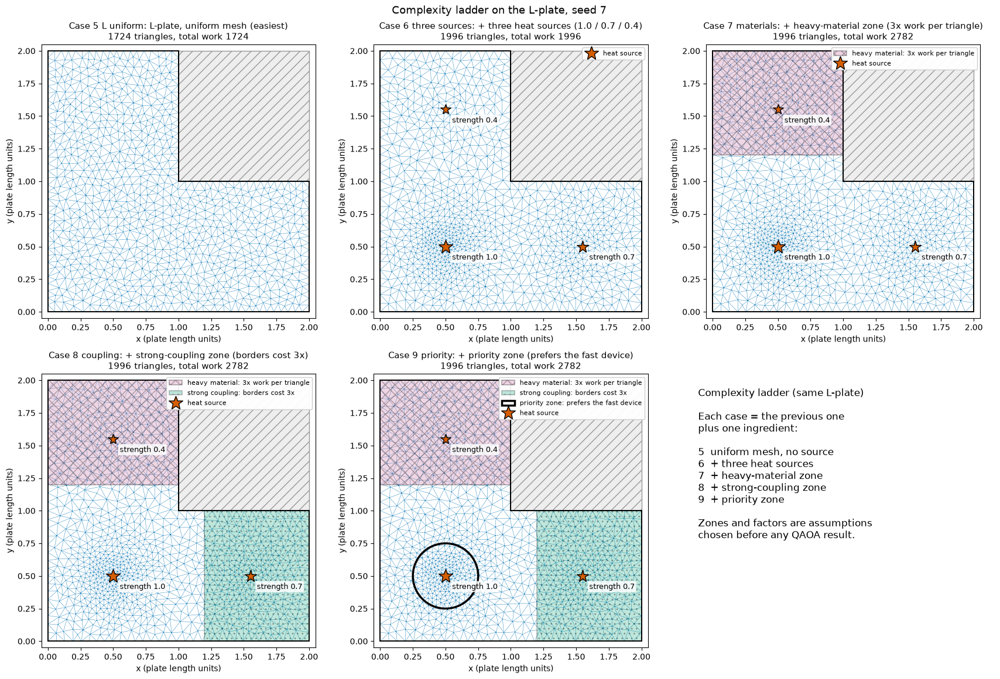

TASK 01c RESULT: all checks passed; 9 cases now have work, border cost and priority arrays
  case              cells total work work in heavy zone border edges cost in coupling zone priority cells
  1 control          1784       1784                0%          2608                   0%               0
  2 main             1670       1670                0%          2444                   0%               0
  3 hard             1802       1802                0%          2641                   0%               0
  4 structural       2166       2166                0%          3160                   0%               0
  5 L uniform        1724       1724                0%          2511                   0%               0
  6 three sources    1996       1996                0%          2931                   0%               0
  7 materials        1996       2782               42%          2931                   0%               0
  8 coupling         1996       2782               42%       

In [4]:
# TASK_01C_IMPLEMENTATION_CELL_START
# Task 01c: complexity ladder - five more cases on the SAME L-plate, each adding one ingredient that makes
# a good split harder to find. Also gives every case its per-triangle work and per-border cost.
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon, Rectangle

LADDER_SEED = 7
L_PLATE = dict(hull=rectangle(0, 0, 2, 2), cutouts=[rectangle(1, 1, 2, 2)],
               loops=[np.array([[0, 0], [2, 0], [2, 1], [1, 1], [1, 2], [0, 2]], dtype=float)], n_holes=0)
THREE_SOURCES = [dict(kind="heat source", center=(0.5, 0.5), core=0.0, strength=1.0, radius=0.4),
                 dict(kind="heat source", center=(1.55, 0.5), core=0.0, strength=0.7, radius=0.4),
                 dict(kind="heat source", center=(0.5, 1.55), core=0.0, strength=0.4, radius=0.4)]
# Zones are modelling ASSUMPTIONS chosen to make the split harder; they are not measured physics.
HEAVY_ZONE = dict(box=(0.0, 1.2, 1.0, 2.0), work_factor=3.0)     # (x0, y0, x1, y1): each triangle costs 3x work
COUPLING_ZONE = dict(box=(1.2, 0.0, 2.0, 1.0), cost_factor=3.0)  # each cut border edge costs 3x communication
PRIORITY_ZONE = dict(center=(0.5, 0.5), radius=0.25)             # cells that should run on the fast device

# Each case = the previous one plus exactly one ingredient. Cases 7-9 reuse the mesh of case 6 (`mesh_of`).
MESH_CASES["5 L uniform"] = dict(title="L-plate, uniform mesh (easiest)", **L_PLATE, h_min=0.055, h_max=0.055, features=[])
MESH_CASES["6 three sources"] = dict(title="+ three heat sources (1.0 / 0.7 / 0.4)", **L_PLATE, h_min=0.02, h_max=0.07,
                                     features=THREE_SOURCES)
MESH_CASES["7 materials"] = dict(MESH_CASES["6 three sources"], title="+ heavy-material zone (3x work per triangle)",
                                 mesh_of="6 three sources", work_zones=[HEAVY_ZONE])
MESH_CASES["8 coupling"] = dict(MESH_CASES["7 materials"], title="+ strong-coupling zone (borders cost 3x)",
                                cost_zones=[COUPLING_ZONE])
MESH_CASES["9 priority"] = dict(MESH_CASES["8 coupling"], title="+ priority zone (prefers the fast device)",
                                priority_zones=[PRIORITY_ZONE])
LADDER_CASES = ["5 L uniform", "6 three sources", "7 materials", "8 coupling", "9 priority"]
assert set(BENCHMARK_CASES) == set(MESH_CASES), "BENCHMARK_CASES in the run settings must list exactly the defined cases"


def in_box(xy, box):
    x0, y0, x1, y1 = box
    return (xy[:, 0] >= x0) & (xy[:, 0] <= x1) & (xy[:, 1] >= y0) & (xy[:, 1] <= y1)


def add_case_weights(spec, mesh):
    """Copy of a mesh dict with `cell_work` (per triangle), `adjacency_cost` (per shared edge) and
    `cell_priority` (bool per triangle). Cases without zones get work 1, cost 1 and no priority cells."""
    centroids, pairs = mesh["cell_centroids"], mesh["adjacency_pairs"]
    work = np.ones(len(centroids))
    for zone in spec.get("work_zones", []):
        work[in_box(centroids, zone["box"])] *= zone["work_factor"]
    cost = np.ones(len(pairs))
    edge_position = 0.5 * (centroids[pairs[:, 0]] + centroids[pairs[:, 1]])   # between the two cells sharing the edge
    for zone in spec.get("cost_zones", []):
        cost[in_box(edge_position, zone["box"])] *= zone["cost_factor"]
    priority = np.zeros(len(centroids), dtype=bool)
    for zone in spec.get("priority_zones", []):
        priority |= np.linalg.norm(centroids - np.asarray(zone["center"], float), axis=1) <= zone["radius"]
    return dict(mesh, cell_work=work, adjacency_cost=cost, cell_priority=priority)


# ---- Build the two new meshes (twice each: reproducibility) with all Task 01 checks ----
for name in LADDER_CASES:
    spec = MESH_CASES[name]
    if "mesh_of" in spec:
        mesh_cases[name] = mesh_cases[spec["mesh_of"]]
        continue
    ladder_pts, ladder_tri = build_case_mesh(spec, LADDER_SEED)
    again_pts, again_tri = build_case_mesh(spec, LADDER_SEED)
    assert np.array_equal(ladder_pts, again_pts) and np.array_equal(ladder_tri, again_tri), f"{name}: not reproducible"
    mesh_cases[name] = check_case_mesh(name, spec, ladder_pts, ladder_tri)

# ---- Give EVERY case (1-9) its work, border cost and priority arrays ----
for name in BENCHMARK_CASES:
    mesh_cases[name] = add_case_weights(MESH_CASES[name], mesh_cases[name])

# ---- Checks on the ladder ----
ref6 = mesh_cases["6 three sources"]["refinement"]
assert ref6[0] > ref6[1] > ref6[2] > 1, "three sources: cells must be finer for stronger sources"
for name in BENCHMARK_CASES:
    m, spec = mesh_cases[name], MESH_CASES[name]
    assert set(np.unique(m["cell_work"])) <= {1.0, HEAVY_ZONE["work_factor"]} and set(np.unique(m["adjacency_cost"])) <= {1.0, COUPLING_ZONE["cost_factor"]}
    assert (m["cell_work"] > 1).any() == bool(spec.get("work_zones")), f"{name}: heavy zone wrong"
    assert (m["adjacency_cost"] > 1).any() == bool(spec.get("cost_zones")), f"{name}: coupling zone wrong"
    assert m["cell_priority"].any() == bool(spec.get("priority_zones")), f"{name}: priority zone wrong"
for name in ["7 materials", "8 coupling", "9 priority"]:      # same mesh as case 6, only the weights differ
    assert mesh_cases[name]["triangles"] is mesh_cases["6 three sources"]["triangles"]

# ---- Plot the ladder ----
ladder_plot_path = Path("results") / f"mesh_complexity_cases_seed{LADDER_SEED}.png"
ladder_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, 3, figsize=(17, 11.5), constrained_layout=True)
for ax, name in zip(axes.ravel(), LADDER_CASES):
    m, spec = mesh_cases[name], MESH_CASES[name]
    for cut in spec["cutouts"]:
        ax.add_patch(Polygon(cut, closed=True, facecolor="#EEEEEE", edgecolor="#999999", hatch="//"))
    ax.triplot(m["points"][:, 0], m["points"][:, 1], m["triangles"], color="#0072B2", lw=0.3)
    for zone in spec.get("work_zones", []):
        x0, y0, x1, y1 = zone["box"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor="#CC79A7", alpha=0.30, edgecolor="black", hatch="xx",
                               lw=1.2, label=f"heavy material: {zone['work_factor']:g}x work per triangle"))
    for zone in spec.get("cost_zones", []):
        x0, y0, x1, y1 = zone["box"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor="#009E73", alpha=0.25, edgecolor="black", hatch="..",
                               lw=1.2, label=f"strong coupling: borders cost {zone['cost_factor']:g}x"))
    for zone in spec.get("priority_zones", []):
        ax.add_patch(Circle(zone["center"], zone["radius"], fill=False, edgecolor="black", lw=2.5,
                            label="priority zone: prefers the fast device"))
    for k, f in enumerate(spec["features"]):
        ax.plot(*f["center"], marker="*", ms=10 + 8 * f["strength"], color="#D55E00", mec="black", ls="none",
                label="heat source" if k == 0 else None)
        ax.annotate(f"strength {f['strength']}", f["center"], xytext=(8, -16), textcoords="offset points", fontsize=9,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    for loop in spec["loops"]:
        ax.add_patch(Polygon(loop, closed=True, fill=False, edgecolor="black", lw=1.4))
    ax.set_xlim(-0.05, 2.05)
    ax.set_ylim(-0.05, 2.05)
    ax.set_aspect("equal")
    ax.set_xlabel("x (plate length units)")
    ax.set_ylabel("y (plate length units)")
    ax.set_title(f"Case {name}: {spec['title']}\n{len(m['triangles'])} triangles, total work {m['cell_work'].sum():.0f}", fontsize=11)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
axes.ravel()[-1].axis("off")
axes.ravel()[-1].text(0.02, 0.95, "Complexity ladder (same L-plate)\n\nEach case = the previous one\nplus one ingredient:\n\n"
                      "5  uniform mesh, no source\n6  + three heat sources\n7  + heavy-material zone\n8  + strong-coupling zone\n"
                      "9  + priority zone\n\nZones and factors are assumptions\nchosen before any QAOA result.",
                      va="top", fontsize=12, transform=axes.ravel()[-1].transAxes)
fig.suptitle(f"Complexity ladder on the L-plate, seed {LADDER_SEED}", fontsize=13)
fig.savefig(ladder_plot_path, dpi=120)
plt.show()
assert ladder_plot_path.exists()

# ---- Summary (only reached if every assertion above passed) ----
print(f"TASK 01c RESULT: all checks passed; {len(BENCHMARK_CASES)} cases now have work, border cost and priority arrays")
print(f"  {'case':<17}{'cells':>6}{'total work':>11}{'work in heavy zone':>19}{'border edges':>13}{'cost in coupling zone':>22}{'priority cells':>15}")
for name in BENCHMARK_CASES:
    m = mesh_cases[name]
    heavy, costly = m["cell_work"] > 1, m["adjacency_cost"] > 1
    print(f"  {name:<17}{len(m['triangles']):>6}{m['cell_work'].sum():>11.0f}{m['cell_work'][heavy].sum() / m['cell_work'].sum():>18.0%} "
          f"{len(m['adjacency_pairs']):>13}{m['adjacency_cost'][costly].sum() / m['adjacency_cost'].sum():>21.0%} {int(m['cell_priority'].sum()):>15}")
print(f"  case 6 cells are finer near its sources by {', '.join(f'{r:.1f}x' for r in ref6)} (strengths 1.0, 0.7, 0.4)")
print(f"  plot saved: {ladder_plot_path}")
# TASK_01C_IMPLEMENTATION_CELL_END

## Task 01d — Meshes as data files (identical on every machine)

**Why:** the large benchmark ran on a Linux server, and 4 of the 9 meshes came out slightly different there than on the Mac (floating-point details in mesh generation). From this cell on, every mesh is read from `data/frozen_meshes/<case>_seed<seed>.npz`; a mesh without a file is built once and saved. The files in the repository were written on the team's Mac, so the Mac results stay bit-identical and any other machine uses the same meshes.

**Checks:** each seed-7 mesh equals its file (or is replaced by it, which the table reports); the large-mode seeds 8 and 9 and the Task 04 calibration meshes get files too; every file is below 2 MB.

In [5]:
# TASK_01D_IMPLEMENTATION_CELL_START
# Task 01d: freeze every mesh as a data file, so all machines (macOS / Linux, arm64 / x86-64) use bit-identical meshes.
# Small floating-point differences in mesh generation made 4 of 9 meshes differ between a Mac and a Linux server.
# From here on, build_case_mesh() first looks for data/frozen_meshes/<case>_seed<seed>.npz and only builds (and saves)
# a mesh that has no file yet. The files in the repository were written on the team's Mac.
import hashlib
from pathlib import Path

import numpy as np

FROZEN_MESH_DIR = Path("data/frozen_meshes")
FROZEN_MESH_DIR.mkdir(parents=True, exist_ok=True)
FROZEN_EXTRA_SEEDS = [8, 9]                                # large-mode seeds
FROZEN_CALIBRATION = {"2 main": [101, 102], "6 three sources": [101, 102]}   # Task 04 calibration meshes
if "build_case_mesh_computed" not in globals():           # keep the original builder (safe to re-run this cell)
    build_case_mesh_computed = build_case_mesh


def frozen_mesh_path(case_name, seed):
    return FROZEN_MESH_DIR / f"{case_name.replace(' ', '_')}_seed{seed}.npz"


def mesh_fingerprint(points, triangles):
    return hashlib.sha256(np.ascontiguousarray(points).tobytes() + np.ascontiguousarray(triangles).tobytes()).hexdigest()[:12]


frozen_mesh_log = {"loaded": 0, "created": 0}


def build_case_mesh(case, seed):
    """Frozen mesh if a data file exists, otherwise build it with the original method and save it."""
    name = next((n for n, spec in MESH_CASES.items() if spec is case), None)
    if name is None:                                       # unknown spec: build without freezing
        return build_case_mesh_computed(case, seed)
    path = frozen_mesh_path(name, seed)
    if path.exists():
        with np.load(path) as data:
            frozen_mesh_log["loaded"] += 1
            return data["points"].copy(), data["triangles"].copy()
    points, triangles = build_case_mesh_computed(case, seed)
    np.savez_compressed(path, points=points, triangles=triangles)
    frozen_mesh_log["created"] += 1
    return points, triangles


# ---- the seed-7 meshes already built above: save them if new, otherwise replace them by the frozen version ----
base_cases = [name for name in BENCHMARK_CASES if "mesh_of" not in MESH_CASES[name]]
frozen_report = []
for name in base_cases:
    spec, mesh = MESH_CASES[name], mesh_cases[name]
    built_here = mesh_fingerprint(mesh["points"], mesh["triangles"])
    points, triangles = build_case_mesh(spec, 7)
    frozen = mesh_fingerprint(points, triangles)
    if frozen != built_here:                               # this machine built a slightly different mesh: use the file
        mesh_cases[name] = add_case_weights(spec, check_case_mesh(name, spec, points, triangles))
    frozen_report.append((name, built_here, frozen))
for name in BENCHMARK_CASES:                               # cases sharing a mesh follow their source
    if "mesh_of" in MESH_CASES[name]:
        source = mesh_cases[MESH_CASES[name]["mesh_of"]]
        mesh_cases[name] = add_case_weights(MESH_CASES[name], {k: v for k, v in source.items() if k not in ("cell_work", "adjacency_cost", "cell_priority")})

# ---- make sure every mesh used anywhere in the project has a file (large-mode seeds, calibration meshes) ----
for name in base_cases:
    for seed in FROZEN_EXTRA_SEEDS:
        build_case_mesh(MESH_CASES[name], seed)
for name, seeds in FROZEN_CALIBRATION.items():
    for seed in seeds:
        build_case_mesh(MESH_CASES[name], seed)

# ---- checks ----
for name in base_cases:
    m = mesh_cases[name]
    assert m["fingerprint"] == mesh_fingerprint(m["points"], m["triangles"]) == mesh_fingerprint(*build_case_mesh(MESH_CASES[name], 7))
    assert m["n_components"] == 1 and m["n_isolated"] == 0
assert all(mesh_cases[n]["triangles"] is mesh_cases[MESH_CASES[n]["mesh_of"]]["triangles"] for n in BENCHMARK_CASES if "mesh_of" in MESH_CASES[n])
frozen_files = sorted(FROZEN_MESH_DIR.glob("*.npz"))
assert all(path.stat().st_size < 2_000_000 for path in frozen_files)

print(f"TASK 01d RESULT: {len(frozen_files)} frozen mesh files in {FROZEN_MESH_DIR} "
      f"({frozen_mesh_log['created']} created now, {frozen_mesh_log['loaded']} loaded); largest {max(p.stat().st_size for p in frozen_files) / 1e3:.0f} kB")
print(f"  {'case':<17}{'built on this machine':>23}{'frozen file':>14}  used")
for name, built_here, frozen in frozen_report:
    print(f"  {name:<17}{built_here:>23}{frozen:>14}  {'identical' if built_here == frozen else 'FROZEN FILE (this machine differs)'}")
print("  every later build_case_mesh() call (other seeds, calibration meshes) loads these files first")
# TASK_01D_IMPLEMENTATION_CELL_END

TASK 01d RESULT: 22 frozen mesh files in data/frozen_meshes (22 created now, 6 loaded); largest 27 kB
  case               built on this machine   frozen file  used
  1 control                   113f8857911b  113f8857911b  identical
  2 main                      b8ea37b094b1  b8ea37b094b1  identical
  3 hard                      ad4c94b1df84  ad4c94b1df84  identical
  4 structural                593b05f3bf00  593b05f3bf00  identical
  5 L uniform                 faaf311515a4  faaf311515a4  identical
  6 three sources             baaad310e757  baaad310e757  identical
  every later build_case_mesh() call (other seeds, calibration meshes) loads these files first


## Task 02 — Coarsen each mesh into connected regions

**Goal:** group the triangles of every benchmark mesh into exactly `n` connected regions, for every region count and seed in the run settings. Later, each region becomes one qubit of the two-way allocation problem.

**Why this matters:** one qubit per triangle would need about 1,700–2,200 qubits. Regions bring that down to 12–24. The region work and region-border weights computed here are the only inputs the Ising problem will see, so they must be exact.

**Method**
1. k-means on the cell centroids (`scipy.cluster.vq.kmeans2`, `minit="++"`, seeded generator). If a cluster comes out empty: up to 5 deterministic retries, then a deterministic fill (counted in `n_empty_fixed`).
2. Connectivity repair: each region keeps its largest connected piece; every other piece moves to the neighbouring region it shares the most cell edges with (ties: smallest region index). Moves are counted, never hidden.
3. Regions are numbered left to right (then bottom to top).
4. **Work** of a region = summed work of its triangles (1 per triangle; 3 in the heavy-material zone of cases 7–9). **Border weight** between two regions = summed cost of their shared triangle edges (1 per edge; 3 in the strong-coupling zone of cases 8–9). The plain edge count and the summed edge length are stored as well.

**Acceptance checks (asserted for every case, region count and seed)**
1. Exactly `n` non-empty regions; every cell has one valid label.
2. Every region is one connected piece; the region graph and the cell graph are connected.
3. Region work sums to the total work and region cell counts to the number of cells; all work, border counts and border lengths are positive.
4. Region pairs are unique with `i < j`.
5. Exact accounting, for edge counts and for edge costs: border edges + edges inside regions = all cell-adjacency edges.
6. A second run with the same seed gives the same labels.

**Output:** `region_cases[(case_name, n, seed)]` with `cell_region`, `region_work`, `region_cells`, `region_priority_work`, `region_pairs`, `region_boundary_count`, `region_boundary_cost`, `region_boundary_length`, `region_centroids`, `n_repaired_pieces`, `n_empty_fixed` and `mesh` (the exact mesh used). One figure per region count is saved as `results/regions_n{n}_seed7.png`.

**Scope limit:** coarsening only — no Ising/QUBO, device assignment, partitioning, baselines, performance model, PDE solve, QAOA or IonQ.

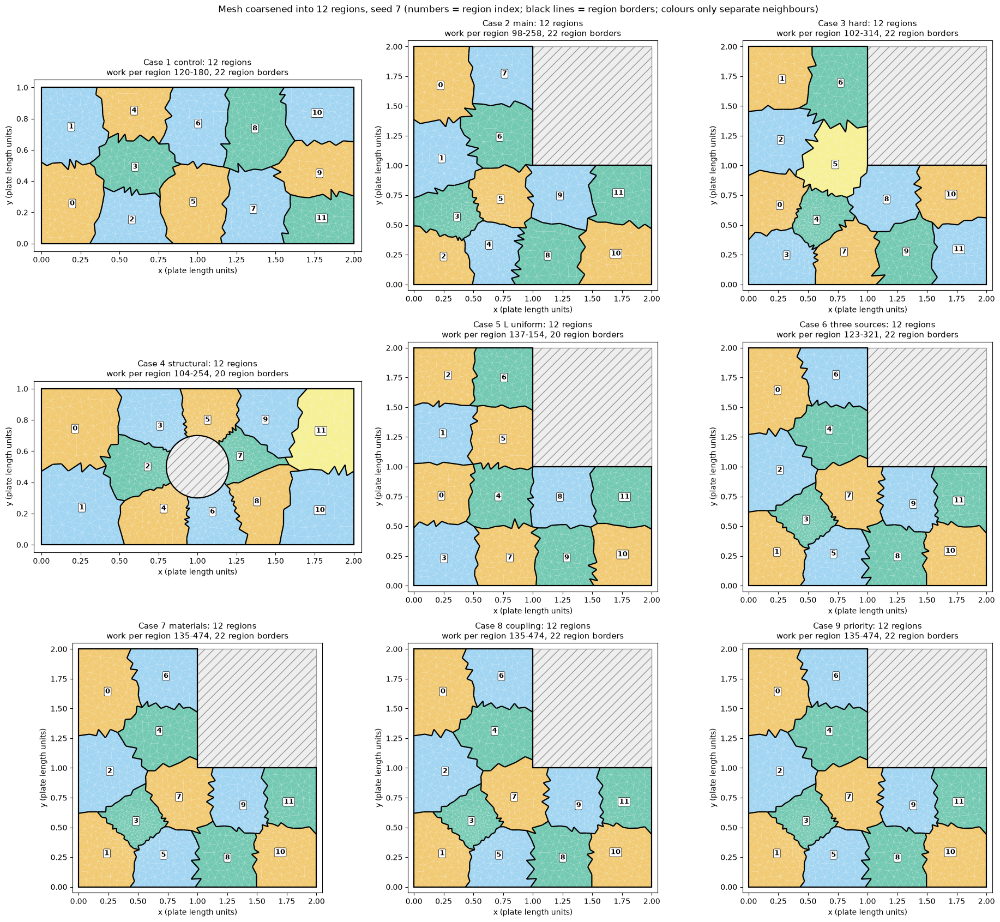

TASK 02 RESULT: all checks passed for 9 coarsenings (mode 'small': 9 cases x region counts [12] x seeds [7])
  case               n seed cells   work min/mean/max max/mean borders of all pairs cut-all cost empty fixed pieces moved (cells)
  1 control         12    7  1784   120 / 148.7 / 180     1.21      22         33%          154           0                0 (0)
  2 main            12    7  1670    98 / 139.2 / 258     1.85      22         33%          157           0                0 (0)
  3 hard            12    7  1802   102 / 150.2 / 314     2.09      22         33%          159           0                0 (0)
  4 structural      12    7  2166   104 / 180.5 / 254     1.41      20         30%          163           0                0 (0)
  5 L uniform       12    7  1724   137 / 143.7 / 154     1.07      20         30%          143           0                0 (0)
  6 three sources   12    7  1996   123 / 166.3 / 321     1.93      22         33%          169           0         

In [6]:
# TASK_02_IMPLEMENTATION_CELL_START
# Task 02: coarsen every benchmark mesh into n connected regions (one region = one qubit later).
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap
from matplotlib.patches import Polygon
from scipy.cluster.vq import kmeans2
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

KMEANS_ITERATIONS = 50        # k-means update steps (a setting, not tuned to any result)
MAX_KMEANS_RETRIES = 5        # extra deterministic k-means runs if a cluster comes out empty
REGION_PLOT_SEED = 7
REGIONS_RESULTS_DIR = Path("results")
# Okabe-Ito colour-blind-safe palette (without black); regions are identified by their printed index, not by colour
REGION_FILL_COLOURS = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]


def kmeans_region_labels(centroids, n, seed):
    """k-means on cell centroids. Returns (labels, n_retries, n_empty_fixed) with exactly n non-empty labels."""
    for attempt in range(MAX_KMEANS_RETRIES + 1):
        # attempt 0 uses the run's seed; retries use the deterministic seed sequence [seed, attempt]
        rng = np.random.default_rng(seed if attempt == 0 else [seed, attempt])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")           # the empty-cluster warning is handled explicitly below
            _, labels = kmeans2(centroids, n, iter=KMEANS_ITERATIONS, minit="++", rng=rng)
        if np.all(np.bincount(labels, minlength=n) > 0):
            return labels.astype(int), attempt, 0
    labels, n_fixed = fill_empty_regions(labels.astype(int), centroids, n)
    return labels, MAX_KMEANS_RETRIES, n_fixed


def fill_empty_regions(labels, centroids, n):
    """Last resort: give each missing label one cell, taken from the currently largest region
    (ties: smallest region index) - the cell farthest from that region's centroid (ties: smallest cell index)."""
    labels = labels.copy()
    n_fixed = 0
    for missing in np.flatnonzero(np.bincount(labels, minlength=n) == 0):
        donor = int(np.argmax(np.bincount(labels, minlength=n)))
        cells = np.flatnonzero(labels == donor)
        assert len(cells) > 1, "cannot fill an empty region: the largest region has one cell"
        dist = np.linalg.norm(centroids[cells] - centroids[cells].mean(axis=0), axis=1)
        labels[cells[int(np.argmax(dist))]] = missing
        n_fixed += 1
    return labels, n_fixed


def repair_region_connectivity(labels, adjacency_pairs, adjacency_matrix, n):
    """Make every region one connected piece: keep each region's largest piece and move every other piece
    to the neighbouring region sharing the most cell edges with it (ties: smallest region index).
    Every move lowers the total number of pieces by at least one, so the loop ends."""
    labels = labels.copy()
    n_pieces_moved = n_cells_moved = 0
    for _ in range(len(labels)):                       # far more rounds than can ever be needed
        moved_this_round = False
        for region in range(n):
            cells = np.flatnonzero(labels == region)
            n_comp, comp = connected_components(adjacency_matrix[cells][:, cells], directed=False)
            if n_comp == 1:
                continue
            keep = int(np.argmax(np.bincount(comp)))   # largest piece; ties -> first found
            for piece_id in range(n_comp):
                if piece_id == keep:
                    continue
                in_piece = np.zeros(len(labels), dtype=bool)
                in_piece[cells[comp == piece_id]] = True
                a, b = in_piece[adjacency_pairs[:, 0]], in_piece[adjacency_pairs[:, 1]]
                crossing = a ^ b
                outside_cell = np.where(a, adjacency_pairs[:, 1], adjacency_pairs[:, 0])[crossing]
                shared = np.bincount(labels[outside_cell], minlength=n)
                shared[region] = 0                     # (a piece never touches its own region's other pieces)
                if shared.max() == 0:
                    raise RuntimeError("a disconnected piece has no neighbouring region")
                labels[in_piece] = int(np.argmax(shared))
                n_pieces_moved += 1
                n_cells_moved += int(in_piece.sum())
                moved_this_round = True
        if not moved_this_round:
            return labels, n_pieces_moved, n_cells_moved
    raise RuntimeError("connectivity repair did not converge")


def region_piece_counts(labels, adjacency_matrix, n):
    """Number of connected pieces of each region (1 everywhere after a successful repair)."""
    counts = np.zeros(n, dtype=int)
    for region in range(n):
        cells = np.flatnonzero(labels == region)
        counts[region] = connected_components(adjacency_matrix[cells][:, cells], directed=False)[0] if len(cells) else 0
    return counts


def coarsen_mesh(mesh, n, seed):
    """Regions for one mesh: k-means labels, connectivity repair, then work and boundary weights."""
    centroids, pairs = mesh["cell_centroids"], mesh["adjacency_pairs"]
    labels, n_retries, n_empty_fixed = kmeans_region_labels(centroids, n, seed)
    labels, n_pieces_moved, n_cells_moved = repair_region_connectivity(labels, pairs, mesh["adjacency_matrix"], n)

    # Number the regions left to right (then bottom to top) so region indices mean something on the plot
    sums = np.stack([np.bincount(labels, weights=centroids[:, d], minlength=n) for d in (0, 1)], axis=1)
    region_centroids = sums / np.bincount(labels, minlength=n)[:, None]
    order = np.lexsort((region_centroids[:, 1], region_centroids[:, 0]))
    new_index = np.empty(n, dtype=int)
    new_index[order] = np.arange(n)
    cell_region, region_centroids = new_index[labels], region_centroids[order]

    # Work = summed triangle work (1 per triangle unless a case defines a heavy zone);
    # boundary = shared triangle edges between two different regions (count, summed cost, summed length)
    region_work = np.bincount(cell_region, weights=mesh["cell_work"], minlength=n)
    r_a, r_b = cell_region[pairs[:, 0]], cell_region[pairs[:, 1]]
    crossing = r_a != r_b
    key = np.minimum(r_a, r_b)[crossing] * n + np.maximum(r_a, r_b)[crossing]
    unique_key, inverse = np.unique(key, return_inverse=True)
    return dict(
        cell_region=cell_region, region_work=region_work, region_centroids=region_centroids,
        region_cells=np.bincount(cell_region, minlength=n),
        region_priority_work=np.bincount(cell_region, weights=mesh["cell_work"] * mesh["cell_priority"], minlength=n),
        region_pairs=np.stack([unique_key // n, unique_key % n], axis=1),
        region_boundary_count=np.bincount(inverse, minlength=len(unique_key)),
        region_boundary_cost=np.bincount(inverse, weights=mesh["adjacency_cost"][crossing], minlength=len(unique_key)),
        within_region_cost=float(mesh["adjacency_cost"][~crossing].sum()),
        region_boundary_length=np.bincount(inverse, weights=mesh["adjacency_weights"][crossing], minlength=len(unique_key)),
        n_within_region_edges=int(np.sum(~crossing)), boundary_cell_pairs=pairs[crossing],
        n_kmeans_retries=n_retries, n_empty_fixed=n_empty_fixed,
        n_repaired_pieces=n_pieces_moved, n_repaired_cells=n_cells_moved, mesh=mesh)


def check_region_case(key, result, n):
    """Task 02 acceptance checks for one (case, n, seed)."""
    mesh, cell_region = result["mesh"], result["cell_region"]
    n_cells, pairs = len(mesh["triangles"]), result["region_pairs"]
    assert cell_region.shape == (n_cells,) and cell_region.min() >= 0 and cell_region.max() < n, f"{key}: bad labels"
    assert len(np.unique(cell_region)) == n and np.all(result["region_cells"] > 0), f"{key}: not exactly {n} regions"
    assert np.all(result["region_work"] > 0) and result["region_cells"].sum() == n_cells, f"{key}: bad region sizes"
    assert np.all(region_piece_counts(cell_region, mesh["adjacency_matrix"], n) == 1), f"{key}: disconnected region"
    assert np.isclose(result["region_work"].sum(), mesh["cell_work"].sum()), f"{key}: region work does not sum to the total work"
    assert np.all(pairs[:, 0] < pairs[:, 1]) and len(np.unique(pairs, axis=0)) == len(pairs), f"{key}: bad region pairs"
    assert result["region_boundary_count"].sum() + result["n_within_region_edges"] == len(mesh["adjacency_pairs"]), \
        f"{key}: boundary accounting is not exact"
    assert np.isclose(result["region_boundary_cost"].sum() + result["within_region_cost"], mesh["adjacency_cost"].sum()), \
        f"{key}: border-cost accounting is not exact"
    assert np.all(result["region_boundary_count"] > 0) and np.all(result["region_boundary_length"] > 0), f"{key}: empty boundary"
    assert np.all(result["region_boundary_cost"] >= result["region_boundary_count"]), f"{key}: border cost below the edge count"
    assert np.isclose(result["region_boundary_length"].sum(),
                      mesh["adjacency_weights"][cell_region[mesh["adjacency_pairs"][:, 0]] != cell_region[mesh["adjacency_pairs"][:, 1]]].sum())
    region_graph = coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(n, n))
    assert connected_components(region_graph, directed=False)[0] == 1, f"{key}: region graph not connected"
    assert connected_components(mesh["adjacency_matrix"], directed=False)[0] == 1, f"{key}: cell graph not connected"


# ---- Coarsen every case, region count and seed from the run settings ----
region_meshes = {}                                      # (case, seed) -> mesh dict with weights
region_base_meshes = {}                                 # (mesh source, seed) -> checked mesh, built once
region_cases = {}                                       # (case, n, seed) -> coarsening result
for case_name in BENCHMARK_CASES:
    for run_seed in RUN["seeds"]:
        if run_seed == 7:
            region_meshes[(case_name, run_seed)] = mesh_cases[case_name]
        else:
            mesh_source = MESH_CASES[case_name].get("mesh_of", case_name)   # cases sharing a mesh build it once
            if (mesh_source, run_seed) not in region_base_meshes:
                new_points, new_triangles = build_case_mesh(MESH_CASES[mesh_source], run_seed)
                region_base_meshes[(mesh_source, run_seed)] = check_case_mesh(mesh_source, MESH_CASES[mesh_source], new_points, new_triangles)
            region_meshes[(case_name, run_seed)] = add_case_weights(MESH_CASES[case_name], region_base_meshes[(mesh_source, run_seed)])
        for region_count in RUN["region_counts"]:
            case_key = (case_name, region_count, run_seed)
            region_cases[case_key] = coarsen_mesh(region_meshes[(case_name, run_seed)], region_count, run_seed)
            check_region_case(case_key, region_cases[case_key], region_count)
            repeat = coarsen_mesh(region_meshes[(case_name, run_seed)], region_count, run_seed)
            assert np.array_equal(repeat["cell_region"], region_cases[case_key]["cell_region"]), f"{case_key}: not reproducible"

# ---- Plots: one figure per region count, one panel per case ----
REGIONS_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
region_plot_seed = REGION_PLOT_SEED if REGION_PLOT_SEED in RUN["seeds"] else RUN["seeds"][0]
region_plot_paths = []
for region_count in RUN["region_counts"]:
    n_cols = 3 if len(BENCHMARK_CASES) > 4 else 2
    n_rows = -(-len(BENCHMARK_CASES) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.3 * n_cols, 5.6 * n_rows), constrained_layout=True)
    for ax in axes.ravel()[len(BENCHMARK_CASES):]:
        ax.axis("off")
    for ax, case_name in zip(axes.ravel(), BENCHMARK_CASES):
        result = region_cases[(case_name, region_count, region_plot_seed)]
        mesh, spec, cell_region = result["mesh"], MESH_CASES[case_name], result["cell_region"]
        # Fill colours: greedy colouring of the region graph so neighbouring regions differ
        neighbours = [set() for _ in range(region_count)]
        for i, j in result["region_pairs"]:
            neighbours[i].add(j)
            neighbours[j].add(i)
        fill = np.full(region_count, -1)
        for region in range(region_count):
            used = {fill[other] for other in neighbours[region]}
            fill[region] = next(c for c in range(region_count) if c not in used)
        n_colours = len(REGION_FILL_COLOURS)
        ax.tripcolor(mesh["points"][:, 0], mesh["points"][:, 1], mesh["triangles"], facecolors=(fill % n_colours)[cell_region],
                     cmap=ListedColormap(REGION_FILL_COLOURS), vmin=-0.5, vmax=n_colours - 0.5, alpha=0.55,
                     edgecolors="white", linewidth=0.15)
        # Region borders: the mesh edge shared by each pair of cells that lie in different regions
        tri_a, tri_b = mesh["triangles"][result["boundary_cell_pairs"][:, 0]], mesh["triangles"][result["boundary_cell_pairs"][:, 1]]
        shared_vertices = tri_a[(tri_a[:, :, None] == tri_b[:, None, :]).any(axis=2)].reshape(-1, 2)
        ax.add_collection(LineCollection(mesh["points"][shared_vertices], colors="black", linewidths=1.6))
        for cut in spec["cutouts"]:
            ax.add_patch(Polygon(cut, closed=True, facecolor="#EEEEEE", edgecolor="#999999", hatch="//"))
        for loop in spec["loops"]:
            ax.add_patch(Polygon(loop, closed=True, fill=False, edgecolor="black", lw=1.6))
        for region in range(region_count):
            # label at the member cell closest to the region centroid, so it always sits inside its region
            cells = np.flatnonzero(cell_region == region)
            nearest = cells[np.argmin(np.linalg.norm(mesh["cell_centroids"][cells] - result["region_centroids"][region], axis=1))]
            ax.text(*mesh["cell_centroids"][nearest], str(region), ha="center", va="center", fontsize=9, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="black", lw=0.5))
        lo, hi = spec["hull"].min(axis=0), spec["hull"].max(axis=0)
        ax.set_xlim(lo[0] - 0.05, hi[0] + 0.05)
        ax.set_ylim(lo[1] - 0.05, hi[1] + 0.05)
        ax.set_aspect("equal")
        ax.set_xlabel("x (plate length units)")
        ax.set_ylabel("y (plate length units)")
        work = result["region_work"]
        ax.set_title(f"Case {case_name}: {region_count} regions\nwork per region {work.min():.0f}-{work.max():.0f}, "
                     f"{len(result['region_pairs'])} region borders", fontsize=11)
    fig.suptitle(f"Mesh coarsened into {region_count} regions, seed {region_plot_seed} "
                 f"(numbers = region index; black lines = region borders; colours only separate neighbours)", fontsize=12)
    region_plot_paths.append(REGIONS_RESULTS_DIR / f"regions_n{region_count}_seed{region_plot_seed}.png")
    fig.savefig(region_plot_paths[-1], dpi=90)
    plt.show()
    assert region_plot_paths[-1].exists()

# ---- Summary (only reached if every assertion above passed) ----
print(f"TASK 02 RESULT: all checks passed for {len(region_cases)} coarsenings (mode '{RUN_MODE}': "
      f"{len(BENCHMARK_CASES)} cases x region counts {RUN['region_counts']} x seeds {RUN['seeds']})")
print(f"  {'case':<17}{'n':>3}{'seed':>5}{'cells':>6}  {'work min/mean/max':>18}{'max/mean':>9}"
      f"{'borders':>8}{'of all pairs':>13}{'cut-all cost':>13}{'empty fixed':>12}{'pieces moved (cells)':>21}")
for (case_name, region_count, run_seed), result in region_cases.items():
    work, n_pairs = result["region_work"], region_count * (region_count - 1) // 2
    print(f"  {case_name:<17}{region_count:>3}{run_seed:>5}{result['region_cells'].sum():>6}  "
          f"{f'{work.min():.0f} / {work.mean():.1f} / {work.max():.0f}':>18}{work.max() / work.mean():>9.2f}"
          f"{len(result['region_pairs']):>8}{len(result['region_pairs']) / n_pairs:>12.0%} {result['region_boundary_cost'].sum():>12.0f}"
          f"{result['n_empty_fixed']:>12}{f'''{result['n_repaired_pieces']} ({result['n_repaired_cells']})''':>21}")
print(f"  k-means retries needed: {sum(r['n_kmeans_retries'] for r in region_cases.values())} in total")
print("  checks per row: exactly n non-empty regions, every region one connected piece, region graph connected,")
print("                  work sums to the total work, border count and cost accounting exact, same result on a second run")
print(f"  plots saved: {', '.join(str(p) for p in region_plot_paths)}")
# TASK_02_IMPLEMENTATION_CELL_END

## Task 02b — Region assignments as a data file

Same reason as Task 01d. `data/frozen_regions.npz` stores the cell → region labels for every mesh, region count and seed (12, 16, 20, 24 regions; seeds 7, 8, 9; the calibration meshes when Task 04 first meets them). A stored assignment is fed through the same Task 02 code, so region work and border costs are recomputed exactly, and all checks of Task 02 still apply.

In [7]:
# TASK_02B_IMPLEMENTATION_CELL_START
# Task 02b: freeze the region assignments as a data file (same reason as Task 01d: identical results on every machine).
# data/frozen_regions.npz maps "<mesh fingerprint>|<n>|<seed>" to the cell -> region labels. From here on, coarsen_mesh()
# uses a frozen assignment when one exists (Task 04 calibration meshes included) and saves any new one.
import numpy as np
from pathlib import Path

FROZEN_REGIONS_PATH = Path("data/frozen_regions.npz")
if "coarsen_mesh_computed" not in globals():              # keep the original (safe to re-run this cell)
    coarsen_mesh_computed = coarsen_mesh
frozen_regions = dict(np.load(FROZEN_REGIONS_PATH)) if FROZEN_REGIONS_PATH.exists() else {}
frozen_region_log = {"loaded": 0, "created": 0}


def region_key(mesh, n, seed):
    return f"{mesh_fingerprint(mesh['points'], mesh['triangles'])}|{n}|{seed}"


def coarsen_mesh(mesh, n, seed):
    """Frozen region assignment if one exists for this exact mesh, n and seed; otherwise k-means + repair, then saved.
    A frozen assignment is fed through the same code (as the k-means result), so work and borders are recomputed exactly."""
    key = region_key(mesh, n, seed)
    if key not in frozen_regions:
        result = coarsen_mesh_computed(mesh, n, seed)
        frozen_regions[key] = result["cell_region"].astype(np.int16)
        frozen_region_log["created"] += 1
        return result
    labels = frozen_regions[key].astype(int)
    original = globals()["kmeans_region_labels"]
    globals()["kmeans_region_labels"] = lambda centroids, n_regions, run_seed: (labels.copy(), 0, 0)
    try:
        result = coarsen_mesh_computed(mesh, n, seed)
    finally:
        globals()["kmeans_region_labels"] = original
    assert np.array_equal(result["cell_region"], labels), "frozen regions were changed by the repair or numbering"
    frozen_region_log["loaded"] += 1
    return result


# ---- the regions built by Task 02: save them if new, otherwise replace them by the frozen version ----
replaced = 0
for (case_name, n, seed), result in list(region_cases.items()):
    key = region_key(result["mesh"], n, seed)
    if key in frozen_regions and not np.array_equal(frozen_regions[key], result["cell_region"]):
        region_cases[(case_name, n, seed)] = coarsen_mesh(result["mesh"], n, seed)
        check_region_case((case_name, n, seed), region_cases[(case_name, n, seed)], n)
        replaced += 1
    elif key not in frozen_regions:
        frozen_regions[key] = result["cell_region"].astype(np.int16)
        frozen_region_log["created"] += 1

# ---- make sure the large-mode assignments exist as well (12, 16, 20, 24 regions; seeds 7, 8, 9) ----
for case_name in BENCHMARK_CASES:
    source = MESH_CASES[case_name].get("mesh_of", case_name)
    for seed in (7, 8, 9):
        if seed == 7:
            mesh = mesh_cases[case_name]
        else:
            points, triangles = build_case_mesh(MESH_CASES[source], seed)
            mesh = {"points": points, "triangles": triangles}
        for n in (12, 16, 20, 24):
            key = region_key(mesh, n, seed)
            if key not in frozen_regions:
                if seed != 7:
                    mesh = add_case_weights(MESH_CASES[case_name], check_case_mesh(source, MESH_CASES[source], mesh["points"], mesh["triangles"]))
                frozen_regions[key] = coarsen_mesh_computed(mesh, n, seed)["cell_region"].astype(np.int16)
                frozen_region_log["created"] += 1
np.savez_compressed(FROZEN_REGIONS_PATH, **frozen_regions)

# ---- checks ----
for key, result in region_cases.items():
    assert np.array_equal(result["cell_region"], frozen_regions[region_key(result["mesh"], key[1], key[2])])
assert FROZEN_REGIONS_PATH.stat().st_size < 2_000_000

print(f"TASK 02b RESULT: {len(frozen_regions)} frozen region assignments in {FROZEN_REGIONS_PATH} "
      f"({FROZEN_REGIONS_PATH.stat().st_size / 1e3:.0f} kB; {frozen_region_log['created']} created now, {replaced} replaced on this machine)")
print(f"  all {len(region_cases)} assignments of this run equal the frozen ones; every later coarsen_mesh() call loads them first")
# TASK_02B_IMPLEMENTATION_CELL_END

TASK 02b RESULT: 72 frozen region assignments in data/frozen_regions.npz (60 kB; 72 created now, 0 replaced on this machine)
  all 9 assignments of this run equal the frozen ones; every later coarsen_mesh() call loads them first


## Task 03 — Weighted Ising objective and exact reference

**Goal:** turn "which device gets which region" into an Ising energy that a later QAOA circuit can sample, and compute the exact answer of every small instance by checking all 2ⁿ splits.

**Why this matters:** QAOA only ever sees this energy. If the formula has a sign, weight or bit-order error, every later quantum result is wrong but still looks plausible. The exact answers computed here are the yardstick for all later methods.

**Objective** (spin `z_i = +1`: region on device A, `−1`: device B; bit `x_i = (1 − z_i)/2`):
`E(z) = cut + λ · balance + μ · priority`, with work shares `ã_i`, border costs `c̃_ij` and priority shares `p̃_i` normalised to sum 1:
- cut = Σ over neighbouring regions of `c̃_ij (1 − z_i z_j)/2`
- balance = `(Σ ã_i z_i − (1 − 2α))²` — zero when device B holds exactly the share α
- priority = `Σ p̃_i (1 + z_i)/2` — priority work left on the slow device (only where device B is faster and the case has a priority zone)

Basis: the Ising form of graph partitioning (Lucas, *Front. Phys.* 2014). The work weights, the target share α and the priority term are our extension.

**Fixed definitions:** balanced means `|Load_B/W − α| ≤ 0.05`; the *constrained reference* is the cheapest cut among balanced splits; `λ` and `μ` are shared values picked from fixed grids (never per instance) and validated by enumeration; sizes above 22 regions are not enumerated.

**Acceptance checks:** Ising energy = directly computed cost (random vectors on every instance, all states on enumerated ones); bit-order helper; flip symmetry only at α = 0.5; every pair of regions coupled; optimum balanced at the selected λ; exceptions (optimum ≠ constrained reference) listed, not hidden.

**Output:** `ising_cases[(case, n, seed, scenario)]` and the compact list `ising_summary`.

**Scope limit:** no QAOA circuit, no IonQ call, no classical heuristics, no refinement, no runtime model. All numbers here are exact enumeration of the model objective, not hardware or runtime measurements.

Task 03: 18 instances (18 exact by enumeration, 0 too large for it); retained energy arrays need about 0.6 MB


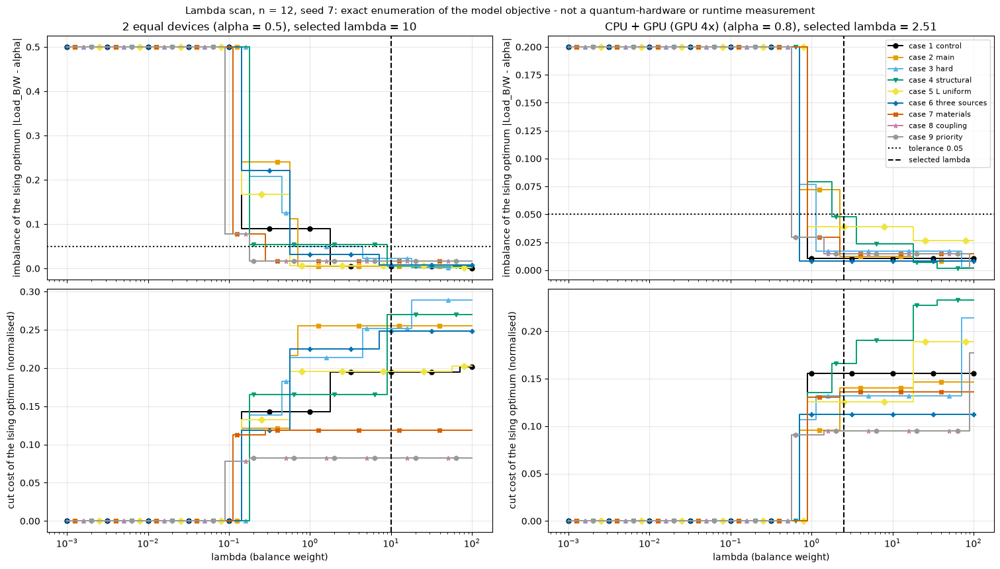

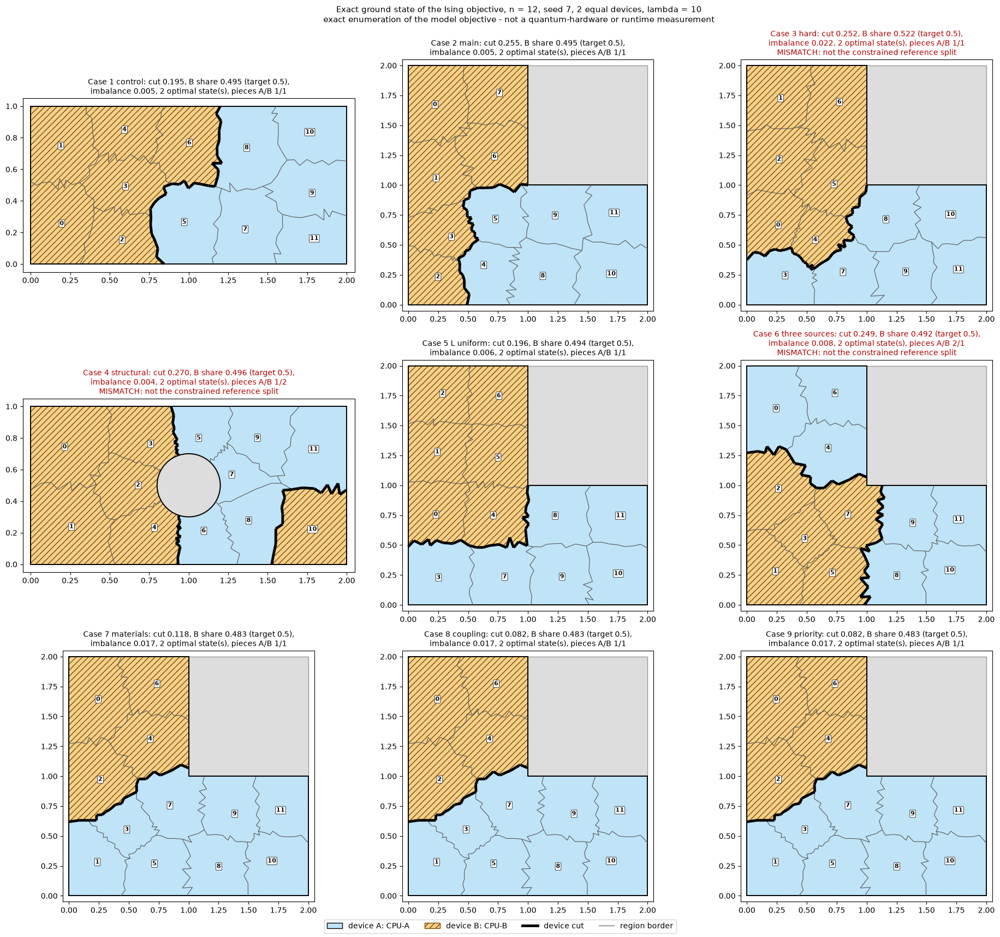

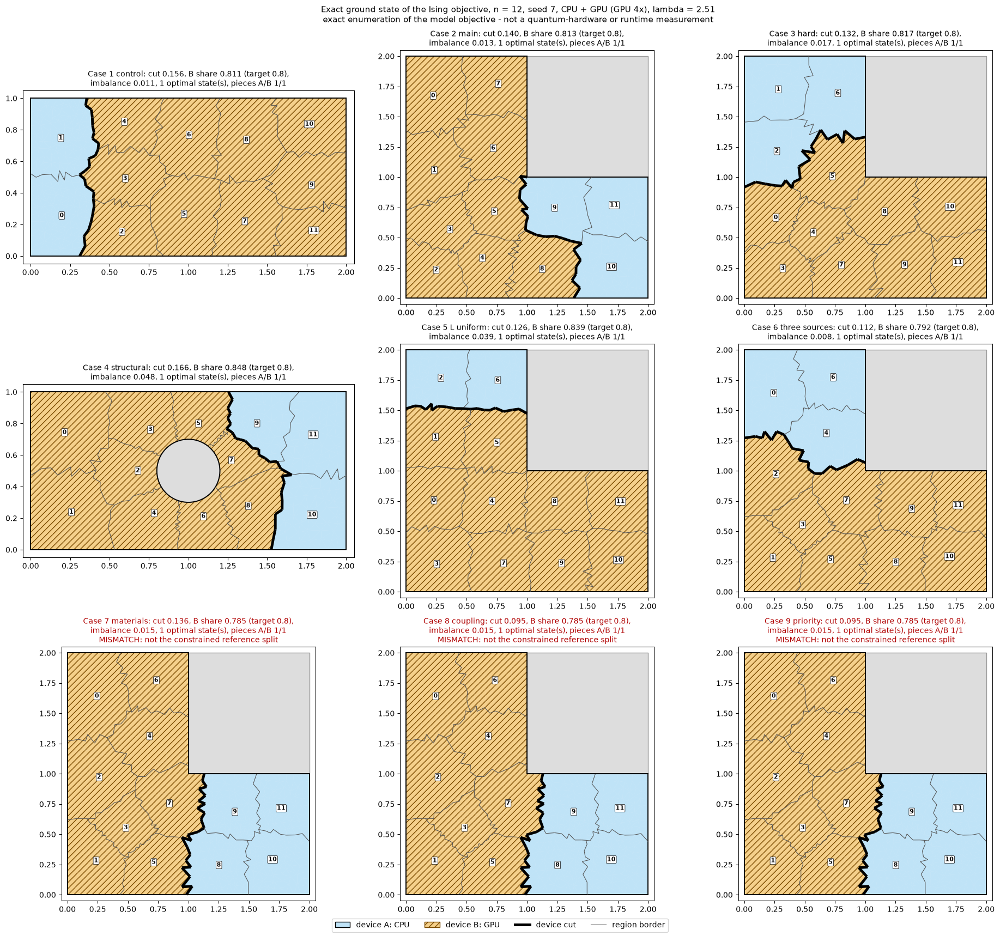

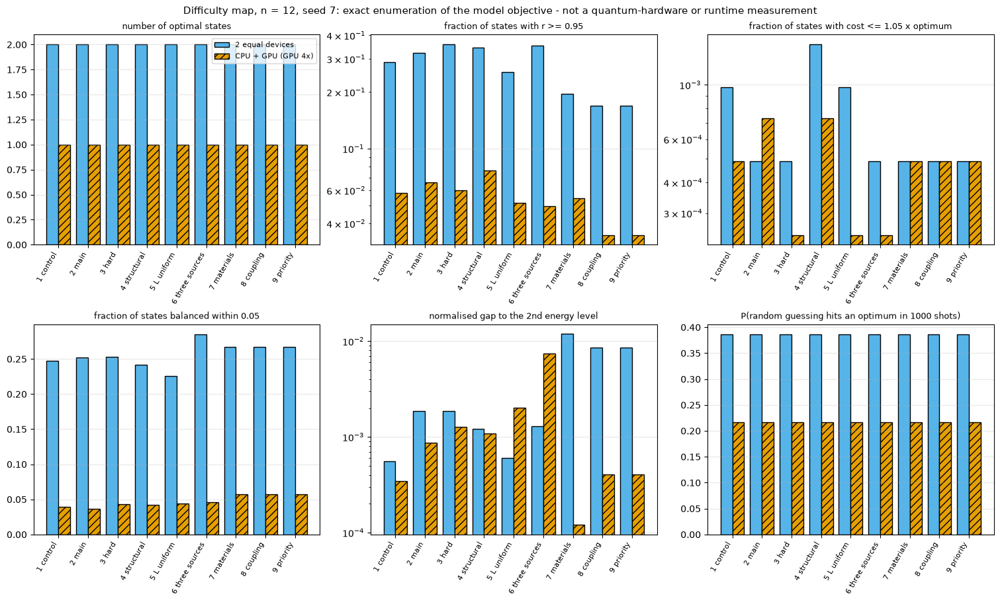

TASK 03 RESULT: 18 Ising instances built (mode 'small'); 18 solved exactly by enumeration, 0 skipped (n > 22)
  lambda grid: 51 values from 0.001 to 100 (geometric); mu grid: 101 values from 0 to 20; balance tolerance 0.05
  lambda selection: per scenario
    2 equal devices: lambda = 10 (every instance balanced; reference matched where possible); balanced 9/9, equal to reference 6/9; no lambda makes all instances compliant; all balanced for lambda in 10 to 100
    CPU + GPU (GPU 4x): lambda = 2.512 (every instance balanced; reference matched where possible); balanced 9/9, equal to reference 6/9; no lambda makes all instances compliant; all balanced for lambda in 2.512 to 100
  mu = 0 for case 9 in the CPU+GPU scenario: smallest grid value that puts all feasible priority work on the fast device in 1/1 exact instance(s); works for all: True; lambda re-validated with this mu: converged
  case              n seed scenario alpha  lambda   mu    E_min #opt    cut  prio B share imbal. status

In [8]:
# TASK_03_IMPLEMENTATION_CELL_START
# Task 03: weighted Ising objective (cut + balance + optional priority), exact reference by enumeration,
# shared lambda / mu selection, difficulty measures and plots. No QAOA circuit and no heuristics here.
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

ISING_EPSILON = 0.05                         # balance tolerance on |Load_B / W - alpha| (value used by IonQ + Synopsys, arXiv 2603.15515)
ISING_TOL = 1e-9                             # tolerance for energy ties and identities
LAMBDA_GRID = np.geomspace(1e-3, 1e2, 51)    # fixed grid for the balance weight (normalised units)
MU_GRID = np.linspace(0.0, 20.0, 101)        # fixed grid for the priority weight
MAX_SELECTION_ROUNDS = 5                     # lambda <-> mu re-validation rounds
N_RANDOM_TESTS = 100                         # random spin vectors per instance for the identity test
ISING_TEST_SEED = 2026
RETAIN_ENERGY_MAX_QUBITS = LOCAL_STATEVECTOR_MAX_QUBITS
ISING_PLOT_N, ISING_PLOT_SEED = 12, 7
ISING_RESULTS_DIR = Path("results")
SCENARIO_SLUGS = {"2 equal devices": "equal", "CPU + GPU (GPU 4x)": "cpu_gpu"}


# ---------------------------------------------------------------- objective ----
def build_partition_ising(region_work, region_pairs, pair_cost, alpha, lam, priority_work=None, mu=0.0, regions=None):
    """Ising form E(z) = sum_{i<j} J_ij z_i z_j + sum_i h_i z_i + const of
    cut + lam * balance + mu * priority, for z_i = +1 (device A) / -1 (device B).
    `regions` restricts the problem to a subset of regions (for later recursive splits).
    Basis: Ising graph partitioning (Lucas, Front. Phys. 2014); weights, target share and priority are our extension."""
    work = np.asarray(region_work, dtype=float)
    pairs = np.asarray(region_pairs, dtype=int).reshape(-1, 2)
    cost = np.asarray(pair_cost, dtype=float)
    prio = np.zeros(len(work)) if priority_work is None else np.asarray(priority_work, dtype=float)
    if regions is not None:
        regions = np.asarray(regions, dtype=int)
        position = np.full(len(work), -1)
        position[regions] = np.arange(len(regions))
        keep = (position[pairs[:, 0]] >= 0) & (position[pairs[:, 1]] >= 0)
        pairs, cost = np.sort(position[pairs[keep]], axis=1), cost[keep]
        work, prio = work[regions], prio[regions]
    n, total_work, total_cost = len(work), work.sum(), cost.sum()
    assert total_work > 0, "total work must be positive"
    degenerate_cut = not total_cost > 0                  # no borders at all: the cut term is identically zero
    a, p = work / total_work, prio / total_work
    c = np.zeros(len(cost)) if degenerate_cut else cost / total_cost
    target = 1.0 - 2.0 * alpha                           # balance is reached when sum_i a_i z_i = 1 - 2 alpha
    J = np.triu(2.0 * lam * np.outer(a, a), k=1)
    np.subtract.at(J, (pairs[:, 0], pairs[:, 1]), c / 2.0)
    h = -2.0 * lam * target * a + mu * p / 2.0
    const = c.sum() / 2.0 + lam * (np.sum(a**2) + target**2) + mu * p.sum() / 2.0
    scale = max(np.abs(J).max(initial=0.0), np.abs(h).max(initial=0.0))
    safe_scale = scale if scale > 0 else 1.0             # all-zero objective: leave J and h at zero
    return dict(n=n, J=J, h=h, const=const, scale=scale, J_scaled=J / safe_scale, h_scaled=h / safe_scale,
                a_tilde=a, p_tilde=p, pairs=pairs, c_tilde=c, W=total_work, total_boundary_cost=total_cost,
                degenerate_cut=degenerate_cut, alpha=alpha, lam=lam, mu=mu)


def direct_cost_parts(z, model):
    """Cut, balance and priority-on-slow-device cost of one spin vector, computed WITHOUT the Ising formula."""
    z = np.asarray(z, dtype=float)
    i, j = model["pairs"][:, 0], model["pairs"][:, 1]
    cut = np.sum(model["c_tilde"] * (1.0 - z[i] * z[j]) / 2.0)
    balance = (model["a_tilde"] @ z - (1.0 - 2.0 * model["alpha"])) ** 2
    priority = np.sum(model["p_tilde"] * (1.0 + z) / 2.0)
    return cut, balance, priority


def direct_cost(z, model):
    cut, balance, priority = direct_cost_parts(z, model)
    return cut + model["lam"] * balance + model["mu"] * priority


def ising_energy(z, J, h, const):
    z = np.asarray(z, dtype=float)
    return z @ J @ z + h @ z + const


def count_key_to_spins(key):
    """Qiskit count key -> (x, z) in region order. The RIGHTMOST character is qubit/region 0."""
    x = np.array([int(bit) for bit in key.replace(" ", "")[::-1]])
    return x, 1 - 2 * x


def state_index_to_x(k, n):
    """State index k -> bits x (region order): x_i = (k >> i) & 1, and z_i = 1 - 2 x_i."""
    return (np.asarray(k, dtype=np.int64)[..., None] >> np.arange(n)) & 1


def device_piece_counts(x, region_pairs):
    """Number of connected pieces of device A and of device B in the region graph for a split x (1 = device B)."""
    x, pairs = np.asarray(x), np.asarray(region_pairs)
    same = pairs[x[pairs[:, 0]] == x[pairs[:, 1]]]                 # keep only borders inside one device
    graph = coo_matrix((np.ones(len(same)), (same[:, 0], same[:, 1])), shape=(len(x), len(x)))
    labels = connected_components(graph, directed=False)[1]
    return len(np.unique(labels[x == 0])), len(np.unique(labels[x == 1]))


# -------------------------------------------------------------- enumeration ----
def subset_sums(values):
    """sums[k] = sum of values[i] over the set bits i of k, for all k < 2^n."""
    sums = np.zeros(1)
    for value in values:
        sums = np.concatenate([sums, sums + value])
    return sums


def enumerate_components(model):
    """For all 2^n states: cut cost, share of work on device B, priority work on the slow device A."""
    n = model["n"]
    k = np.arange(2**n, dtype=np.int64)
    cut = np.zeros(2**n)
    for (i, j), c in zip(model["pairs"], model["c_tilde"]):
        cut += c * (((k >> i) ^ (k >> j)) & 1)
    return cut, subset_sums(model["a_tilde"]), model["p_tilde"].sum() - subset_sums(model["p_tilde"])


def ising_energies_all(J, h, const, n, chunk_bits=15):
    """Ising energy of every state, computed from J and h in chunks (no (2^n, n) matrix is kept)."""
    energies = np.empty(2**n)
    for start in range(0, 2**n, 2**chunk_bits):
        stop = min(start + 2**chunk_bits, 2**n)
        z = 1.0 - 2.0 * state_index_to_x(np.arange(start, stop), n)
        energies[start:stop] = np.sum((z @ J) * z, axis=1) + z @ h + const
    return energies


def instance_inputs(case_name, n, seed, scenario):
    """Region data, alpha and whether the priority term is active (priority work exists AND device B is faster)."""
    regions = region_cases[(case_name, n, seed)]
    speed_a, speed_b = DEVICE_SCENARIOS[scenario].values()
    priority_active = bool(regions["region_priority_work"].sum() > 0 and speed_b > speed_a)
    return regions, TARGET_SHARES[scenario], priority_active


def instance_arrays(case_name, n, seed, scenario, mu):
    """Enumerated arrays of one instance plus its balance-feasible set and constrained reference."""
    regions, alpha, _ = instance_inputs(case_name, n, seed, scenario)
    base = build_partition_ising(regions["region_work"], regions["region_pairs"], regions["region_boundary_cost"], alpha,
                                 lam=0.0, priority_work=regions["region_priority_work"])
    cut, share_b, prio_slow = enumerate_components(base)
    imbalance = np.abs(share_b - alpha)
    delta_star = imbalance.min()
    feasible_exists = bool(delta_star <= ISING_EPSILON)
    # no 5%-balanced split at all -> fall back to the splits closest to the target, and say so
    feasible = imbalance <= (ISING_EPSILON if feasible_exists else delta_star + ISING_TOL)
    balance_term = 4.0 * (alpha - share_b) ** 2            # = (sum_i a_i z_i - (1 - 2 alpha))^2
    reference_objective = cut + mu * prio_slow            # pure cut when mu = 0, priority-aware otherwise
    return dict(cut=cut, share_b=share_b, prio_slow=prio_slow, imbalance=imbalance, balance_term=balance_term,
                delta_star=delta_star, feasible=feasible, feasible_exists=feasible_exists,
                reference_objective=reference_objective, reference_value=reference_objective[feasible].min(),
                pure_cut_reference=cut[feasible].min())


def scan_lambda(arrays, mu):
    """Ground state of cut + lam * balance + mu * priority for every lam on the grid."""
    n_lam = len(LAMBDA_GRID)
    record = dict(mu=mu, e_min=np.zeros(n_lam), n_ground=np.zeros(n_lam, int), imbalance_max=np.zeros(n_lam),
                  cut_min=np.zeros(n_lam), balanced=np.zeros(n_lam, bool), matches_reference=np.zeros(n_lam, bool))
    fixed_part = arrays["cut"] + mu * arrays["prio_slow"]
    for index, lam in enumerate(LAMBDA_GRID):
        energy = fixed_part + lam * arrays["balance_term"]
        ground = np.flatnonzero(energy <= energy.min() + ISING_TOL)
        record["e_min"][index], record["n_ground"][index] = energy[ground[0]], len(ground)
        record["imbalance_max"][index] = arrays["imbalance"][ground].max()
        record["cut_min"][index] = arrays["cut"][ground].min()
        record["balanced"][index] = arrays["feasible"][ground].all()
        record["matches_reference"][index] = record["balanced"][index] and np.all(
            arrays["reference_objective"][ground] <= arrays["reference_value"] + ISING_TOL)
    return record


def select_shared_lambda(keys, records):
    """One lambda for a group of instances. Rule: (1) smallest lambda where every instance is balanced AND matches
    its constrained reference; else (2) among lambdas that balance every instance, the one matching most references
    (ties: smallest lambda); else (3) the lambda with most compliant instances (ties: smallest lambda)."""
    balanced = np.array([records[key]["balanced"] for key in keys])
    compliant = balanced & np.array([records[key]["matches_reference"] for key in keys])
    all_compliant, all_balanced = compliant.all(axis=0), balanced.all(axis=0)
    if all_compliant.any():
        index, rule = int(np.argmax(all_compliant)), "every instance balanced and equal to its constrained reference"
    elif all_balanced.any():
        candidates = np.where(all_balanced, compliant.sum(axis=0), -1)
        index, rule = int(np.argmax(candidates)), "every instance balanced; reference matched where possible"
    else:
        index, rule = int(np.argmax(compliant.sum(axis=0))), "NO lambda balances every instance; most compliant instances"
    return dict(index=index, lam=float(LAMBDA_GRID[index]), rule=rule, n_instances=len(keys),
                n_balanced=int(balanced[:, index].sum()), n_compliant=int(compliant[:, index].sum()),
                compliant_window=LAMBDA_GRID[all_compliant], balanced_window=LAMBDA_GRID[all_balanced])


def choose_lambdas(keys, records):
    """Prefer one global lambda; otherwise one per scenario. Never per instance."""
    overall = select_shared_lambda(keys, records)
    if overall["n_compliant"] == overall["n_instances"]:
        return "global", {scenario: overall for scenario in TARGET_SHARES}
    return "per scenario", {scenario: select_shared_lambda([key for key in keys if key[3] == scenario], records)
                            for scenario in TARGET_SHARES}


def select_shared_mu(keys, lam):
    """Smallest mu for which every priority instance's optimum is balanced and has the lowest priority-on-slow
    cost that any balanced split can reach; otherwise the mu with most successes (ties: smallest mu)."""
    success = np.zeros((len(keys), len(MU_GRID)), bool)
    for row, key in enumerate(keys):
        arrays = instance_arrays(*key, mu=0.0)
        priority_floor = arrays["prio_slow"][arrays["feasible"]].min()
        for index, mu in enumerate(MU_GRID):
            energy = arrays["cut"] + lam * arrays["balance_term"] + mu * arrays["prio_slow"]
            ground = np.flatnonzero(energy <= energy.min() + ISING_TOL)
            success[row, index] = arrays["feasible"][ground].all() and np.all(arrays["prio_slow"][ground] <= priority_floor + ISING_TOL)
    all_success = success.all(axis=0)
    index = int(np.argmax(all_success)) if all_success.any() else int(np.argmax(success.sum(axis=0)))
    return dict(index=index, mu=float(MU_GRID[index]), n_instances=len(keys), n_success=int(success[:, index].sum()),
                works_for_all=bool(all_success.any()), success_window=MU_GRID[all_success])


# ------------------------------------------------- lambda / mu selection ----
all_instance_keys = [(case_name, n, seed, scenario) for (case_name, n, seed) in region_cases for scenario in TARGET_SHARES]
exact_keys = [key for key in all_instance_keys if key[1] <= EXACT_BRUTE_FORCE_MAX_QUBITS]
priority_keys = [key for key in exact_keys if instance_inputs(*key)[2]]
retained_bytes = sum(8 * 2 ** key[1] for key in exact_keys if key[1] <= RETAIN_ENERGY_MAX_QUBITS)
print(f"Task 03: {len(all_instance_keys)} instances ({len(exact_keys)} exact by enumeration, "
      f"{len(all_instance_keys) - len(exact_keys)} too large for it); retained energy arrays need about {retained_bytes / 1e6:.1f} MB")

lambda_records = {key: scan_lambda(instance_arrays(*key, mu=0.0), mu=0.0) for key in exact_keys}
selected_mu, mu_choice, selection_converged = 0.0, None, True
lambda_mode, lambda_choice = choose_lambdas(exact_keys, lambda_records)
if priority_keys:
    selection_converged = False
    for selection_round in range(1, MAX_SELECTION_ROUNDS + 1):
        priority_scenarios = sorted({key[3] for key in priority_keys})
        assert len(priority_scenarios) == 1, "one shared mu is defined for a single priority scenario"
        mu_choice = select_shared_mu(priority_keys, lambda_choice[priority_scenarios[0]]["lam"])
        selected_mu = mu_choice["mu"]
        for key in priority_keys:                         # re-validate lambda with the priority term switched on
            lambda_records[key] = scan_lambda(instance_arrays(*key, mu=selected_mu), mu=selected_mu)
        new_mode, new_choice = choose_lambdas(exact_keys, lambda_records)
        unchanged = all(new_choice[s]["index"] == lambda_choice[s]["index"] for s in TARGET_SHARES)
        lambda_mode, lambda_choice = new_mode, new_choice
        if unchanged:
            selection_converged = True
            break


def instance_parameters(key):
    """Selected (lam, mu) of an instance: shared lambda of its scenario, mu only where the priority term is active."""
    return lambda_choice[key[3]]["lam"], (selected_mu if instance_inputs(*key)[2] else 0.0)


# ----------------------------------------------------------- final instances ----
ISING_REQUIRED_KEYS = [
    "J", "h", "const", "J_scaled", "h_scaled", "scale", "alpha", "lam", "mu", "scenario_name", "case_name", "n", "seed",
    "W", "total_boundary_cost", "delta_star", "epsilon", "balance_status", "E_min", "E_max", "optimal_z", "optimal_x",
    "optimal_bits_region_order", "optimal_cut_cost", "optimal_priority_cost", "optimal_imbalance", "optimal_load_a",
    "optimal_load_b", "pure_cut_reference", "priority_aware_reference", "energy_levels", "normalized_gap", "n_optimal",
    "fraction_within_5pct", "balanced_fraction", "random_hit_probability", "lambda_scan", "lambda_window", "lambda_status",
    "energies", "brute_force", "matches_reference", "priority_active", "n_pair_terms", "n_nonzero_pair_terms", "optimal_pieces",
    "fraction_cost_within_5pct"]
ising_cases, ising_summary = {}, []
ising_tests = dict(identity=0, enumeration=0, chunk_subset=0, symmetric=0, asymmetric=0, balanced=0, reference=0,
                   all_pairs=0, subset_builder=0)
ising_exceptions = []
test_rng = np.random.default_rng(ISING_TEST_SEED)
for key in all_instance_keys:
    case_name, n, seed, scenario = key
    regions, alpha, priority_active = instance_inputs(*key)
    lam, mu = instance_parameters(key)
    model = build_partition_ising(regions["region_work"], regions["region_pairs"], regions["region_boundary_cost"], alpha,
                                  lam=lam, priority_work=regions["region_priority_work"], mu=mu)
    J, h, const = model["J"], model["h"], model["const"]

    # Test 1: Ising energy == direct cost for random spin vectors (also done for sizes without enumeration)
    for z in 1 - 2 * test_rng.integers(0, 2, size=(N_RANDOM_TESTS, n)):
        assert abs(ising_energy(z, J, h, const) - direct_cost(z, model)) < ISING_TOL, f"{key}: Ising energy != direct cost"
    ising_tests["identity"] += 1
    # Test 6: every pair carries a coupling
    n_pairs = n * (n - 1) // 2
    n_nonzero = int(np.count_nonzero(J[np.triu_indices(n, k=1)]))
    assert n_nonzero == n_pairs or lam == 0, f"{key}: {n_pairs - n_nonzero} pair couplings cancel to exactly zero"
    ising_tests["all_pairs"] += 1

    entry = dict(J=J, h=h, const=const, J_scaled=model["J_scaled"], h_scaled=model["h_scaled"], scale=model["scale"],
                 alpha=alpha, lam=lam, mu=mu, scenario_name=scenario, case_name=case_name, n=n, seed=seed,
                 W=model["W"], total_boundary_cost=model["total_boundary_cost"], epsilon=ISING_EPSILON,
                 priority_active=priority_active, n_pair_terms=n_pairs, n_nonzero_pair_terms=n_nonzero, model=model,
                 lambda_status=f"{lambda_mode}: {lambda_choice[scenario]['rule']}",
                 state_index_convention="state index k: x_i = (k >> i) & 1 (1 = device B), z_i = 1 - 2 x_i")
    if n > EXACT_BRUTE_FORCE_MAX_QUBITS:
        # too large for enumeration: lambda/mu are the shared values chosen on the exact-solvable instances
        skipped = f"skipped (n = {n} > {EXACT_BRUTE_FORCE_MAX_QUBITS}); reference will come from Task 04"
        entry.update({name: None for name in ISING_REQUIRED_KEYS if name not in entry}, brute_force=skipped,
                     balance_status="not exhaustively validated")
    else:
        arrays = instance_arrays(*key, mu=mu)
        energies = ising_energies_all(J, h, const, n)
        # Test 2: chunked Ising energies == component formula for ALL states, and == single-state function on a subset
        assert np.max(np.abs(energies - (arrays["cut"] + lam * arrays["balance_term"] + mu * arrays["prio_slow"]))) < ISING_TOL
        ising_tests["enumeration"] += 1
        for k in test_rng.integers(0, 2**n, size=N_RANDOM_TESTS):
            assert abs(energies[k] - ising_energy(1 - 2 * state_index_to_x(k, n), J, h, const)) < ISING_TOL
        ising_tests["chunk_subset"] += 1
        # Test 4: flipping every spin leaves the energy unchanged only for alpha = 0.5 without priority
        if alpha == 0.5 and mu == 0:
            assert np.allclose(energies, energies[::-1], atol=ISING_TOL), f"{key}: E(z) != E(-z) at alpha = 0.5"
            ising_tests["symmetric"] += 1
        else:
            assert np.any(h != 0) and not np.allclose(energies, energies[::-1], atol=ISING_TOL), f"{key}: unexpected symmetry"
            ising_tests["asymmetric"] += 1

        e_min, e_max = energies.min(), energies.max()
        ground = np.flatnonzero(energies <= e_min + ISING_TOL)
        above = energies[energies > e_min + ISING_TOL]
        second_level = above.min() if len(above) else e_min
        spread = e_max - e_min
        # approximation ratio r = (E_max - E) / (E_max - E_min); if all energies are equal, r = 1 for every state
        ratio = (e_max - energies) / spread if spread > 0 else np.ones_like(energies)
        optimal_x = state_index_to_x(ground, n)
        balanced_optimum = bool(arrays["feasible"][ground].all())
        matches = bool(balanced_optimum and np.all(arrays["reference_objective"][ground] <= arrays["reference_value"] + ISING_TOL))
        reference_state = int(np.flatnonzero(arrays["feasible"] & (arrays["reference_objective"] <= arrays["reference_value"] + ISING_TOL))[0])
        pure_state = int(np.flatnonzero(arrays["feasible"] & (arrays["cut"] <= arrays["pure_cut_reference"] + ISING_TOL))[0])
        def describe(state):
            return dict(state_index=state, bits_region_order="".join(map(str, state_index_to_x(state, n))),
                        cut_cost=float(arrays["cut"][state]), priority_cost=float(arrays["prio_slow"][state]),
                        imbalance=float(arrays["imbalance"][state]), share_b=float(arrays["share_b"][state]))
        scan = lambda_records[key]
        compliant = scan["balanced"] & scan["matches_reference"]
        entry.update(
            E_min=float(e_min), E_max=float(e_max), n_optimal=len(ground), optimal_state_indices=ground,
            optimal_x=optimal_x, optimal_z=1 - 2 * optimal_x,
            optimal_bits_region_order=["".join(map(str, bits)) for bits in optimal_x],          # character i = region i
            optimal_count_keys=["".join(map(str, bits[::-1])) for bits in optimal_x],           # Qiskit style: rightmost = region 0
            optimal_cut_cost=arrays["cut"][ground], optimal_priority_cost=arrays["prio_slow"][ground],
            optimal_imbalance=arrays["imbalance"][ground], optimal_load_b=arrays["share_b"][ground] * model["W"],
            optimal_load_a=(1.0 - arrays["share_b"][ground]) * model["W"],
            delta_star=float(arrays["delta_star"]), feasible_set_empty=not arrays["feasible_exists"],
            balance_status=("balanced" if arrays["feasible_exists"] else "fallback: closest to target") if balanced_optimum else "NOT balanced",
            matches_reference=matches, pure_cut_reference=describe(pure_state),
            priority_aware_reference=describe(reference_state) if priority_active else None,
            energy_levels=(float(e_min), float(second_level)), normalized_gap=float((second_level - e_min) / spread) if spread > 0 else 0.0,
            fraction_within_5pct=float(np.mean(ratio >= 0.95)),
            # stricter: E equals the non-negative direct cost, so "cost at most 5 % above the optimum" is well defined
            fraction_cost_within_5pct=float(np.mean(energies <= 1.05 * e_min)), balanced_fraction=float(np.mean(arrays["imbalance"] <= ISING_EPSILON)),
            random_hit_probability=float(1.0 - (1.0 - len(ground) / 2**n) ** RUN["shots"]),
            lambda_scan=dict(scan, lambda_grid=LAMBDA_GRID),
            lambda_window=(float(LAMBDA_GRID[compliant].min()), float(LAMBDA_GRID[compliant].max()), int(compliant.sum())) if compliant.any() else None,
            energies=energies if n <= RETAIN_ENERGY_MAX_QUBITS else None, brute_force="done",
            optimal_pieces=[device_piece_counts(bits, regions["region_pairs"]) for bits in optimal_x])
        # Test 5: balance and reference agreement at the selected lambda (exceptions are reported, not hidden)
        ising_tests["balanced"] += balanced_optimum
        ising_tests["reference"] += matches
        if not balanced_optimum or not matches or not arrays["feasible_exists"]:
            ising_exceptions.append((key, entry["balance_status"], matches, float(arrays["delta_star"]),
                                     float(arrays["cut"][ground[0]]), float(arrays["imbalance"][ground[0]]),
                                     float(arrays["cut"][reference_state]), float(arrays["imbalance"][reference_state])))
    assert all(name in entry for name in ISING_REQUIRED_KEYS), f"{key}: missing keys"       # Test 9
    ising_cases[key] = entry
    ising_summary.append({name: entry[name] for name in ("case_name", "n", "seed", "scenario_name", "alpha", "lam", "mu",
                          "brute_force", "E_min", "n_optimal", "delta_star", "balance_status", "matches_reference",
                          "fraction_within_5pct", "fraction_cost_within_5pct", "balanced_fraction", "normalized_gap",
                          "random_hit_probability", "n_pair_terms", "scale")})

# Test 3: count-key bit order - the RIGHTMOST character is region 0
bit_x, bit_z = count_key_to_spins("0 011")
assert bit_x.tolist() == [1, 1, 0, 0] and bit_z.tolist() == [-1, -1, 1, 1], "bit-order helper is wrong"
assert count_key_to_spins("1000")[0].tolist() == [0, 0, 0, 1] and state_index_to_x(1, 4).tolist() == [1, 0, 0, 0]
# Builder on a subset of regions == builder on the hand-restricted problem (needed later for recursive splits)
subset_source = region_cases[(BENCHMARK_CASES[0], RUN["region_counts"][0], RUN["seeds"][0])]
subset_regions = np.arange(0, RUN["region_counts"][0], 2)
subset_model = build_partition_ising(subset_source["region_work"], subset_source["region_pairs"], subset_source["region_boundary_cost"],
                                     0.8, lam=1.0, regions=subset_regions)
for z in 1 - 2 * test_rng.integers(0, 2, size=(N_RANDOM_TESTS, len(subset_regions))):
    assert abs(ising_energy(z, subset_model["J"], subset_model["h"], subset_model["const"]) - direct_cost(z, subset_model)) < ISING_TOL
assert np.isclose(subset_model["W"], subset_source["region_work"][subset_regions].sum())
ising_tests["subset_builder"] += 1

# Test 7: case 1 control at alpha = 0.5 - is the exact optimum a left/right split? (reported, not forced)
control_key = ("1 control", ISING_PLOT_N, ISING_PLOT_SEED, "2 equal devices")
control_report = "not in this run"
if control_key in ising_cases and ising_cases[control_key]["brute_force"] == "done":
    control_bits = ising_cases[control_key]["optimal_bits_region_order"]
    strict_pattern = all(np.count_nonzero(np.diff([int(b) for b in bits])) == 1 for bits in control_bits)
    # geometric check: are the two devices' region centroids separated by one straight line, and how is it oriented?
    control_centroids = region_cases[control_key[:3]]["region_centroids"]
    control_x = ising_cases[control_key]["optimal_x"][0].astype(bool)
    direction = control_centroids[control_x].mean(axis=0) - control_centroids[~control_x].mean(axis=0)
    direction /= np.linalg.norm(direction)
    projection = control_centroids @ direction
    separable = bool(projection[control_x].min() > projection[~control_x].max())
    tilt = float(np.degrees(np.arctan2(abs(direction[1]), abs(direction[0]))))
    control_report = (f"optimal bits (region order, left to right): {', '.join(control_bits)}; exact 000000111111 pattern: {strict_pattern}; "
                      f"the two devices are separated by one straight line: {separable}, tilted {tilt:.0f} degrees from a vertical cut; "
                      f"pieces per device (A, B): {ising_cases[control_key]['optimal_pieces'][0]}")

# Test 8: effect of the priority term - case 8 versus case 9 on the same regions
priority_rows = []
for key in priority_keys:
    twin = ("8 coupling",) + key[1:]
    if twin not in ising_cases:
        continue
    with_p, without_p, regions = ising_cases[key], ising_cases[twin], region_cases[key[:3]]
    assert np.array_equal(regions["cell_region"], region_cases[twin[:3]]["cell_region"]), "cases 8 and 9 must share regions"
    weights = regions["region_priority_work"] / regions["region_priority_work"].sum()
    priority_rows.append(dict(n=key[1], seed=key[2],
                              on_b_without=float(weights @ without_p["optimal_x"][0]), on_b_with=float(weights @ with_p["optimal_x"][0]),
                              cut_without=float(without_p["optimal_cut_cost"][0]), cut_with=float(with_p["optimal_cut_cost"][0]),
                              imb_without=float(without_p["optimal_imbalance"][0]), imb_with=float(with_p["optimal_imbalance"][0])))


# ------------------------------------------------------------------- plots ----
ISING_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ising_plot_paths = []
CASE_MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h"]
CASE_COLOURS = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#999999"]
NOTE = "exact enumeration of the model objective - not a quantum-hardware or runtime measurement"

# 1. lambda scan for the representative instances
fig, axes = plt.subplots(2, len(TARGET_SHARES), figsize=(7.5 * len(TARGET_SHARES), 8.5), constrained_layout=True, sharex=True)
for column, scenario in enumerate(TARGET_SHARES):
    for index, case_name in enumerate(BENCHMARK_CASES):
        scan = ising_cases[(case_name, ISING_PLOT_N, ISING_PLOT_SEED, scenario)]["lambda_scan"]
        style = dict(color=CASE_COLOURS[index % 9], marker=CASE_MARKERS[index % 9], ms=5, markevery=(index % 5, 5), lw=1.4,
                     label=f"case {case_name}")
        axes[0, column].step(LAMBDA_GRID, scan["imbalance_max"], where="mid", **style)
        axes[1, column].step(LAMBDA_GRID, scan["cut_min"], where="mid", **style)
    axes[0, column].axhline(ISING_EPSILON, color="black", ls=":", lw=1.5, label=f"tolerance {ISING_EPSILON}")
    for ax in axes[:, column]:
        ax.axvline(lambda_choice[scenario]["lam"], color="black", ls="--", lw=1.5, label="selected lambda")
        ax.set_xscale("log")
        ax.grid(alpha=0.3)
    axes[0, column].set_title(f"{scenario} (alpha = {TARGET_SHARES[scenario]}), selected lambda = {lambda_choice[scenario]['lam']:.3g}")
    axes[0, column].set_ylabel("imbalance of the Ising optimum |Load_B/W - alpha|")
    axes[1, column].set_ylabel("cut cost of the Ising optimum (normalised)")
    axes[1, column].set_xlabel("lambda (balance weight)")
axes[0, -1].legend(fontsize=8, loc="upper right")
fig.suptitle(f"Lambda scan, n = {ISING_PLOT_N}, seed {ISING_PLOT_SEED}: {NOTE}", fontsize=11)
ising_plot_paths.append(ISING_RESULTS_DIR / f"lambda_scan_n{ISING_PLOT_N}_seed{ISING_PLOT_SEED}.png")
fig.savefig(ising_plot_paths[-1], dpi=110)
plt.show()

# 1b. large mode: share of exact instances that are balanced / match the reference, for each lambda
if RUN_MODE == "large":
    fig, axes = plt.subplots(1, len(TARGET_SHARES), figsize=(7.5 * len(TARGET_SHARES), 4.8), constrained_layout=True, sharey=True)
    for ax, scenario in zip(axes, TARGET_SHARES):
        for index, n in enumerate(sorted({key[1] for key in exact_keys})):
            keys = [key for key in exact_keys if key[1] == n and key[3] == scenario]
            balanced = np.array([lambda_records[key]["balanced"] for key in keys])
            matched = balanced & np.array([lambda_records[key]["matches_reference"] for key in keys])
            ax.step(LAMBDA_GRID, balanced.mean(axis=0), where="mid", color=CASE_COLOURS[index + 1], lw=1.6, label=f"n = {n}: balanced")
            ax.step(LAMBDA_GRID, matched.mean(axis=0), where="mid", color=CASE_COLOURS[index + 1], lw=1.6, ls="--",
                    marker=CASE_MARKERS[index], markevery=5, ms=5, label=f"n = {n}: equals constrained reference")
        ax.axvline(lambda_choice[scenario]["lam"], color="black", ls="--", lw=1.5, label="selected lambda")
        ax.set_xscale("log")
        ax.set_xlabel("lambda (balance weight)")
        ax.set_title(f"{scenario} (alpha = {TARGET_SHARES[scenario]})")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("share of exact-solvable instances")
    axes[-1].legend(fontsize=8)
    fig.suptitle(f"Lambda scan over all exact-solvable instances: {NOTE}", fontsize=11)
    ising_plot_paths.append(ISING_RESULTS_DIR / "lambda_scan_large_summary.png")
    fig.savefig(ising_plot_paths[-1], dpi=110)
    plt.show()

# 2. exact ground-state split of every case, one figure per scenario
for scenario in TARGET_SHARES:
    device_a, device_b = DEVICE_SCENARIOS[scenario]
    n_cols = 3
    n_rows = -(-len(BENCHMARK_CASES) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.3 * n_cols, 5.7 * n_rows), constrained_layout=True)
    for ax in axes.ravel()[len(BENCHMARK_CASES):]:
        ax.axis("off")
    for ax, case_name in zip(axes.ravel(), BENCHMARK_CASES):
        entry = ising_cases[(case_name, ISING_PLOT_N, ISING_PLOT_SEED, scenario)]
        regions, spec = region_cases[(case_name, ISING_PLOT_N, ISING_PLOT_SEED)], MESH_CASES[case_name]
        mesh, cell_region = regions["mesh"], regions["cell_region"]
        split = entry["optimal_x"][0]                              # the actual Ising ground state (lowest state index)
        on_b = split[cell_region].astype(bool)
        tri_xy = mesh["points"][mesh["triangles"]]
        ax.add_collection(PolyCollection(tri_xy[~on_b], facecolors="#BFE3F7", edgecolors="#BFE3F7", linewidths=0.3))
        ax.add_collection(PolyCollection(tri_xy[on_b], facecolors="#F5D08A", edgecolors="#F5D08A", linewidths=0.3))
        ax.add_collection(PolyCollection(tri_xy[on_b], facecolors="none", edgecolors="#7A4A00", linewidths=0, hatch="///"))
        pair_cells = regions["boundary_cell_pairs"]
        tri_a, tri_b = mesh["triangles"][pair_cells[:, 0]], mesh["triangles"][pair_cells[:, 1]]
        segments = mesh["points"][tri_a[(tri_a[:, :, None] == tri_b[:, None, :]).any(axis=2)].reshape(-1, 2)]
        is_cut = split[cell_region[pair_cells[:, 0]]] != split[cell_region[pair_cells[:, 1]]]
        ax.add_collection(LineCollection(segments[~is_cut], colors="#555555", linewidths=0.8))
        ax.add_collection(LineCollection(segments[is_cut], colors="black", linewidths=3.5))
        for cut in spec["cutouts"]:
            ax.add_patch(Polygon(cut, closed=True, facecolor="#DDDDDD", edgecolor="#999999"))
        for loop in spec["loops"]:
            ax.add_patch(Polygon(loop, closed=True, fill=False, edgecolor="black", lw=1.4))
        for region in range(ISING_PLOT_N):
            cells = np.flatnonzero(cell_region == region)
            nearest = cells[np.argmin(np.linalg.norm(mesh["cell_centroids"][cells] - regions["region_centroids"][region], axis=1))]
            ax.text(*mesh["cell_centroids"][nearest], str(region), ha="center", va="center", fontsize=8, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="black", lw=0.5))
        lo, hi = spec["hull"].min(axis=0), spec["hull"].max(axis=0)
        ax.set_xlim(lo[0] - 0.05, hi[0] + 0.05)
        ax.set_ylim(lo[1] - 0.05, hi[1] + 0.05)
        ax.set_aspect("equal")
        share_b = entry["optimal_load_b"][0] / entry["W"]
        title = (f"Case {case_name}: cut {entry['optimal_cut_cost'][0]:.3f}, B share {share_b:.3f} (target {entry['alpha']}),\n"
                 f"imbalance {entry['optimal_imbalance'][0]:.3f}, {entry['n_optimal']} optimal state(s), "
                 f"pieces A/B {'/'.join(map(str, entry['optimal_pieces'][0]))}")
        if entry["mu"] > 0:
            title += f", priority on slow {entry['optimal_priority_cost'][0]:.3f}"
        if not entry["matches_reference"]:
            title += "\nMISMATCH: not the constrained reference split"
        ax.set_title(title, fontsize=10, color="black" if entry["matches_reference"] else "#B00000")
    fig.legend(handles=[Patch(facecolor="#BFE3F7", edgecolor="black", label=f"device A: {device_a}"),
                        Patch(facecolor="#F5D08A", edgecolor="#7A4A00", hatch="///", label=f"device B: {device_b}"),
                        Line2D([], [], color="black", lw=3.5, label="device cut"),
                        Line2D([], [], color="#555555", lw=0.8, label="region border")],
               loc="outside lower center", fontsize=10, ncol=4)
    fig.suptitle(f"Exact ground state of the Ising objective, n = {ISING_PLOT_N}, seed {ISING_PLOT_SEED}, {scenario}, "
                 f"lambda = {lambda_choice[scenario]['lam']:.3g}\n{NOTE}", fontsize=11)
    ising_plot_paths.append(ISING_RESULTS_DIR / f"ising_splits_n{ISING_PLOT_N}_seed{ISING_PLOT_SEED}_{SCENARIO_SLUGS.get(scenario, 'scenario')}.png")
    fig.savefig(ising_plot_paths[-1], dpi=80)
    plt.show()

# 3. difficulty map
difficulty_measures = [("n_optimal", "number of optimal states", "linear"),
                       ("fraction_within_5pct", "fraction of states with r >= 0.95", "log"),
                       ("fraction_cost_within_5pct", "fraction of states with cost <= 1.05 x optimum", "log"),
                       ("balanced_fraction", f"fraction of states balanced within {ISING_EPSILON}", "linear"),
                       ("normalized_gap", "normalised gap to the 2nd energy level", "log"),
                       ("random_hit_probability", f"P(random guessing hits an optimum in {RUN['shots']} shots)", "linear")]
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
axes = axes.ravel()
bar_width = 0.8 / len(TARGET_SHARES)
for ax, (field, label, axis_scale) in zip(axes, difficulty_measures):
    for index, scenario in enumerate(TARGET_SHARES):
        values = [ising_cases[(case_name, ISING_PLOT_N, ISING_PLOT_SEED, scenario)][field] for case_name in BENCHMARK_CASES]
        ax.bar(np.arange(len(BENCHMARK_CASES)) + (index - 0.5 * (len(TARGET_SHARES) - 1)) * bar_width, values, bar_width,
               color=["#56B4E9", "#E69F00"][index % 2], edgecolor="black", hatch=["", "///"][index % 2], label=scenario)
    ax.set_xticks(np.arange(len(BENCHMARK_CASES)))
    ax.set_xticklabels(BENCHMARK_CASES, rotation=60, ha="right", fontsize=8)
    ax.set_yscale(axis_scale)
    ax.set_title(label, fontsize=9)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"Difficulty map, n = {ISING_PLOT_N}, seed {ISING_PLOT_SEED}: {NOTE}", fontsize=11)
ising_plot_paths.append(ISING_RESULTS_DIR / "ising_difficulty_map.png")
fig.savefig(ising_plot_paths[-1], dpi=110)
plt.show()
for path in ising_plot_paths:
    assert path.exists() and path.stat().st_size < 2_000_000, f"{path} is missing or over 2 MB"

# ------------------------------------------------------------------ summary ----
n_exact = len(exact_keys)
print(f"TASK 03 RESULT: {len(ising_cases)} Ising instances built (mode '{RUN_MODE}'); {n_exact} solved exactly by enumeration, "
      f"{len(ising_cases) - n_exact} skipped (n > {EXACT_BRUTE_FORCE_MAX_QUBITS})")
print(f"  lambda grid: {len(LAMBDA_GRID)} values from {LAMBDA_GRID[0]:g} to {LAMBDA_GRID[-1]:g} (geometric); "
      f"mu grid: {len(MU_GRID)} values from {MU_GRID[0]:g} to {MU_GRID[-1]:g}; balance tolerance {ISING_EPSILON}")
print(f"  lambda selection: {lambda_mode}")
for scenario, choice in lambda_choice.items():
    window = choice["compliant_window"]
    print(f"    {scenario}: lambda = {choice['lam']:.4g} ({choice['rule']}); balanced {choice['n_balanced']}/{choice['n_instances']}, "
          f"equal to reference {choice['n_compliant']}/{choice['n_instances']}; "
          + (f"all-compliant range {window.min():.4g} to {window.max():.4g}" if len(window) else
             f"no lambda makes all instances compliant; all balanced for lambda in "
             + (f"{choice['balanced_window'].min():.4g} to {choice['balanced_window'].max():.4g}" if len(choice["balanced_window"]) else "no value")))
if mu_choice is None:
    print("  mu: no instance with an active priority term in this run")
else:
    print(f"  mu = {selected_mu:g} for case 9 in the CPU+GPU scenario: smallest grid value that puts all feasible priority work on the fast "
          f"device in {mu_choice['n_success']}/{mu_choice['n_instances']} exact instance(s); works for all: {mu_choice['works_for_all']}; "
          f"lambda re-validated with this mu: {'converged' if selection_converged else 'NOT converged'}")
print(f"  {'case':<16}{'n':>3}{'seed':>5} {'scenario':<8}{'alpha':>6}{'lambda':>8}{'mu':>5}{'E_min':>9}{'#opt':>5}{'cut':>7}{'prio':>6}"
      f"{'B share':>8}{'imbal.':>7} {'status':<9}{'pieces':>7}{'delta*':>8} {'=ref':<5}{'r>=.95':>8}{'cost<=5%':>9}{'bal.frac':>9}{'gap':>9}{'rand.hit':>9}{'pairs':>6}  brute force")
for key, entry in ising_cases.items():
    head = (f"  {key[0]:<16}{key[1]:>3}{key[2]:>5} {SCENARIO_SLUGS.get(key[3], key[3]):<8}{entry['alpha']:>6}{entry['lam']:>8.3g}{entry['mu']:>5.2g}")
    if entry["brute_force"] != "done":
        print(f"{head}{'-':>9}{'-':>5}{'-':>7}{'-':>6}{'-':>8}{'-':>7} {'-':<9}{'-':>7}{'-':>8} {'-':<5}{'-':>8}{'-':>9}{'-':>9}{'-':>9}{'-':>9}{entry['n_pair_terms']:>6}  skipped")
        continue
    print(f"{head}{entry['E_min']:>9.4f}{entry['n_optimal']:>5}{entry['optimal_cut_cost'][0]:>7.3f}{entry['optimal_priority_cost'][0]:>6.3f}"
          f"{entry['optimal_load_b'][0] / entry['W']:>8.3f}{entry['optimal_imbalance'][0]:>7.3f} "
          f"{entry['balance_status'].split(':')[0]:<9}{'/'.join(map(str, entry['optimal_pieces'][0])):>7}{entry['delta_star']:>8.1e} "
          f"{'yes' if entry['matches_reference'] else 'NO':<5}"
          f"{entry['fraction_within_5pct']:>8.4f}{entry['fraction_cost_within_5pct']:>9.1e}{entry['balanced_fraction']:>9.3f}{entry['normalized_gap']:>9.1e}"
          f"{entry['random_hit_probability']:>9.3f}{entry['n_pair_terms']:>6}  done")
print("  tests (instances passed):")
print(f"    1 Ising energy = direct cost on {N_RANDOM_TESTS} random spin vectors: {ising_tests['identity']}/{len(ising_cases)}")
print(f"    2 chunked energies = cut + lambda*balance + mu*priority on ALL states: {ising_tests['enumeration']}/{n_exact}; "
      f"= single-state function on {N_RANDOM_TESTS} states: {ising_tests['chunk_subset']}/{n_exact}")
print("    3 count-key bit order (rightmost character = region 0): passed")
print(f"    4 E(z) = E(-z) at alpha = 0.5 without priority: {ising_tests['symmetric']} instances; symmetry broken otherwise: {ising_tests['asymmetric']} instances")
print(f"    5 Ising optimum balanced: {ising_tests['balanced']}/{n_exact}; equal to the constrained reference: {ising_tests['reference']}/{n_exact}")
print(f"    6 all n(n-1)/2 pair couplings non-zero: {ising_tests['all_pairs']}/{len(ising_cases)} "
      f"(pair terms: {', '.join(f'{n}: {n * (n - 1) // 2}' for n in RUN['region_counts'])})")
print(f"    7 case 1 control, alpha = 0.5: {control_report}")
for row in priority_rows:
    print(f"    8 priority (n = {row['n']}, seed {row['seed']}): priority work on the fast device {row['on_b_without']:.0%} without the term (case 8) "
          f"-> {row['on_b_with']:.0%} with it (case 9); cut {row['cut_without']:.3f} -> {row['cut_with']:.3f}; "
          f"imbalance {row['imb_without']:.3f} -> {row['imb_with']:.3f}")
print(f"    9 every instance has all {len(ISING_REQUIRED_KEYS)} required keys: passed; builder on a subset of regions: passed")
if ising_exceptions:
    print(f"  exceptions ({len(ising_exceptions)}): instances whose Ising optimum is not balanced, differs from the constrained reference, or has no 5%-balanced split")
    for key, status, matches, delta_star, cut, imbalance, ref_cut, ref_imbalance in ising_exceptions:
        print(f"    {key[0]}, n = {key[1]}, seed {key[2]}, {SCENARIO_SLUGS.get(key[3], key[3])}: {status}; Ising optimum cut {cut:.3f} at imbalance "
              f"{imbalance:.3f} vs constrained reference cut {ref_cut:.3f} at imbalance {ref_imbalance:.3f}; best possible imbalance {delta_star:.1e}")
else:
    print("  exceptions: none")
print(f"  plots saved: {', '.join(str(path) for path in ising_plot_paths)}")
# TASK_03_IMPLEMENTATION_CELL_END

## Task 03b — Synthetic HPC pool and researcher goals

**Goal:** describe the computing resources of a (made-up) research centre and decide, for a researcher's goal, **which devices to switch on and how much of the mesh each one gets**.

**The pool:** a random but reproducible mix of CPU nodes and GPUs (seed 7). Each device has a speed, a memory size, a power draw when busy and when idle. The value ranges are **our assumptions**, not specifications of real products.

**Three researcher goals**

| Goal | Meaning |
|---|---|
| `fastest` | finish as early as possible, whatever the electricity |
| `overnight` | least electricity, but finished within 12 hours |
| `lowest energy` | least electricity, time does not matter |

**Model (assumptions):**
- A device given a share of the work is busy for `job hours × share / speed`; the job ends when the slowest device ends; a device that ends early idles (at idle power) until then.
- A device can hold at most `memory / job memory` of the work.
- For a chosen set of devices the work is shared so that the job ends as early as possible: in proportion to speed, capped by memory.
- Electricity = busy power × busy time + idle power × waiting time, summed over the switched-on devices.
- Communication between devices is **not** included yet; it enters when the mesh is actually split.

**Method:** every possible choice of devices is evaluated (exact answer key), and the best one for each goal is kept. The work shares are confirmed independently with a linear program.

**Output:** `hpc_pool` (the devices), `hpc_options` (every feasible device choice), `hpc_plans[goal]` (devices, work shares, time, electricity). A plan with k devices will later be realised on the mesh by k − 1 two-way splits.

**Scope limit:** classical model only. All times and electricity values are **modelled estimates**, not measurements; the real numbers come later from runs on real hardware.

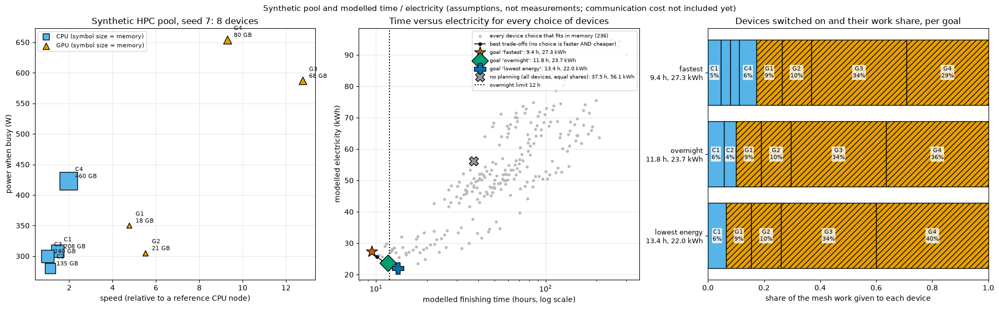

TASK 03b RESULT: synthetic HPC pool with 8 devices (seed 7); 236 of 255 device choices fit the job in memory
  job (assumed): 300 h on one speed-1 device, needs 200 GB; overnight limit 12 h
  id  class       speed memory GB max share busy W idle W W per unit of speed
  C1  CPU older    1.45       208      100%    308    121               212.4
  C2  CPU older    1.11       135       68%    280    101               252.3
  C3  CPU older    1.00       240      100%    300    123               300.0
  C4  CPU newer    1.97       460      100%    423    115               214.7
  G1  GPU mid      4.76        18        9%    350     39                73.5
  G2  GPU mid      5.51        21       10%    305     40                55.4
  G3  GPU high    12.76        68       34%    587     60                46.0
  G4  GPU high     9.29        80       40%    654     54                70.4
  goal             time h energy kWh  devices switched on and their work shares
  fastest            9.41   

In [9]:
# TASK_03B_IMPLEMENTATION_CELL_START
# Task 03b: a synthetic research-centre HPC pool (CPUs and GPUs with speed, memory and power) and three
# researcher goals. Exact answers by checking every possible choice of devices. Classical model only.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import linprog

HPC_SEED = 7
# Synthetic device classes. The ranges are OUR ASSUMPTIONS for a mixed research cluster,
# NOT specifications of real products: speed is relative to a reference CPU node (speed 1).
HPC_DEVICE_CLASSES = {
    "CPU older": dict(kind="CPU", speed=(1.0, 1.5), memory_gb=(128, 256), active_w=(250, 350), idle_w=(90, 130)),
    "CPU newer": dict(kind="CPU", speed=(1.5, 2.5), memory_gb=(256, 512), active_w=(300, 450), idle_w=(100, 150)),
    "GPU mid":   dict(kind="GPU", speed=(4.0, 7.0), memory_gb=(16, 24), active_w=(250, 350), idle_w=(30, 50)),
    "GPU high":  dict(kind="GPU", speed=(8.0, 14.0), memory_gb=(40, 80), active_w=(400, 700), idle_w=(50, 80)),
}
HPC_DEVICE_COUNTS = {"CPU older": (1, 3), "CPU newer": (1, 3), "GPU mid": (1, 3), "GPU high": (1, 2)}  # min, max (inclusive)
# The job (assumptions): how long the whole simulation takes on one speed-1 device, and how much memory it needs.
# 300 h is a scenario choice: with it the overnight limit lies between the fastest and the cheapest plan,
# so the three goals give three different answers. Change it to explore other job sizes.
JOB_REFERENCE_HOURS = 300.0
JOB_MEMORY_GB = 200.0          # a device can hold at most memory_gb / JOB_MEMORY_GB of the work
OVERNIGHT_HOURS = 12.0         # "run it overnight": must finish within this time
HPC_GOALS = {"fastest": "finish as early as possible",
             "overnight": f"least electricity, finished within {OVERNIGHT_HOURS:g} h",
             "lowest energy": "least electricity, time does not matter"}
HPC_TOL = 1e-9


def generate_hpc_pool(seed):
    """Random pool: a random number of devices per class, each with values drawn inside its class ranges."""
    rng = np.random.default_rng(seed)
    pool = []
    for class_name, spec in HPC_DEVICE_CLASSES.items():
        low, high = HPC_DEVICE_COUNTS[class_name]
        for _ in range(int(rng.integers(low, high + 1))):
            short = f"{spec['kind'][0]}{1 + sum(d['kind'] == spec['kind'] for d in pool)}"      # C1, C2, ... / G1, G2, ...
            pool.append(dict(id=short, class_name=class_name, kind=spec["kind"],
                             speed=round(float(rng.uniform(*spec["speed"])), 2),
                             memory_gb=float(rng.integers(spec["memory_gb"][0], spec["memory_gb"][1] + 1)),
                             active_w=float(rng.integers(spec["active_w"][0], spec["active_w"][1] + 1)),
                             idle_w=float(rng.integers(spec["idle_w"][0], spec["idle_w"][1] + 1))))
    return pool


def fastest_shares(speed, cap):
    """Work shares that finish earliest on a set of devices: proportional to speed, but never more than a device's
    memory allows; work a full device cannot take goes to the others. Returns None if the memory is not enough."""
    if cap.sum() < 1.0 - HPC_TOL:
        return None
    capped = np.zeros(len(speed), dtype=bool)
    while not capped.all():
        rate = (1.0 - cap[capped].sum()) / speed[~capped].sum()      # work share per unit of speed for the free devices
        over = ~capped & (speed * rate > cap + HPC_TOL)
        if not over.any():
            return np.where(capped, cap, speed * rate)
        capped |= over
    return cap / cap.sum()                                            # every device is at its memory limit


def plan_time_energy(shares, speed, active_w, idle_w):
    """Modelled finishing time (hours) and electricity (kWh): each device is busy share/speed, then idles until the end."""
    busy = JOB_REFERENCE_HOURS * shares / speed
    total_time = busy.max()
    return total_time, float(np.sum(active_w * busy + idle_w * (total_time - busy)) / 1000.0)


hpc_pool = generate_hpc_pool(HPC_SEED)
assert generate_hpc_pool(HPC_SEED) == hpc_pool, "pool is not reproducible"
hpc_speed = np.array([d["speed"] for d in hpc_pool])
hpc_cap = np.minimum(1.0, np.array([d["memory_gb"] for d in hpc_pool]) / JOB_MEMORY_GB)
hpc_active = np.array([d["active_w"] for d in hpc_pool])
hpc_idle = np.array([d["idle_w"] for d in hpc_pool])
n_devices = len(hpc_pool)

# ---- Every possible choice of devices (2^N - 1 subsets), each loaded with its fastest shares ----
hpc_options = []
for mask in range(1, 2**n_devices):
    chosen = np.flatnonzero((mask >> np.arange(n_devices)) & 1)
    shares = fastest_shares(hpc_speed[chosen], hpc_cap[chosen])
    if shares is None:
        continue                                                      # these devices cannot hold the job in memory
    time_h, energy_kwh = plan_time_energy(shares, hpc_speed[chosen], hpc_active[chosen], hpc_idle[chosen])
    hpc_options.append(dict(devices=chosen, shares=shares, time_h=time_h, energy_kwh=energy_kwh))
assert hpc_options, "no choice of devices can hold the job in memory"
option_time = np.array([o["time_h"] for o in hpc_options])
option_energy = np.array([o["energy_kwh"] for o in hpc_options])


def best_option(candidates, first, second):
    """Index of the candidate with the smallest `first` value; ties broken by `second`, then by enumeration order."""
    candidates = np.asarray(candidates)
    order = np.lexsort((second[candidates], first[candidates]))
    return int(candidates[order[0]])


all_options = np.arange(len(hpc_options))
in_time = np.flatnonzero(option_time <= OVERNIGHT_HOURS + HPC_TOL)
hpc_plans = {"fastest": hpc_options[best_option(all_options, option_time, option_energy)],
             "overnight": hpc_options[best_option(in_time, option_energy, option_time)] if len(in_time) else None,
             "lowest energy": hpc_options[best_option(all_options, option_energy, option_time)]}

# Reference without any planning: every device switched on, equal shares (speed and memory ignored)
equal_shares = np.full(n_devices, 1.0 / n_devices)
naive_time, naive_energy = plan_time_energy(equal_shares, hpc_speed, hpc_active, hpc_idle)
naive_overflow = [hpc_pool[k]["id"] for k in np.flatnonzero(equal_shares > hpc_cap + HPC_TOL)]

# ---- Checks ----
# hand example: two identical devices -> half each, both busy to the end, no idle energy
test_shares = fastest_shares(np.array([1.0, 1.0]), np.array([1.0, 1.0]))
test_time, test_energy = plan_time_energy(test_shares, np.array([1.0, 1.0]), np.array([100.0, 100.0]), np.array([50.0, 50.0]))
assert np.allclose(test_shares, 0.5) and np.isclose(test_time, JOB_REFERENCE_HOURS / 2) and np.isclose(test_energy, 0.1 * JOB_REFERENCE_HOURS)
# memory limit example: a fast device that can hold only 20 % -> the slow one takes 80 % and sets the time
assert np.allclose(fastest_shares(np.array([10.0, 1.0]), np.array([0.2, 1.0])), [0.2, 0.8])
for option in hpc_options:
    assert np.isclose(option["shares"].sum(), 1.0) and np.all(option["shares"] <= hpc_cap[option["devices"]] + HPC_TOL)
# independent check of the fastest shares with a linear program (minimise the time) on the chosen plans and 40 random options
lp_rng = np.random.default_rng(HPC_SEED)
lp_checks = [o for o in hpc_plans.values() if o is not None] + [hpc_options[i] for i in lp_rng.integers(0, len(hpc_options), 40)]
for option in lp_checks:
    m = len(option["devices"])
    speed = hpc_speed[option["devices"]]
    solution = linprog(c=np.r_[np.zeros(m), 1.0], A_ub=np.c_[np.eye(m), -speed], b_ub=np.zeros(m),
                       A_eq=np.r_[np.ones(m), 0.0][None, :], b_eq=[1.0],
                       bounds=[(0.0, float(c)) for c in hpc_cap[option["devices"]]] + [(0.0, None)])
    assert solution.success and np.isclose(JOB_REFERENCE_HOURS * solution.x[-1], option["time_h"], rtol=1e-7), "fastest shares are not optimal"
# using every device is never slower than any other choice (in this model, which has no communication cost yet)
assert np.isclose(hpc_plans["fastest"]["time_h"], option_time.min()) and len(hpc_plans["fastest"]["devices"]) <= n_devices
assert hpc_plans["lowest energy"]["energy_kwh"] <= option_energy.min() + HPC_TOL
if hpc_plans["overnight"] is not None:
    assert hpc_plans["overnight"]["time_h"] <= OVERNIGHT_HOURS + HPC_TOL
    assert hpc_plans["lowest energy"]["energy_kwh"] <= hpc_plans["overnight"]["energy_kwh"] + HPC_TOL

# Best trade-offs: options for which no other option is both faster and cheaper
order = np.lexsort((option_energy, option_time))
pareto = [i for position, i in enumerate(order) if option_energy[i] < option_energy[order[:position]].min(initial=np.inf) - HPC_TOL]

# ---- Plot ----
hpc_plot_path = Path("results") / f"hpc_pool_goals_seed{HPC_SEED}.png"
hpc_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), constrained_layout=True)
kind_style = {"CPU": dict(marker="s", color="#56B4E9", hatch=""), "GPU": dict(marker="^", color="#E69F00", hatch="///")}
for device in hpc_pool:
    style = kind_style[device["kind"]]
    axes[0].scatter(device["speed"], device["active_w"], s=30 + 1.2 * device["memory_gb"], marker=style["marker"], color=style["color"],
                    edgecolor="black", zorder=3)
    axes[0].annotate(f"{device['id']}\n{device['memory_gb']:.0f} GB", (device["speed"], device["active_w"]), xytext=(9, 4),
                     textcoords="offset points", fontsize=8)
for kind, style in kind_style.items():
    axes[0].scatter([], [], marker=style["marker"], color=style["color"], edgecolor="black", s=80, label=f"{kind} (symbol size = memory)")
axes[0].set_xlabel("speed (relative to a reference CPU node)")
axes[0].set_ylabel("power when busy (W)")
axes[0].set_title(f"Synthetic HPC pool, seed {HPC_SEED}: {n_devices} devices")
axes[0].legend(fontsize=8, loc="upper left")
axes[0].grid(alpha=0.3)

axes[1].scatter(option_time, option_energy, s=10, color="#BBBBBB", label=f"every device choice that fits in memory ({len(hpc_options)})")
axes[1].plot(option_time[pareto], option_energy[pareto], "-o", color="black", ms=4, lw=1.2, label="best trade-offs (no choice is faster AND cheaper)")
goal_markers = {"fastest": ("*", "#D55E00"), "overnight": ("D", "#009E73"), "lowest energy": ("P", "#0072B2")}
for goal, plan in hpc_plans.items():
    if plan is not None:
        axes[1].scatter(plan["time_h"], plan["energy_kwh"], marker=goal_markers[goal][0], s=260, color=goal_markers[goal][1],
                        edgecolor="black", zorder=4, label=f"goal '{goal}': {plan['time_h']:.1f} h, {plan['energy_kwh']:.1f} kWh")
axes[1].scatter(naive_time, naive_energy, marker="X", s=160, color="#999999", edgecolor="black", zorder=4,
                label=f"no planning (all devices, equal shares): {naive_time:.1f} h, {naive_energy:.1f} kWh")
axes[1].axvline(OVERNIGHT_HOURS, color="black", ls=":", lw=1.5, label=f"overnight limit {OVERNIGHT_HOURS:g} h")
axes[1].set_xscale("log")
axes[1].set_xlabel("modelled finishing time (hours, log scale)")
axes[1].set_ylabel("modelled electricity (kWh)")
axes[1].set_title("Time versus electricity for every choice of devices")
axes[1].legend(fontsize=7.5, loc="upper right")
axes[1].grid(alpha=0.3)

goal_names = [goal for goal, plan in hpc_plans.items() if plan is not None]
for row, goal in enumerate(goal_names):
    plan, left = hpc_plans[goal], 0.0
    for device_index, share in zip(plan["devices"], plan["shares"]):
        device = hpc_pool[device_index]
        style = kind_style[device["kind"]]
        axes[2].barh(row, share, left=left, color=style["color"], edgecolor="black", hatch=style["hatch"])
        if share > 0.035:
            axes[2].text(left + share / 2, row, f"{device['id']}\n{share:.0%}", ha="center", va="center", fontsize=8,
                         bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.8))
        left += share
axes[2].set_yticks(range(len(goal_names)))
axes[2].set_yticklabels([f"{goal}\n{hpc_plans[goal]['time_h']:.1f} h, {hpc_plans[goal]['energy_kwh']:.1f} kWh" for goal in goal_names], fontsize=9)
axes[2].invert_yaxis()
axes[2].set_xlim(0, 1)
axes[2].set_xlabel("share of the mesh work given to each device")
axes[2].set_title("Devices switched on and their work share, per goal")
fig.suptitle("Synthetic pool and modelled time / electricity (assumptions, not measurements; communication cost not included yet)", fontsize=11)
fig.savefig(hpc_plot_path, dpi=110)
plt.show()
assert hpc_plot_path.exists() and hpc_plot_path.stat().st_size < 2_000_000

# ---- Summary (only reached if every assertion above passed) ----
print(f"TASK 03b RESULT: synthetic HPC pool with {n_devices} devices (seed {HPC_SEED}); {len(hpc_options)} of {2**n_devices - 1} device choices fit the job in memory")
print(f"  job (assumed): {JOB_REFERENCE_HOURS:g} h on one speed-1 device, needs {JOB_MEMORY_GB:g} GB; overnight limit {OVERNIGHT_HOURS:g} h")
print(f"  {'id':<4}{'class':<11}{'speed':>6}{'memory GB':>10}{'max share':>10}{'busy W':>7}{'idle W':>7}{'W per unit of speed':>20}")
for device, cap in zip(hpc_pool, hpc_cap):
    print(f"  {device['id']:<4}{device['class_name']:<11}{device['speed']:>6.2f}{device['memory_gb']:>10.0f}{cap:>10.0%}"
          f"{device['active_w']:>7.0f}{device['idle_w']:>7.0f}{device['active_w'] / device['speed']:>20.1f}")
print(f"  {'goal':<15}{'time h':>8}{'energy kWh':>11}  devices switched on and their work shares")
for goal, plan in hpc_plans.items():
    if plan is None:
        print(f"  {goal:<15}no choice of devices finishes within {OVERNIGHT_HOURS:g} h")
        continue
    shares_text = ", ".join(f"{hpc_pool[k]['id']} {share:.1%}" for k, share in zip(plan["devices"], plan["shares"]))
    print(f"  {goal:<15}{plan['time_h']:>8.2f}{plan['energy_kwh']:>11.2f}  {shares_text}")
print(f"  {'no planning':<15}{naive_time:>8.2f}{naive_energy:>11.2f}  all {n_devices} devices, equal shares"
      + (f" (would overflow the memory of {', '.join(naive_overflow)})" if naive_overflow else ""))
fastest, eco = hpc_plans["fastest"], hpc_plans["lowest energy"]
print(f"  'fastest' is {naive_time / fastest['time_h']:.1f}x faster than no planning; 'lowest energy' uses "
      f"{1 - eco['energy_kwh'] / fastest['energy_kwh']:.0%} less electricity than 'fastest' but takes {eco['time_h'] / fastest['time_h']:.1f}x longer")
print(f"  to realise a plan on the mesh: a plan with k devices needs k - 1 two-way splits "
      f"({', '.join(f'{goal}: {len(plan['devices']) - 1}' for goal, plan in hpc_plans.items() if plan is not None)})")
print("  checks passed: shares sum to 1 and respect memory; fastest shares confirmed by a linear program; goal ordering consistent")
print(f"  plot saved: {hpc_plot_path}")
# TASK_03B_IMPLEMENTATION_CELL_END

## Task 04 — QAOA simulator, variants, classical baselines and modelled outcome

**Goal:** run QAOA for the first time — on this computer, without noise — and find out how good its splits are. Several QAOA variants and several classical optimisers are compared with classical methods on the same Ising objective and graded against the exact answers from Task 03.

**Why this matters:** before spending IonQ queue time we need to know which variant and which settings are worth running, whether QAOA beats random guessing, and where it loses to classical heuristics. Everything here is graded with the exact optimum, so the answer is not a matter of opinion.

**What runs**

| Part | Content |
|---|---|
| Simulator | exact statevector in numpy; cost layer `exp(−iγ·E_scaled)`, mixer `exp(+iβ·ΣX)` (= `rx(−2β)`); cross-checked against the real Qiskit circuit (`rzz`, `rz`, `rx`) |
| LR-QAOA | linear-ramp schedule, no optimiser loop; three versions: calibrated by mean energy, calibrated by success probability, and the paper's default (0.6, 0.3) |
| Optimised QAOA | 2p free angles; COBYLA, Nelder-Mead, Powell, L-BFGS-B (exact expectation) and SPSA (1,000-shot estimates only); start from the LR-QAOA angles and from seeded random angles; the same evaluation budget for all |
| CVaR-QAOA | objective = mean of the lowest 10 % of the sampled energies |
| Warm-start QAOA | from the convex relaxation (mixer A) and from the rounded spectral split (mixer A and the paper's modified mixer B) |
| Symmetry-reduced QAOA | at α = 0.5 region 0 is fixed to device A: one qubit less |
| Classical baselines | uniform random, random with the target share, simulated annealing, local search with restarts, spectral bisection — same objective, same budget of 1,000 candidate splits |
| Noise estimate | analytical: share of error-free shots `F = (1 − e)^(two-qubit gates)`, outcome = `F`·ideal + `(1 − F)`·uniform |
| Modelled outcome | runtime and electricity of each method's best split, with the device model |

**Rules that keep the comparison honest**
- The LR-QAOA angles, the SPSA settings and the simulated-annealing temperatures are chosen on **separate calibration meshes** (other seeds), never on the scored instances.
- Main metric: probability that a shot has **cost ≤ 1.05 × the exact optimum**. The p = 0 control (uniform guessing) is always shown next to QAOA.
- Warm-start variants start from a classical solution; they are compared with that classical solution and with their own start state, not presented as pure quantum results.
- The balance weights are the agreed shared values (λ = 10 for equal devices, 3.98 for CPU + GPU); the instances are rebuilt locally (`task04_ising_cases`) and Task 03's data is not modified.
- "Wall-clock" means measured on this computer. "Runtime" and "electricity" are **modelled** with stated assumptions. The noise numbers are an **estimate**, not an IonQ result.

**Literature (checked against the primary sources before coding):** LR-QAOA — Montañez-Barrera & Michielsen, *npj Quantum Information* 11, 131 (2025); CVaR — Barkoutsos et al., *Quantum* 4, 256 (2020); warm-start QAOA — Egger, Mareček & Woerner, *Quantum* 5, 479 (2021); SPSA — Spall, *IEEE Trans. Aerosp. Electron. Syst.* 34, 817 (1998); Ising graph partitioning — Lucas, *Front. Phys.* 2:5 (2014).

**Findings that shape how results are read (from the checks and an independent review):**
- The **relaxation warm start is degenerate** for this objective: its optimum is `c_i = α` for every region (equal values make both the cut and the balance term zero). At α = 0.5 it equals standard QAOA; at α = 0.8 its start state is the target-share sampler.
- At α = 0.8 the fair random reference is the **sampler with the target share** (each region on device B with probability α), not uniform guessing; the summary reports both ratios. An ablation shows how much of the cost layer's effect comes from the single-region terms (which only bias each region towards device B) and how much from the pair terms.
- **Mixer B** at its recovery angles returns the classical spectral split with certainty; its row is the spectral split, not a quantum result.
- The checkpoint is reused only if the settings, the problem data **and the code of every function in this cell** are unchanged; an instance whose QAOA run failed is recomputed on the next run, and failures are printed at the top of the result.
- **Mutation testing:** 30 deliberate bugs (signs, bit order, schedule direction, annealing and local-search rules, metric formulas, the outcome model, ...) were injected one at a time; every one is caught by a check or shown as a failure.

**Acceptance checks:** normalised probabilities; unitary mixers; Qiskit circuit = numpy simulator; correct sign (QAOA below the uniform mean cost on every instance, and a flipped mixer sign makes it worse); p = 0 is uniform; exact optima agree with Task 03; symmetry reduction keeps the optimum; identical evaluation budgets; all baselines scored with the same objective; fixed seeds reproduce runs; no missing values.

**Output:** `qaoa_results[(case, n, seed, scenario, variant, optimiser, p)]`, `classical_results[(case, n, seed, scenario, method)]`, the flat table `task04_table`, six plots and three result files in `results/` (summary JSON, per-run CSV, compressed checkpoint that lets a re-run resume).

**Scope limit:** local simulation only — no IonQ or Qollab run, no device-choice problem, no split over more than two devices, no PDE solver, no HPC measurement. Nothing here shows quantum advantage, a speed-up or an energy saving.

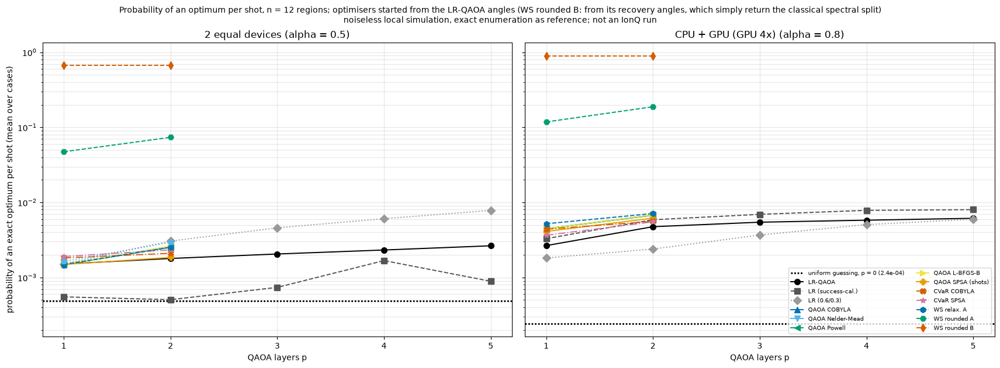

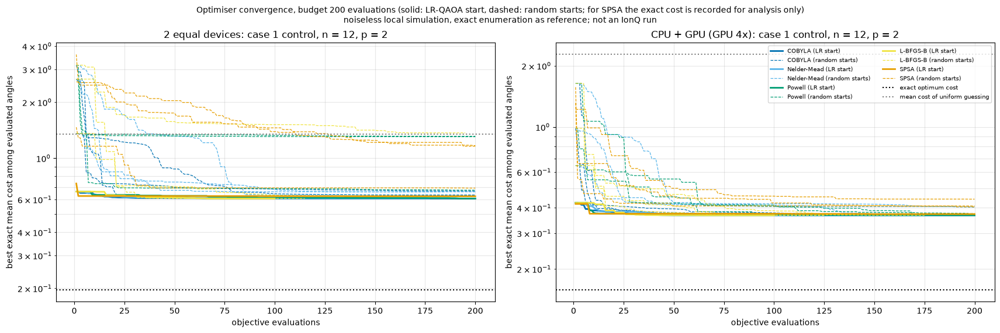

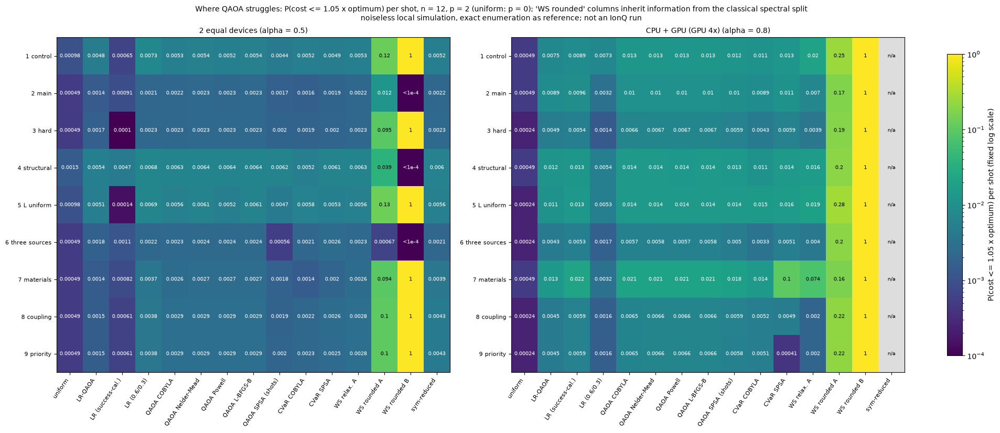

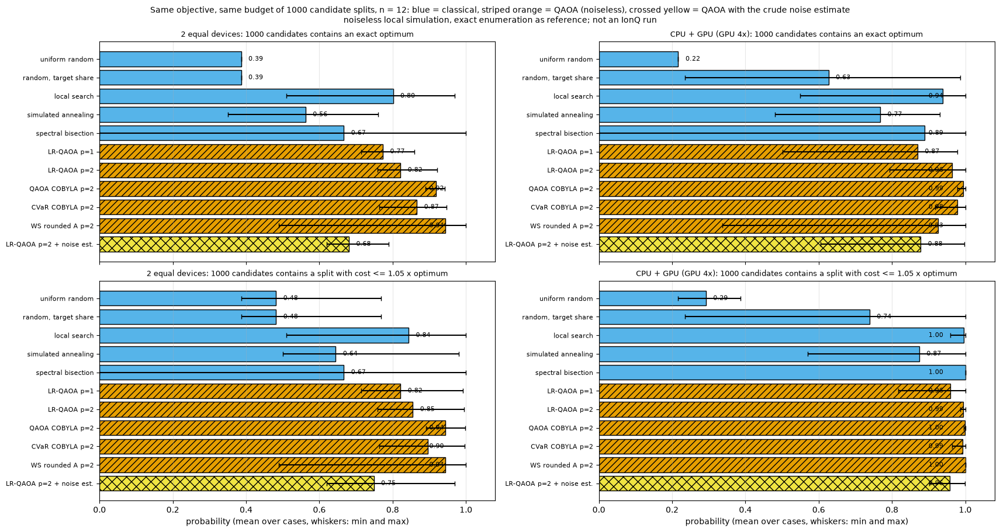

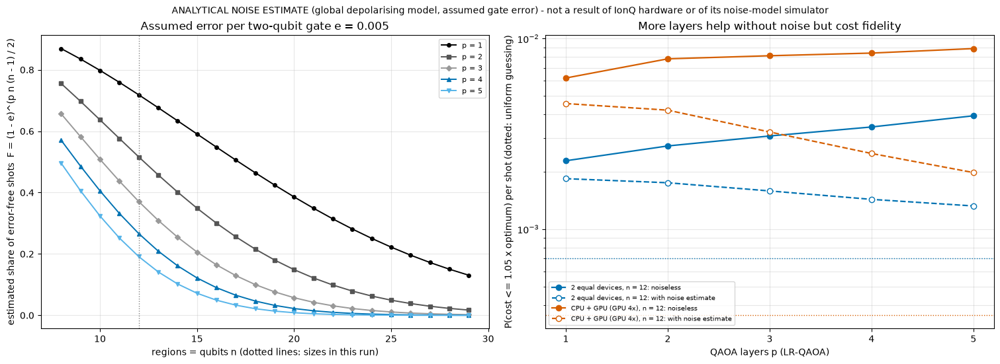

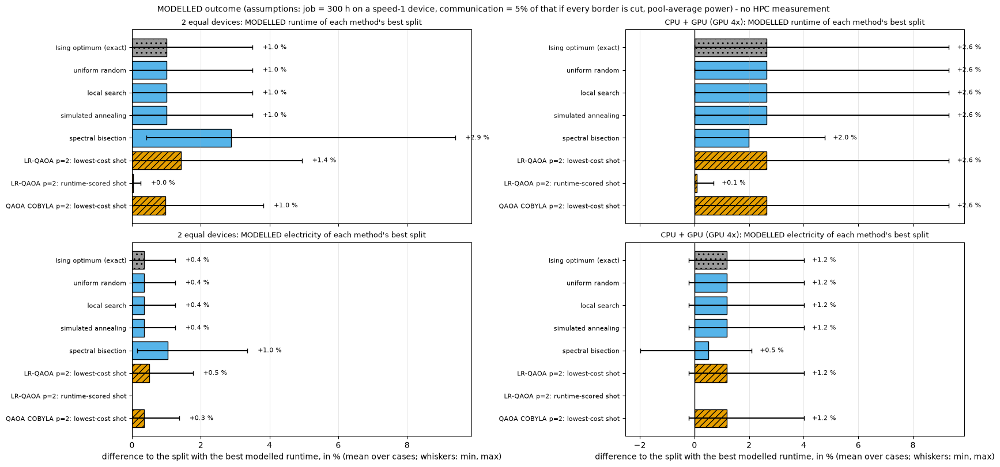

TASK 04 RESULT: local noiseless QAOA benchmark (mode 'small'): 18 instances, 882 QAOA groups, 2016 QAOA runs, 187303 objective evaluations, 90 classical records
  measured wall-clock: 22 s in this run (0 instances computed, 18 loaded from the checkpoint results/task04_checkpoint_small.json.gz); calibration 17 s
  objective: Task-04-local instances with lambda = 10 (2 equal devices), 3.98 (CPU + GPU (GPU 4x)); mu = 0 -> the priority penalty is INACTIVE, so case 9 equals case 8 here
  LR-QAOA angles, chosen once per scenario on 4 separate calibration meshes (2 main seed 101, 2 main seed 102, 6 three sources seed 101, 6 three sources seed 102; layers [1, 2]):
    2 equal devices: by mean energy (delta_gamma, delta_beta) = (0.260, 0.200); by success probability (1.740, 1.450); paper default (0.6, 0.3)
    CPU + GPU (GPU 4x): by mean energy (delta_gamma, delta_beta) = (0.960, 0.550); by success probability (1.240, 0.400); paper default (0.6, 0.3)
  SPSA and simulated annealing settings, cho

In [10]:
# TASK_04_IMPLEMENTATION_CELL_START
# Task 04: local noiseless QAOA simulation (several variants and optimisers), classical baselines on the same
# Ising objective, a crude analytical noise estimate and a modelled runtime / electricity outcome.
# Nothing here runs on IonQ or Qollab. "Wall-clock" = measured on this computer; "runtime", "electricity" = MODELLED.
import csv
import gzip
import hashlib
import json
import time
import zlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

TASK04 = dict(
    code_version="task04-v1",
    # agreed shared balance weights (Task 03 large-mode selection); Task 03's own instances are left untouched
    lambda_by_scenario={"2 equal devices": 10.0, "CPU + GPU (GPU 4x)": 3.98},
    mu=float(selected_mu),                         # priority weight kept from Task 03 (0 = priority penalty inactive)
    near_optimal_factor=1.05,                      # main metric: cost <= 1.05 x optimum
    epsilon=ISING_EPSILON,                         # balance tolerance
    # optimiser study
    eval_budget=200,                               # objective evaluations per optimisation run, identical for all optimisers
    random_starts=3,                               # seeded random starts in addition to the LR-QAOA start
    start_seed=4004,
    optimizers=["COBYLA", "Nelder-Mead", "Powell", "L-BFGS-B", "SPSA"],
    random_gamma_max=1.0, random_beta_max=float(np.pi / 2),
    # SPSA gains follow Spall (1998): exponents 0.602 / 0.101, stability constant 10 % of the iterations,
    # step size set from a few initial gradient estimates so that the first move is about `first_step` (all inside the budget)
    # The perturbation size and the first-step size are chosen once per scenario on the calibration meshes (grids below).
    spsa=dict(alpha=0.602, gamma=0.101, stability_fraction=0.1, calibration_pairs=5,
              perturbation_grid=(0.02, 0.05, 0.1), first_step_grid=(0.01, 0.03, 0.1)),
    cvar_fraction=0.10, cvar_optimizers=["COBYLA", "SPSA"],
    warm_start_epsilon_rounded=0.25,               # Egger et al. (2021), Sec. 2.3
    warm_start_epsilon_continuous=0.05,            # our choice: the paper only gives the range [0, 0.5]
    warm_start_optimizers=["COBYLA"],
    lr_paper_default=(0.6, 0.3),                   # (delta_gamma, delta_beta) used on hardware in the LR-QAOA paper
    symmetry_optimizers=["COBYLA"],
    stress_layers=[3, 4, 5],                       # extra depths, LR-QAOA only (no optimiser loop)
    full_sweep_max_qubits=16,                      # above this size only LR-QAOA and COBYLA (LR start) are run
    # LR-QAOA schedule: chosen once per scenario on SEPARATE calibration meshes (other seeds), never on scored instances
    lr_grid_gamma=np.linspace(0.02, 2.0, 100), lr_grid_beta=np.linspace(0.05, 1.5, 30),
    calibration_cases=["2 main", "6 three sources"], calibration_seeds=[101, 102], calibration_n=12,
    # classical baselines: same objective, same budget of candidate evaluations as the QAOA shots
    classical_budget=int(RUN["shots"]), classical_repeats=100, classical_seed=5005,
    # simulated annealing: start temperature (as a fraction of the energy spread) and end/start ratio are also chosen
    # once per scenario on the calibration meshes, so the classical baseline is tuned as carefully as the quantum one
    sa_start_fraction_grid=(1.0, 0.3, 0.1, 0.03, 0.01), sa_end_ratio_grid=(1e-2, 1e-3), sa_calibration_repeats=20,
    # crude analytical noise estimate (NOT an IonQ result)
    noise_error_per_two_qubit_gate=0.005,
    # modelled outcome (assumptions): job length from Task 03b, communication as a share of the reference job time
    job_reference_hours=float(JOB_REFERENCE_HOURS), comm_fraction_if_all_borders_cut=0.05,
    use_checkpoint=True,
)
TASK04.update(globals().get("TASK04_OVERRIDES", {}))   # optional: define TASK04_OVERRIDES before this cell for quick tests
assert RUN["quantum_cases"], "RUN['quantum_cases'] is empty: Task 04 benchmarks QAOA, so it needs at least one quantum case"
T4_TOL = 1e-9
T4_RESULTS_DIR = Path("results")
T4_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
T4_CHECKPOINT = T4_RESULTS_DIR / f"task04_checkpoint_{RUN_MODE}.json.gz"
T4_SPSA_SETTINGS, T4_SA_SETTINGS = {}, {}        # per scenario, filled by the calibration below
T4_SHOTS = int(RUN["shots"])
T4_LAYERS = [int(p) for p in RUN["qaoa_layers"]]
TASK04_REFERENCES = {}        # filled below with the verified literature references


def t4_jsonable(value):
    """Convert numpy types and arrays to plain Python so results can be saved as JSON."""
    if isinstance(value, dict):
        return {str(k): t4_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [t4_jsonable(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (np.floating, np.integer, np.bool_)):
        return value.item()
    return value


T4_CONFIG_HASH = hashlib.sha256(json.dumps(t4_jsonable(TASK04), sort_keys=True).encode()).hexdigest()[:16]


# ------------------------------------------------------------------ simulator ----
def fast_kron(a, b):
    """Kronecker product of two small matrices (much faster than np.kron for these sizes)."""
    return (a[:, None, :, None] * b[None, :, None, :]).reshape(a.shape[0] * b.shape[0], a.shape[1] * b.shape[1])


def kron_block(gates):
    """Kronecker product gates[-1] x ... x gates[0] (qubit 0 least significant), built as a balanced tree."""
    if len(gates) == 1:
        return gates[0]
    middle = len(gates) // 2
    return fast_kron(kron_block(gates[middle:]), kron_block(gates[:middle]))


def apply_qubit_gates(state, gates, per_qubit=False):
    """Apply one 2x2 gate per qubit (gates[q]) to a statevector. Qubit q is bit q of the state index (qubit 0 = least significant)."""
    n = len(gates)
    if 2 <= n <= 13 and not per_qubit:            # two dense blocks: (high block) @ state @ (low block)^T
        low = n // 2
        return (kron_block(gates[low:]) @ state.reshape(2 ** (n - low), 2**low) @ kron_block(gates[:low]).T).reshape(-1)
    for q in range(n):                            # larger registers: one qubit at a time
        view = state.reshape(-1, 2, 2**q)
        new = np.empty_like(view)
        new[:, 0, :] = gates[q][0, 0] * view[:, 0, :] + gates[q][0, 1] * view[:, 1, :]
        new[:, 1, :] = gates[q][1, 0] * view[:, 0, :] + gates[q][1, 1] * view[:, 1, :]
        state = new.reshape(-1)
    return state


def mixer_gates(beta, axis_angles):
    """One gate per qubit: exp(+i beta (sin(t) X + cos(t) Z)) for the axis angle t of that qubit.
    t = pi/2: the standard mixer exp(+i beta X) = RX(-2 beta), i.e. exp(-i beta H_M) with H_M = -X.
    t = +theta_q: warm-start mixer A of Egger et al. (2021), Eq. (2): RY(theta) RZ(-2 beta) RY(-theta); its ground state is the
                  warm-start initial state RY(theta)|0>.
    t = -theta_q: their modified mixer B for rounded solutions (Sec. 2.3): RY(-theta) RZ(-2 beta) RY(theta)."""
    c, s = np.cos(beta), 1j * np.sin(beta)
    gates = np.empty((len(axis_angles), 2, 2), dtype=complex)
    gates[:, 0, 0], gates[:, 1, 1] = c + s * np.cos(axis_angles), c - s * np.cos(axis_angles)
    gates[:, 0, 1] = gates[:, 1, 0] = s * np.sin(axis_angles)
    return gates


T4_HADAMARD_CACHE = {}


def uniform_x_mixer_block(beta, k):
    """exp(+i beta sum X) on k qubits as a dense matrix, via X = H Z H: H diag(exp(i beta (k - 2 popcount))) H."""
    if k not in T4_HADAMARD_CACHE:
        hadamard = np.ones((1, 1))
        for _ in range(k):
            hadamard = np.kron(hadamard, np.array([[1.0, 1.0], [1.0, -1.0]])) / np.sqrt(2.0)
        popcount = np.array([bin(index).count("1") for index in range(2**k)])
        T4_HADAMARD_CACHE[k] = (hadamard, k - 2 * popcount)
    hadamard, weights = T4_HADAMARD_CACHE[k]
    return (hadamard * np.exp(1j * beta * weights)) @ hadamard


def apply_uniform_x_mixer(state, beta, n):
    """Standard mixer exp(+i beta sum_q X_q) = prod_q RX(-2 beta) on all n qubits."""
    if 2 <= n <= 13:
        low = n // 2
        block_high = uniform_x_mixer_block(beta, n - low)
        block_low = block_high if n - low == low else uniform_x_mixer_block(beta, low)
        return (block_high @ state.reshape(2 ** (n - low), 2**low) @ block_low.T).reshape(-1)
    return apply_qubit_gates(state, mixer_gates(beta, np.full(n, np.pi / 2)))


def qaoa_statevector(energy_scaled, gammas, betas, n, thetas=None, mixer_axis=None):
    """Noiseless QAOA state. Cost layer: multiply state k by exp(-i gamma E_scaled[k]); then the mixer on every qubit.
    Standard QAOA: thetas = None (start |+>^n, mixer exp(+i beta X)). Warm start: start prod_q RY(theta_q)|0> and the
    mixer axis angles given in `mixer_axis` (+theta_q for mixer A, -theta_q for mixer B)."""
    standard = thetas is None
    if standard:
        state = np.full(2**n, 2.0 ** (-n / 2), dtype=complex)
    else:
        state = np.ones(1, dtype=complex)
        for q in range(n - 1, -1, -1):
            state = np.kron(state, np.array([np.cos(thetas[q] / 2), np.sin(thetas[q] / 2)]))
        mixer_axis = np.asarray(thetas if mixer_axis is None else mixer_axis, dtype=float)
    for gamma, beta in zip(gammas, betas):
        phase = gamma * energy_scaled
        state = state * (np.cos(phase) - 1j * np.sin(phase))            # = state * exp(-i gamma E_scaled)
        state = apply_uniform_x_mixer(state, beta, n) if standard else apply_qubit_gates(state, mixer_gates(beta, mixer_axis))
    return state


def qaoa_probabilities(energy_scaled, gammas, betas, n, thetas=None, mixer_axis=None):
    return np.abs(qaoa_statevector(energy_scaled, gammas, betas, n, thetas, mixer_axis)) ** 2


def view_probabilities(view, angles):
    """Outcome distribution of a QAOA run described by a view (energies, start state, mixer) and its angles [gammas, betas]."""
    return qaoa_probabilities(view["energy_scaled"], *split_angles(angles), view["n"], view["thetas"], view["mixer_axis"])


def lr_angles(p, delta_gamma, delta_beta):
    """LR-QAOA linear ramp for layers k = 1..p: gamma_k = (k/p) dgamma, beta_k = (1 - (k-1)/p) dbeta. Returns [gammas, betas]."""
    k = np.arange(1, p + 1)
    return np.concatenate([k / p * delta_gamma, (1.0 - (k - 1) / p) * delta_beta])


def split_angles(angles):
    p = len(angles) // 2
    return np.asarray(angles[:p], float), np.asarray(angles[p:], float)


def round_robin_pairs(n):
    """All pairs of n qubits arranged in rounds of disjoint pairs (circle method), so a dense rzz layer has minimal depth."""
    players = list(range(n)) + ([None] if n % 2 else [])
    m, rounds = len(players), []
    for _ in range(m - 1):
        rounds.append([(min(a, b), max(a, b)) for a, b in zip(players[: m // 2], players[::-1][: m // 2])
                       if a is not None and b is not None])
        players = [players[0], players[-1]] + players[1:-1]
    return rounds


def build_qaoa_circuit(J_scaled, h_scaled, gammas, betas, thetas=None, modified_mixer=False):
    """The Qiskit circuit that later runs on IonQ: H (or RY) start, rzz(2 gamma J) on every pair, rz(2 gamma h), rx(-2 beta).
    Warm start: mixer A = RY(theta) RZ(-2 beta) RY(-theta) (operator order), mixer B (modified_mixer) has the two RY swapped."""
    n = len(h_scaled)
    circuit = QuantumCircuit(n)
    for q in range(n):
        circuit.h(q) if thetas is None else circuit.ry(float(thetas[q]), q)
    for gamma, beta in zip(gammas, betas):
        for pairs in round_robin_pairs(n):
            for i, j in pairs:
                if J_scaled[i, j] != 0:
                    circuit.rzz(float(2 * gamma * J_scaled[i, j]), i, j)
        for q in range(n):
            if h_scaled[q] != 0:
                circuit.rz(float(2 * gamma * h_scaled[q]), q)
        for q in range(n):
            if thetas is None:
                circuit.rx(float(-2 * beta), q)
            else:                                   # operator products act right to left, circuits list gates in time order
                sign = -1.0 if modified_mixer else 1.0
                circuit.ry(float(-sign * thetas[q]), q)
                circuit.rz(float(-2 * beta), q)
                circuit.ry(float(sign * thetas[q]), q)
    return circuit


# ------------------------------------------------------------------ instances ----
def t4_power(device_name):
    """Assumed busy / idle power (W) of a scenario device: the average of the synthetic pool devices of the same kind."""
    kind = "GPU" if "GPU" in device_name.upper() else "CPU"
    members = [d for d in hpc_pool if d["kind"] == kind]
    assert members, f"no {kind} in the synthetic pool: power for '{device_name}' is unavailable"
    return float(np.mean([d["active_w"] for d in members])), float(np.mean([d["idle_w"] for d in members]))


def t4_build_instance(regions, case_name, n, seed, scenario):
    """Task-04-local Ising instance with the agreed lambda; exact reference by enumeration where the size allows."""
    alpha, lam = TARGET_SHARES[scenario], TASK04["lambda_by_scenario"][scenario]
    (name_a, speed_a), (name_b, speed_b) = DEVICE_SCENARIOS[scenario].items()
    priority_active = bool(regions["region_priority_work"].sum() > 0 and speed_b > speed_a and TASK04["mu"] > 0)
    mu = TASK04["mu"] if priority_active else 0.0
    model = build_partition_ising(regions["region_work"], regions["region_pairs"], regions["region_boundary_cost"], alpha,
                                  lam=lam, priority_work=regions["region_priority_work"], mu=mu)
    J, h, const = model["J"], model["h"], model["const"]
    check_rng = np.random.default_rng([TASK04["start_seed"], n, seed])
    for z in 1 - 2 * check_rng.integers(0, 2, size=(50, n)):          # same objective as Task 03: Ising energy = direct cost
        assert abs(ising_energy(z, J, h, const) - direct_cost(z, model)) < T4_TOL
    inst = dict(case=case_name, n=n, seed=seed, scenario=scenario, alpha=alpha, lam=lam, mu=mu, model=model, regions=regions,
                priority_active=priority_active, speeds=(float(speed_a), float(speed_b)), device_names=(name_a, name_b),
                power=(t4_power(name_a), t4_power(name_b)),
                e_std_formula=float(np.sqrt(np.sum(J**2) + np.sum(h**2))),      # exact std of E under uniform sampling
                fingerprint=hashlib.sha256(J.tobytes() + h.tobytes() + np.float64(const).tobytes()).hexdigest()[:16],
                exact=n <= EXACT_BRUTE_FORCE_MAX_QUBITS, statevector=n <= LOCAL_STATEVECTOR_MAX_QUBITS)
    if inst["exact"]:
        cut, share_b, prio_slow = enumerate_components(model)
        energies = cut + lam * 4.0 * (alpha - share_b) ** 2 + mu * prio_slow
        if n <= 16:                                 # full cross-check of the component formula against J, h, const
            assert np.max(np.abs(energies - ising_energies_all(J, h, const, n))) < T4_TOL
        e_min, e_max = float(energies.min()), float(energies.max())
        near_limit = TASK04["near_optimal_factor"] * e_min if e_min > T4_TOL else T4_TOL   # optimum 0: absolute tolerance
        imbalance = np.abs(share_b - alpha)
        inst.update(energies=energies, cut=cut, share_b=share_b, imbalance=imbalance, e_min=e_min, e_max=e_max,
                    e_mean=float(energies.mean()), e_std=float(energies.std()),
                    optimal_states=np.flatnonzero(energies <= e_min + T4_TOL), near_mask=energies <= near_limit + T4_TOL,
                    balanced_mask=imbalance <= TASK04["epsilon"], delta_star=float(imbalance.min()),
                    energy_scaled=(energies - const) / model["scale"])
        hours = TASK04["job_reference_hours"]
        inst["modelled_hours_all"] = (hours * np.maximum((1.0 - share_b) / speed_a, share_b / speed_b)
                                      + TASK04["comm_fraction_if_all_borders_cut"] * hours * cut)
        assert abs(inst["e_std"] - inst["e_std_formula"]) < 1e-6 * max(1.0, inst["e_std"]), "uniform-std formula is wrong"
    return inst


def t4_view(inst, thetas=None, mixer_axis=None):
    """What a QAOA run needs: energies, scaled energies, start state / mixer and reference sets of the (full) problem."""
    return dict(n=inst["n"], energies=inst["energies"], energy_scaled=inst["energy_scaled"], thetas=thetas, mixer_axis=mixer_axis,
                optimal_states=inst["optimal_states"], near_mask=inst["near_mask"], balanced_mask=inst["balanced_mask"],
                e_min=inst["e_min"], e_max=inst["e_max"], e_mean=inst["e_mean"], e_std=inst["e_std"], shift=0)


def t4_reduced_view(inst):
    """Symmetry reduction for alpha = 0.5 without priority: E(z) = E(-z), so region 0 is fixed to device A (x_0 = 0)
    and the problem lives on n - 1 qubits: J' = J[1:, 1:], h'_i = h_i + J_0i, const' = const + h_0."""
    model = inst["model"]
    J, h, const, n = model["J"], model["h"], model["const"], inst["n"]
    J_red, h_red, const_red = J[1:, 1:], h[1:] + J[0, 1:], const + h[0]
    energies_red = inst["energies"][0::2]                        # states with x_0 = 0 are the even state indices
    assert np.max(np.abs(energies_red - ising_energies_all(J_red, h_red, const_red, n - 1))) < T4_TOL, "reduction is wrong"
    assert abs(energies_red.min() - inst["e_min"]) < T4_TOL, "reduced optimum differs from the full optimum"
    scale_red = max(np.abs(J_red).max(), np.abs(h_red).max())
    optimal_red = np.flatnonzero(energies_red <= energies_red.min() + T4_TOL)
    assert np.all(np.isin(optimal_red << 1, inst["optimal_states"])), "a reduced optimum does not map to a full optimum"
    return dict(n=n - 1, energies=energies_red, energy_scaled=(energies_red - const_red) / scale_red, thetas=None, mixer_axis=None,
                optimal_states=optimal_red, near_mask=inst["near_mask"][0::2], balanced_mask=inst["balanced_mask"][0::2],
                e_min=inst["e_min"], e_max=float(energies_red.max()), e_mean=float(energies_red.mean()),
                e_std=float(energies_red.std()), shift=1, J_scaled=J_red / scale_red, h_scaled=h_red / scale_red)


# -------------------------------------------------------------------- metrics ----
def distribution_metrics(probs, view):
    """Exact metrics of an outcome distribution over all states of a view."""
    p_opt, p_near = float(probs[view["optimal_states"]].sum()), float(probs[view["near_mask"]].sum())
    mean_cost = float(probs @ view["energies"])
    spread = view["e_max"] - view["e_min"]
    return dict(p_opt=p_opt, p_near=p_near, mean_cost=mean_cost,
                mean_ratio=float((view["e_max"] - mean_cost) / spread) if spread > 0 else 1.0,
                p_balanced=float(probs[view["balanced_mask"]].sum()),
                hit_opt=float(1.0 - (1.0 - min(p_opt, 1.0)) ** T4_SHOTS), hit_near=float(1.0 - (1.0 - min(p_near, 1.0)) ** T4_SHOTS))


def sampled_metrics(probs, view, seed):
    """The same metrics from T4_SHOTS seeded samples (finite-shot variation). Returns (metrics, sampled FULL-problem states)."""
    samples = np.random.default_rng(seed).choice(len(probs), size=T4_SHOTS, p=probs / probs.sum())
    costs = view["energies"][samples]
    metrics = dict(sampled_p_opt=float(np.isin(samples, view["optimal_states"]).mean()), sampled_p_near=float(view["near_mask"][samples].mean()),
                   sampled_mean_cost=float(costs.mean()), sampled_p_balanced=float(view["balanced_mask"][samples].mean()),
                   sampled_best_cost=float(costs.min()), sampled_hit_opt=bool(costs.min() <= view["e_min"] + T4_TOL),
                   best_state=int(samples[np.argmin(costs)]) << view["shift"], sample_seed=t4_jsonable(seed))
    return metrics, samples << view["shift"]


def modelled_outcome(inst, state):
    """MODELLED runtime and electricity of one split (assumptions, not measurements):
    time = max(share_A / s_A, share_B / s_B) x job hours + communication, communication = comm fraction x job hours x cut fraction;
    each device draws busy power while computing and idle power for the rest of the run (communication counted as idle time)."""
    hours, (speed_a, speed_b) = TASK04["job_reference_hours"], inst["speeds"]
    if "share_b" in inst:                            # enumerated arrays still in memory
        share_b, cut_fraction = float(inst["share_b"][state]), float(inst["cut"][state])
    else:
        cut_fraction, _, _ = direct_cost_parts(1 - 2 * state_index_to_x(state, inst["n"]), inst["model"])
        share_b = float(inst["model"]["a_tilde"] @ state_index_to_x(state, inst["n"]))
    busy_a, busy_b = hours * (1.0 - share_b) / speed_a, hours * share_b / speed_b
    comm = TASK04["comm_fraction_if_all_borders_cut"] * hours * float(cut_fraction)
    total = max(busy_a, busy_b) + comm
    (active_a, idle_a), (active_b, idle_b) = inst["power"]
    energy = (active_a * busy_a + idle_a * (total - busy_a) + active_b * busy_b + idle_b * (total - busy_b)) / 1000.0
    pieces = device_piece_counts(state_index_to_x(state, inst["n"]), inst["regions"]["region_pairs"])
    work = float(inst["model"]["W"])
    return dict(state=int(state), share_b=share_b, load_a=(1.0 - share_b) * work, load_b=share_b * work,
                imbalance=abs(share_b - inst["alpha"]), cut_fraction=float(cut_fraction), pieces_a=int(pieces[0]), pieces_b=int(pieces[1]),
                compute_hours=float(max(busy_a, busy_b)), comm_hours=float(comm), modelled_hours=float(total), modelled_kwh=float(energy))


def state_cost(inst, state):
    """Ising cost of one state: array lookup when enumerated, otherwise from J, h, const."""
    if "energies" in inst:
        return float(inst["energies"][state])
    return float(ising_energy(1 - 2 * state_index_to_x(state, inst["n"]), inst["model"]["J"], inst["model"]["h"], inst["model"]["const"]))


# ----------------------------------------------------------------- optimisers ----
class BudgetExhausted(Exception):
    pass


class CountedObjective:
    """Wraps an objective: counts evaluations, enforces the budget exactly and keeps the traces."""

    def __init__(self, function, budget):
        self.function, self.budget = function, budget
        self.n_evals, self.best_value, self.best_x = 0, np.inf, None
        self.exact_cost_trace = []                 # exact mean cost at every evaluated point (analysis only)

    def __call__(self, angles):
        if self.n_evals >= self.budget:
            raise BudgetExhausted
        value, exact_cost = self.function(np.asarray(angles, float), self.n_evals)
        self.n_evals += 1
        self.exact_cost_trace.append(exact_cost)
        if value < self.best_value:
            self.best_value, self.best_x = value, np.array(angles, float)
        return value


def cvar_of_samples(energies, fraction):
    """CVaR for a minimisation problem (Barkoutsos et al. 2020): mean of the lowest ceil(fraction * K) of K sampled energies."""
    ordered = np.sort(np.asarray(energies, dtype=float))
    return float(ordered[: int(np.ceil(fraction * ordered.size - 1e-9))].mean())


def make_objective(view, kind, run_seed):
    """Objective for the optimisers, normalised by the uniform-sampling mean and spread of the energy.
    'expectation': exact mean energy. 'shot mean': mean of T4_SHOTS sampled energies (what hardware gives).
    'cvar': mean of the LOWEST cvar_fraction of the sampled energies (CVaR, Barkoutsos et al. 2020)."""
    def objective(angles, eval_index):
        probs = view_probabilities(view, angles)
        exact_cost = float(probs @ view["energies"])
        if kind == "expectation":
            value = exact_cost
        else:
            rng = np.random.default_rng([int(run_seed), int(eval_index)])
            sample = view["energies"][rng.choice(len(probs), size=T4_SHOTS, p=probs / probs.sum())]
            value = float(sample.mean()) if kind == "shot mean" else cvar_of_samples(sample, TASK04["cvar_fraction"])
        return (value - view["e_mean"]) / view["e_std"], exact_cost
    return objective


def spsa_minimize(counted, start, budget, seed, tuned):
    """Simultaneous perturbation stochastic approximation (Spall 1998): two noisy evaluations per iteration.
    `tuned` holds the perturbation size and the first-step size chosen on the calibration meshes."""
    settings, rng = dict(TASK04["spsa"], **tuned), np.random.default_rng([int(seed), 99])
    angles = np.array(start, float)

    def gradient_estimate(shift):
        direction = rng.choice([-1.0, 1.0], size=len(angles))
        return (counted(angles + shift * direction) - counted(angles - shift * direction)) / (2.0 * shift) * direction

    iterations = (budget - 2 * settings["calibration_pairs"]) // 2
    stability = settings["stability_fraction"] * iterations
    # Spall's rule for the step size: the first move should be about `first_step`, given the typical gradient size at the start
    typical_gradient = np.mean([np.abs(gradient_estimate(settings["perturbation"])).mean() for _ in range(settings["calibration_pairs"])])
    gain = settings["first_step"] * (stability + 1) ** settings["alpha"] / max(typical_gradient, 1e-12)
    for k in range(iterations):
        step = gain / (stability + k + 1) ** settings["alpha"]
        angles = angles - step * gradient_estimate(settings["perturbation"] / (k + 1) ** settings["gamma"])
    return angles, f"SPSA finished {iterations} iterations after {settings['calibration_pairs']} calibration pairs"


def run_optimizer(name, view, kind, start, run_seed, scenario=None):
    """One optimisation run with the fixed evaluation budget. Returns the counted objective, final angles and stop reason."""
    budget = TASK04["eval_budget"]
    counted = CountedObjective(make_objective(view, kind, run_seed), budget)
    returned = None
    try:
        if name == "SPSA":
            returned, reason = spsa_minimize(counted, start, budget, run_seed, T4_SPSA_SETTINGS[scenario])
        else:
            # stopping tolerances: angles resolved to about 1e-4 rad (objective is normalised to order 1); the budget is the hard cap
            options = {"COBYLA": dict(maxiter=budget, rhobeg=0.1, tol=1e-4),
                       "Nelder-Mead": dict(maxfev=budget, xatol=1e-4, fatol=1e-7),
                       "Powell": dict(maxfev=budget, xtol=1e-4, ftol=1e-7),
                       "L-BFGS-B": dict(maxfun=budget, ftol=1e-10, gtol=1e-6)}[name]
            result = minimize(counted, np.array(start, float), method=name, options=options)
            returned, reason = result.x, str(result.message)
    except BudgetExhausted:
        reason = "evaluation budget reached"
    # exact objective: the best evaluated point. Noisy objective: the optimiser's own final point
    # (or, if the budget stopped it, the point with the best estimate), because exact values are not visible to it.
    final = counted.best_x if (kind == "expectation" or returned is None) else np.asarray(returned, float)
    return counted, final, reason


def evaluate_run(inst, view, angles, sample_seed, extra):
    """Exact and sampled metrics of one set of angles, plus the modelled outcome of its best sampled split."""
    probs = view_probabilities(view, angles)
    assert np.all(np.isfinite(probs)) and abs(probs.sum() - 1.0) < 1e-9, "probabilities are not normalised"
    sampled, full_states = sampled_metrics(probs, view, sample_seed)
    run = dict(distribution_metrics(probs, view), **sampled, **extra)
    run["final_angles"] = [float(a) for a in angles]
    run["outcome"] = modelled_outcome(inst, run["best_state"])                      # the lowest-cost sampled split
    # the sampled split with the best MODELLED runtime (every shot scored with the runtime model)
    run["outcome_runtime_scored"] = modelled_outcome(inst, int(full_states[np.argmin(inst["modelled_hours_all"][full_states])]))
    return run


def aggregate_runs(runs):
    """Summary over the starts of one (variant, optimiser, p): the run from the given start and the spread over random starts."""
    random_runs = [r for r in runs if r["init"] == "random"]
    given_runs = [r for r in runs if r["init"] != "random"]
    summary = {}
    for field in ("p_opt", "p_near", "mean_cost", "mean_ratio", "p_balanced", "hit_opt", "hit_near"):
        if given_runs:
            summary[f"{field}_given_start"] = given_runs[0][field]
        if random_runs:
            values = np.array([r[field] for r in random_runs])
            summary.update({f"{field}_random_mean": float(values.mean()), f"{field}_random_std": float(values.std()),
                            f"{field}_random_min": float(values.min()), f"{field}_random_max": float(values.max())})
    summary["n_runs"] = len(runs)
    return summary


def optimiser_group(inst, view, variant, optimiser, kind, p, lr_start, key_seed, random_starts, start_label="LR-QAOA angles", beta_max=None):
    """All starts of one optimiser on one instance: the given start plus seeded random starts, same budget each."""
    starts = [(start_label, np.array(lr_start, float), None)]
    beta_max = TASK04["random_beta_max"] if beta_max is None else beta_max
    for r in range(random_starts):
        rng = np.random.default_rng([TASK04["start_seed"], key_seed, p, r])
        starts.append(("random", np.concatenate([rng.uniform(0, TASK04["random_gamma_max"], p), rng.uniform(0, beta_max, p)]), r))
    runs = []
    for index, (init, start, init_seed) in enumerate(starts):
        run_seed = int(np.random.SeedSequence([TASK04["start_seed"], key_seed, p, index,
                                               zlib.crc32(f"{variant}|{optimiser}".encode())]).generate_state(1)[0])
        clock = time.perf_counter()
        counted, final, reason = run_optimizer(optimiser, view, kind, start, run_seed, inst["scenario"])
        wall = time.perf_counter() - clock
        assert counted.n_evals <= TASK04["eval_budget"], "evaluation budget exceeded"
        runs.append(evaluate_run(inst, view, final, [run_seed, 7], dict(
            init=init, init_seed=init_seed, run_seed=run_seed, initial_angles=[float(a) for a in start], objective=kind,
            n_evals=counted.n_evals, eval_budget=TASK04["eval_budget"], stopping_reason=reason, wall_seconds=wall,
            history=[round(float(v), 6) for v in np.minimum.accumulate(counted.exact_cost_trace)])))
    return dict(variant=variant, optimiser=optimiser, p=p, n_qubits=view["n"], runs=runs, aggregate=aggregate_runs(runs))


def schedule_group(inst, view, variant, label, p, angles, key_seed):
    """A fixed schedule (no optimiser loop): one run."""
    clock = time.perf_counter()
    run = evaluate_run(inst, view, angles, [TASK04["start_seed"], key_seed, p, 1], dict(
        init="fixed schedule", init_seed=None, run_seed=None, initial_angles=[float(a) for a in angles], objective="none",
        n_evals=0, eval_budget=0, stopping_reason="no optimiser", history=[]))
    run["wall_seconds"] = time.perf_counter() - clock
    return dict(variant=variant, optimiser=label, p=p, n_qubits=view["n"], runs=[run], aggregate=aggregate_runs([run]))


# ------------------------------------------------------- classical baselines ----
def bits_to_state(x):
    return int(np.dot(np.asarray(x, dtype=np.int64), 1 << np.arange(len(x), dtype=np.int64)))


def simulated_annealing(inst, rng, budget):
    """Single-spin-flip Metropolis with a geometric temperature schedule; every proposed flip is one candidate evaluation."""
    model, n = inst["model"], inst["n"]
    J_sym, h = model["J"] + model["J"].T, model["h"]
    z = 1.0 - 2.0 * rng.integers(0, 2, size=n)
    local = J_sym @ z + h
    energy = float(ising_energy(z, model["J"], h, model["const"]))
    best_energy, best_z = energy, z.copy()
    start_temperature = T4_SA_SETTINGS[inst["scenario"]]["start_fraction"] * inst["e_std_formula"]
    temperatures = np.geomspace(start_temperature, T4_SA_SETTINGS[inst["scenario"]]["end_ratio"] * start_temperature, budget - 1)
    for temperature in temperatures:
        i = int(rng.integers(n))
        delta = -2.0 * z[i] * local[i]                         # energy change of flipping spin i
        if delta <= 0 or rng.random() < np.exp(-delta / temperature):
            z[i] = -z[i]
            local += 2.0 * z[i] * J_sym[:, i]
            energy += delta
            if energy < best_energy:
                best_energy, best_z = energy, z.copy()
    return best_energy, bits_to_state((1 - best_z) // 2)


def local_search(inst, rng, budget):
    """Steepest-descent single flips from random starts, restarted until the evaluation budget is used."""
    model, n = inst["model"], inst["n"]
    J_sym, h = model["J"] + model["J"].T, model["h"]
    used, best_energy, best_z = 0, np.inf, None
    while used < budget:
        z = 1.0 - 2.0 * rng.integers(0, 2, size=n)
        local = J_sym @ z + h
        energy = float(ising_energy(z, model["J"], h, model["const"]))
        used += 1
        while used + n <= budget:
            deltas = -2.0 * z * local                          # one evaluation per neighbour
            used += n
            i = int(np.argmin(deltas))
            if deltas[i] >= -1e-12:
                break
            z[i] = -z[i]
            local += 2.0 * z[i] * J_sym[:, i]
            energy += deltas[i]
        if energy < best_energy:
            best_energy, best_z = energy, z.copy()
    return best_energy, bits_to_state((1 - best_z) // 2)


def spectral_split(inst):
    """Spectral bisection: order regions by the Fiedler vector of the border-cost graph, then take the best of the
    2 (n - 1) threshold cuts under the SAME Ising objective (which already rewards the target work share)."""
    regions, n = inst["regions"], inst["n"]
    weights = np.zeros((n, n))
    weights[regions["region_pairs"][:, 0], regions["region_pairs"][:, 1]] = regions["region_boundary_cost"]
    weights = weights + weights.T
    fiedler = np.linalg.eigh(np.diag(weights.sum(axis=1)) - weights)[1][:, 1]
    order = np.argsort(fiedler, kind="stable")
    best_energy, best_state = np.inf, None
    for cut_position in range(1, n):
        for side in (order[:cut_position], order[cut_position:]):
            x = np.zeros(n, dtype=np.int64)
            x[side] = 1
            state = bits_to_state(x)
            energy = state_cost(inst, state)
            if energy < best_energy - 1e-12:
                best_energy, best_state = energy, state
    return best_energy, best_state, 2 * (n - 1)


def classical_record(inst, method, best_energies, best_states, evaluations, wall, note=""):
    """Summary of a classical method over its repeats, with the modelled outcome of its best split."""
    best_energies = np.asarray(best_energies, float)
    best_index = int(np.argmin(best_energies))
    record = dict(method=method, repeats=len(best_energies), evaluations_per_repeat=int(evaluations), wall_seconds=float(wall), note=note,
                  best_costs=[float(v) for v in best_energies], best_cost=float(best_energies.min()), mean_best_cost=float(best_energies.mean()),
                  best_state=int(best_states[best_index]), outcome=modelled_outcome(inst, int(best_states[best_index])))
    return record


def run_classical(inst):
    """Every classical baseline on one instance, each with the same budget of candidate evaluations."""
    budget, repeats, n = TASK04["classical_budget"], TASK04["classical_repeats"], inst["n"]
    seed_base = [TASK04["classical_seed"], n, inst["seed"], BENCHMARK_CASES.index(inst["case"]), list(TARGET_SHARES).index(inst["scenario"])]
    records = {}
    for method, sampler in (("uniform random sampling", lambda rng: rng.integers(0, 2, size=(budget, n))),
                            ("random with target share", lambda rng: (rng.random((budget, n)) < inst["alpha"]).astype(np.int64))):
        clock, energies, states = time.perf_counter(), [], []
        for repeat in range(repeats):
            candidates = sampler(np.random.default_rng(seed_base + [len(method), repeat]))
            candidate_states = candidates @ (1 << np.arange(n, dtype=np.int64))
            costs = inst["energies"][candidate_states] if "energies" in inst else np.array([state_cost(inst, s) for s in candidate_states])
            energies.append(costs.min())
            states.append(candidate_states[np.argmin(costs)])
        records[method] = classical_record(inst, method, energies, states, budget, time.perf_counter() - clock)
    for method, function in (("simulated annealing", simulated_annealing), ("local search (restarts)", local_search)):
        clock, energies, states = time.perf_counter(), [], []
        for repeat in range(repeats):
            energy, state = function(inst, np.random.default_rng(seed_base + [len(method), repeat]), budget)
            energies.append(energy)
            states.append(state)
        records[method] = classical_record(inst, method, energies, states, budget, time.perf_counter() - clock)
    clock = time.perf_counter()
    energy, state, evaluations = spectral_split(inst)
    records["spectral bisection"] = classical_record(inst, "spectral bisection", [energy], [state], evaluations, time.perf_counter() - clock,
                                                     note="deterministic; best of the 2(n-1) threshold cuts of the Fiedler ordering")
    # reference: exact optimum where enumerated, otherwise the best cost any classical method found (labelled)
    reference = inst["e_min"] if inst["exact"] else min(r["best_cost"] for r in records.values())
    near_limit = TASK04["near_optimal_factor"] * reference if reference > T4_TOL else T4_TOL
    for record in records.values():
        costs = np.array(record["best_costs"])
        record.update(reference_cost=float(reference), reference_kind="exact optimum" if inst["exact"] else "best classical result (not exact)",
                      hit_opt=float(np.mean(costs <= reference + T4_TOL)), hit_near=float(np.mean(costs <= near_limit + T4_TOL)))
    if inst["exact"]:                                # exact per-candidate probabilities of the two sampling baselines
        records["uniform random sampling"]["per_shot"] = distribution_metrics(np.full(2**n, 2.0 ** (-n)), t4_view(inst))
        share_probs = np.ones(1)                     # every region goes to device B with probability alpha, independently
        for _ in range(n):
            share_probs = np.kron(share_probs, np.array([1.0 - inst["alpha"], inst["alpha"]]))
        records["random with target share"]["per_shot"] = distribution_metrics(share_probs, t4_view(inst))
    return records


# ------------------------------------------------- literature (verified) ----
# References are filled in by t4_set_references() after verification; see TASK04_REFERENCES.


# ------------------------------------------------------------ warm starts ----
def relaxation_value_and_gradient(inst, c):
    """Continuous relaxation over c in [0, 1]^n of the same objective (equal to it on binary c), a convex quadratic:
    sum_adj c_ij (c_i - c_j)^2 + 4 lam (sum_i a_i c_i - alpha)^2 + mu sum_i p_i (1 - c_i)."""
    model, alpha, lam, mu = inst["model"], inst["alpha"], inst["lam"], inst["mu"]
    i, j = model["pairs"][:, 0], model["pairs"][:, 1]
    difference, balance = c[i] - c[j], model["a_tilde"] @ c - alpha
    gradient = 8.0 * lam * balance * model["a_tilde"] - mu * model["p_tilde"]
    np.add.at(gradient, i, 2.0 * model["c_tilde"] * difference)
    np.add.at(gradient, j, -2.0 * model["c_tilde"] * difference)
    return float(np.sum(model["c_tilde"] * difference**2) + 4.0 * lam * balance**2 + mu * np.sum(model["p_tilde"] * (1.0 - c))), gradient


def relaxed_solution(inst):
    """Optimum of the relaxation. NOTE: without a priority term, c_i = alpha for every region makes both the cut and the
    balance term zero, so the relaxation optimum carries no information about the split (reported by the cell)."""
    result = minimize(lambda c: relaxation_value_and_gradient(inst, c), np.full(inst["n"], 0.5), jac=True, method="L-BFGS-B",
                      bounds=[(0.0, 1.0)] * inst["n"], options=dict(ftol=1e-15, gtol=1e-12, maxiter=2000))
    return result.x


T4_WARM_FLAVOURS = ("relaxation, mixer A", "rounded spectral, mixer A", "rounded spectral, mixer B")


def warm_start_setup(inst, flavour, spectral_state):
    """Warm-start QAOA after Egger, Marecek, Woerner (Quantum 5, 479, 2021). Returns (thetas, mixer axis angles, c, note).
    theta_i = 2 arcsin(sqrt(c_i)) with c_i clipped into [eps, 1 - eps]; start state prod_i RY(theta_i)|0>.
    - 'relaxation, mixer A': c = optimum of the convex relaxation; mixer of their Eq. (2) (the start state is its ground state).
    - 'rounded spectral, mixer A': c from the spectral split with eps = 0.25, same Eq. (2) mixer.
    - 'rounded spectral, mixer B': their Sec. 2.3 modified mixer. At (beta, gamma) = (pi/2, 0) it returns the COMPLEMENT of the
      start bitstring. That is the same split only when E(z) = E(-z) (no fields). When fields are present we start from the
      complement of the spectral split instead, so the same angles return the spectral split itself: OUR adaptation, not in the paper."""
    x_spectral = state_index_to_x(spectral_state, inst["n"]).astype(float)
    if flavour == "relaxation, mixer A":
        c = np.clip(relaxed_solution(inst), TASK04["warm_start_epsilon_continuous"], 1.0 - TASK04["warm_start_epsilon_continuous"])
        note = "continuous warm start (Egger et al., Sec. 2.2)"
    else:
        eps = TASK04["warm_start_epsilon_rounded"]
        has_fields = bool(np.any(inst["model"]["h"] != 0))
        adapted = flavour.endswith("mixer B") and has_fields
        c = np.clip(1.0 - x_spectral if adapted else x_spectral, eps, 1.0 - eps)
        note = ("rounded warm start with the modified mixer (Egger et al., Sec. 2.3)" + ("; started from the complement because the problem has fields (our adaptation)" if adapted else "")
                if flavour.endswith("mixer B") else "rounded start with the Eq. (2) mixer (as in Qiskit's WarmStartQAOAOptimizer)")
    thetas = 2.0 * np.arcsin(np.sqrt(c))
    return thetas, (-thetas if flavour.endswith("mixer B") else thetas), c, note


# ------------------------------------------------- calibration of LR-QAOA ----
t4_clock_start = time.perf_counter()
calibration_regions = {}
for case_name in TASK04["calibration_cases"]:
    for calibration_seed in TASK04["calibration_seeds"]:
        assert calibration_seed not in RUN["seeds"], "calibration seeds must differ from the scored seeds"
        spec = MESH_CASES[case_name]
        calibration_points, calibration_triangles = build_case_mesh(spec, calibration_seed)
        calibration_mesh = add_case_weights(spec, check_case_mesh(case_name, spec, calibration_points, calibration_triangles))
        regions = coarsen_mesh(calibration_mesh, TASK04["calibration_n"], calibration_seed)
        check_region_case((case_name, TASK04["calibration_n"], calibration_seed), regions, TASK04["calibration_n"])
        calibration_regions[(case_name, calibration_seed)] = regions

lr_calibration, calibration_instances = {}, {}
for scenario in TARGET_SHARES:
    calibration_instances[scenario] = [t4_build_instance(regions, case_name, TASK04["calibration_n"], seed, scenario)
                                       for (case_name, seed), regions in calibration_regions.items()]
    views = [t4_view(inst) for inst in calibration_instances[scenario]]
    grid_ratio = np.zeros((len(TASK04["lr_grid_gamma"]), len(TASK04["lr_grid_beta"])))
    grid_near = np.zeros_like(grid_ratio)
    for gi, delta_gamma in enumerate(TASK04["lr_grid_gamma"]):
        for bi, delta_beta in enumerate(TASK04["lr_grid_beta"]):
            ratios, nears = [], []
            for view in views:
                for p in T4_LAYERS:
                    probs = view_probabilities(view, lr_angles(p, delta_gamma, delta_beta))
                    ratios.append((view["e_max"] - probs @ view["energies"]) / (view["e_max"] - view["e_min"]))
                    nears.append(probs[view["near_mask"]].sum())
            grid_ratio[gi, bi], grid_near[gi, bi] = np.mean(ratios), np.mean(nears)
    by_energy = np.unravel_index(np.argmax(grid_ratio), grid_ratio.shape)          # ties: first = smallest delta_gamma, delta_beta
    by_success = np.unravel_index(np.argmax(grid_near), grid_near.shape)
    lr_calibration[scenario] = dict(
        energy=(float(TASK04["lr_grid_gamma"][by_energy[0]]), float(TASK04["lr_grid_beta"][by_energy[1]])),
        success=(float(TASK04["lr_grid_gamma"][by_success[0]]), float(TASK04["lr_grid_beta"][by_success[1]])),
        energy_score=float(grid_ratio[by_energy]), energy_near=float(grid_near[by_energy]),
        success_score=float(grid_near[by_success]), success_ratio=float(grid_ratio[by_success]),
        grid_ratio=grid_ratio, grid_near=grid_near, n_instances=len(views),
        at_grid_edge=bool(by_energy[0] in (0, len(TASK04["lr_grid_gamma"]) - 1) or by_energy[1] in (0, len(TASK04["lr_grid_beta"]) - 1)))
# three fixed LR schedules: calibrated by mean energy (our choice for unknown optima), calibrated by success probability
# (the LR-QAOA paper selects by the probability of the optimum), and the paper's hardware default without calibration
T4_LR_DELTAS = {scenario: {"LR-QAOA": lr_calibration[scenario]["energy"],
                           "LR-QAOA (success-calibrated)": lr_calibration[scenario]["success"],
                           "LR-QAOA (paper default 0.6/0.3)": tuple(TASK04["lr_paper_default"])} for scenario in TARGET_SHARES}

# SPSA and simulated annealing get the same treatment: their free settings are chosen on the calibration meshes only
spsa_calibration, sa_calibration = {}, {}
for scenario in TARGET_SHARES:
    views, p_cal = [t4_view(inst) for inst in calibration_instances[scenario]], max(T4_LAYERS)
    scores = {}
    for perturbation in TASK04["spsa"]["perturbation_grid"]:
        for first_step in TASK04["spsa"]["first_step_grid"]:
            T4_SPSA_SETTINGS[scenario] = dict(perturbation=perturbation, first_step=first_step)
            ratios = []
            for index, view in enumerate(views):
                _, final, _ = run_optimizer("SPSA", view, "shot mean", lr_angles(p_cal, *lr_calibration[scenario]["energy"]), 7000 + index, scenario)
                ratios.append((view["e_max"] - view_probabilities(view, final) @ view["energies"]) / (view["e_max"] - view["e_min"]))
            scores[(perturbation, first_step)] = float(np.mean(ratios))
    best = max(scores, key=lambda setting: (scores[setting], -setting[0], -setting[1]))
    T4_SPSA_SETTINGS[scenario] = dict(perturbation=best[0], first_step=best[1])
    spsa_calibration[scenario] = dict(perturbation=best[0], first_step=best[1], mean_ratio=scores[best], grid={f"{k[0]}, {k[1]}": v for k, v in scores.items()})
    scores = {}
    for start_fraction in TASK04["sa_start_fraction_grid"]:
        for end_ratio in TASK04["sa_end_ratio_grid"]:
            T4_SA_SETTINGS[scenario] = dict(start_fraction=start_fraction, end_ratio=end_ratio)
            hits, costs = [], []
            for index, inst in enumerate(calibration_instances[scenario]):
                near_limit = TASK04["near_optimal_factor"] * inst["e_min"]
                for repeat in range(TASK04["sa_calibration_repeats"]):
                    energy, _ = simulated_annealing(inst, np.random.default_rng([8000, index, repeat]), TASK04["classical_budget"])
                    hits.append(energy <= near_limit + T4_TOL)
                    costs.append((inst["e_max"] - energy) / (inst["e_max"] - inst["e_min"]))
            scores[(start_fraction, end_ratio)] = (float(np.mean(hits)), float(np.mean(costs)))
    best = max(scores, key=lambda setting: scores[setting])
    T4_SA_SETTINGS[scenario] = dict(start_fraction=best[0], end_ratio=best[1])
    sa_calibration[scenario] = dict(start_fraction=best[0], end_ratio=best[1], hit_near=scores[best][0], grid={f"{k[0]}, {k[1]}": v for k, v in scores.items()})
t4_calibration_seconds = time.perf_counter() - t4_clock_start


# --------------------------------------------------------------- benchmark ----
def t4_key_seed(key):
    return 1000 * BENCHMARK_CASES.index(key[0]) + 100 * list(TARGET_SHARES).index(key[3]) + 10 * key[1] + key[2]


def run_qaoa_groups(inst, key):
    """Every QAOA variant on one instance. Returns {'variant|optimiser|p': group}."""
    view, key_seed, scenario = t4_view(inst), t4_key_seed(key), key[3]
    full_sweep = inst["n"] <= TASK04["full_sweep_max_qubits"]
    uniform = np.full(2 ** inst["n"], 2.0 ** (-inst["n"]))
    groups = []
    control = schedule_group(inst, view, "uniform control", "none", 0, np.array([]), key_seed)
    assert np.allclose(qaoa_probabilities(view["energy_scaled"], [], [], inst["n"]), uniform, atol=1e-15), "p = 0 is not uniform"
    groups.append(control)
    for variant, deltas in T4_LR_DELTAS[scenario].items():
        for p in T4_LAYERS + list(TASK04["stress_layers"]):
            groups.append(schedule_group(inst, view, variant, "fixed schedule", p, lr_angles(p, *deltas), key_seed))
    if np.any(inst["model"]["h"] != 0):              # ablation: cost layer with only the fields, or only the couplings
        x_all = state_index_to_x(np.arange(2 ** inst["n"]), inst["n"])
        fields_scaled = (1.0 - 2.0 * x_all) @ inst["model"]["h"] / inst["model"]["scale"]
        for label, scaled in (("fields only", fields_scaled), ("couplings only", view["energy_scaled"] - fields_scaled)):
            ablation_view = dict(view, energy_scaled=scaled)
            for p in T4_LAYERS:
                groups.append(schedule_group(inst, ablation_view, f"LR-QAOA ablation ({label})", "fixed schedule", p,
                                             lr_angles(p, *T4_LR_DELTAS[scenario]["LR-QAOA"]), key_seed))
    _, spectral_state, _ = spectral_split(inst)
    symmetric = inst["alpha"] == 0.5 and inst["mu"] == 0 and np.allclose(inst["energies"], inst["energies"][::-1], atol=T4_TOL)
    for p in T4_LAYERS:
        lr_start = lr_angles(p, *lr_calibration[scenario]["energy"])
        starts = TASK04["random_starts"] if full_sweep else 0
        for optimiser in (TASK04["optimizers"] if full_sweep else ["COBYLA"]):
            groups.append(optimiser_group(inst, view, "QAOA", optimiser, "shot mean" if optimiser == "SPSA" else "expectation",
                                          p, lr_start, key_seed, starts))
        if not full_sweep:
            continue
        for optimiser in TASK04["cvar_optimizers"]:
            groups.append(optimiser_group(inst, view, "CVaR-QAOA", optimiser, "cvar", p, lr_start, key_seed, starts))
        for flavour in T4_WARM_FLAVOURS:
            thetas, mixer_axis, c_values, note = warm_start_setup(inst, flavour, spectral_state)
            warm_view, variant = t4_view(inst, thetas, mixer_axis), f"warm-start QAOA ({flavour})"
            if p == T4_LAYERS[0]:                    # what the start state alone gives (no layers): the fair control for this variant
                groups.append(schedule_group(inst, warm_view, variant, "initial state only", 0, np.array([]), key_seed))
            if flavour.endswith("mixer B"):          # the paper's recovery angles: beta_1 = pi/2, everything else 0
                given, label, beta_max = np.concatenate([np.zeros(p), [np.pi / 2], np.zeros(p - 1)]), "recovery angles", float(np.pi)
            else:
                given, label, beta_max = lr_start, "LR-QAOA angles", None
            group = schedule_group(inst, warm_view, variant, f"fixed: {label}", p, given, key_seed)
            group.update(warm_start_c=[float(v) for v in c_values], note=note)
            groups.append(group)
            for optimiser in TASK04["warm_start_optimizers"]:
                groups.append(optimiser_group(inst, warm_view, variant, optimiser, "expectation", p, given, key_seed, starts,
                                              start_label=label, beta_max=beta_max))
        if symmetric:
            reduced = t4_reduced_view(inst)
            groups.append(schedule_group(inst, reduced, "symmetry-reduced QAOA", "fixed schedule", p, lr_start, key_seed))
            for optimiser in TASK04["symmetry_optimizers"]:
                groups.append(optimiser_group(inst, reduced, "symmetry-reduced QAOA", optimiser, "expectation", p, lr_start, key_seed, starts))
    for group in groups:                             # what uniform guessing gives in the same space, and the dense gate count
        n_qubits = group["n_qubits"]
        group["uniform_p_opt"] = float(len(inst["optimal_states"]) / 2 ** inst["n"]) if n_qubits == inst["n"] else float(
            np.count_nonzero(inst["optimal_states"] % 2 == 0) / 2**n_qubits)
        near_states = np.flatnonzero(inst["near_mask"])
        group["uniform_p_near"] = float(len(near_states) / 2 ** inst["n"]) if n_qubits == inst["n"] else float(
            np.count_nonzero(near_states % 2 == 0) / 2**n_qubits)
        group["two_qubit_gates"] = int(group["p"] * n_qubits * (n_qubits - 1) // 2)
    return {f"{g['variant']}|{g['optimiser']}|{g['p']}": g for g in groups}


def t4_code_digest(code):
    """Fingerprint of a function's compiled code (bytecode, names, constants, nested functions); line numbers do not matter."""
    parts = [code.co_code, repr(code.co_names).encode(), repr(code.co_varnames).encode()]
    for constant in code.co_consts:
        if hasattr(constant, "co_code"):
            parts.append(t4_code_digest(constant))
        elif isinstance(constant, frozenset):         # set order depends on the per-process string hash seed
            parts.append(repr(sorted(map(repr, constant))).encode())
        else:
            parts.append(repr(constant).encode())
    return hashlib.sha256(b"|".join(parts)).digest()


# the checkpoint is only reused if the settings AND the code of every function defined in this cell are unchanged
t4_cell_file = t4_build_instance.__code__.co_filename
T4_CODE_HASH = hashlib.sha256(b"".join(t4_code_digest(value.__code__) for name, value in sorted(globals().items())
                                       if callable(value) and getattr(getattr(value, "__code__", None), "co_filename", None) == t4_cell_file)).hexdigest()[:16]
# parallel runs outside the notebook: TASK04_SHARD = (index, count) computes every count-th instance and saves its own file
T4_SHARD = globals().get("TASK04_SHARD")
T4_SAVE_PATH = T4_CHECKPOINT.with_name(T4_CHECKPOINT.name.replace(".json.gz", f".shard{T4_SHARD[0]}of{T4_SHARD[1]}.json.gz")) if T4_SHARD else T4_CHECKPOINT
t4_cache = {}
if TASK04["use_checkpoint"] and T4_CHECKPOINT.exists():
    with gzip.open(T4_CHECKPOINT, "rt") as handle:
        loaded_checkpoint = json.load(handle)
    if (loaded_checkpoint.get("config_hash") == T4_CONFIG_HASH and loaded_checkpoint.get("code_hash") == T4_CODE_HASH
            and loaded_checkpoint.get("shots") == T4_SHOTS and loaded_checkpoint.get("layers") == T4_LAYERS):
        t4_cache = loaded_checkpoint["instances"]

task04_ising_cases, qaoa_results, classical_results, task04_references = {}, {}, {}, {}
task04_skipped, task04_failures, t4_reused, t4_computed = [], [], 0, 0
t4_instance_keys = [(case_name, n, seed, scenario) for case_name in BENCHMARK_CASES for n in RUN["region_counts"]
                    for seed in RUN["seeds"] for scenario in TARGET_SHARES]
t4_heavy_fields = ("energies", "cut", "share_b", "imbalance", "near_mask", "balanced_mask", "energy_scaled", "modelled_hours_all")
t4_examples = {}                                     # one full instance per scenario, kept for the Qiskit cross-check and tests
for t4_position, key in enumerate(t4_instance_keys):
    if T4_SHARD and t4_position % T4_SHARD[1] != T4_SHARD[0]:
        continue
    case_name, n, seed, scenario = key
    inst = t4_build_instance(region_cases[(case_name, n, seed)], case_name, n, seed, scenario)
    cache_key = "|".join(map(str, key))
    wants_qaoa = case_name in RUN["quantum_cases"]
    cached = t4_cache.get(cache_key)
    # reuse only a complete record: same problem data, no recorded failure, and QAOA present if QAOA is wanted now
    if (cached is not None and cached.get("fingerprint") == inst["fingerprint"] and not cached.get("qaoa_error")
            and (cached["qaoa"] or not (wants_qaoa and inst["statevector"]))):
        record = cached
        t4_reused += 1
    else:
        record = dict(fingerprint=inst["fingerprint"], classical=run_classical(inst), qaoa={}, references={})
        if inst["exact"]:
            record["references"] = dict(ising_optimum=modelled_outcome(inst, int(inst["optimal_states"][0])),
                                        runtime_optimum=modelled_outcome(inst, int(np.argmin(inst["modelled_hours_all"]))))
        if wants_qaoa and inst["statevector"]:
            try:
                record["qaoa"] = run_qaoa_groups(inst, key)
            except Exception as error:               # keep going; the failure is recorded, never replaced by made-up values
                task04_failures.append(dict(key=cache_key, error=f"{type(error).__name__}: {error}"))
                record["qaoa_error"] = f"{type(error).__name__}: {error}"   # a failed record is recomputed on the next run
        record = t4_jsonable(record)
        t4_cache[cache_key] = record
        t4_computed += 1
        if TASK04["use_checkpoint"]:
            with gzip.open(T4_SAVE_PATH, "wt") as handle:
                json.dump(dict(config_hash=T4_CONFIG_HASH, code_hash=T4_CODE_HASH, shots=T4_SHOTS, layers=T4_LAYERS, instances=t4_cache), handle)
    if wants_qaoa and not inst["statevector"]:
        task04_skipped.append(f"{cache_key}: QAOA statevector skipped (n = {n} > {LOCAL_STATEVECTOR_MAX_QUBITS}); classical baselines and gate/noise estimates only")
    if not wants_qaoa:
        task04_skipped.append(f"{cache_key}: QAOA not run (case not in RUN['quantum_cases']); classical baselines only")
    if wants_qaoa and inst["statevector"] and n > TASK04["full_sweep_max_qubits"]:
        task04_skipped.append(f"{cache_key}: reduced QAOA sweep (n = {n} > {TASK04['full_sweep_max_qubits']}): LR-QAOA and COBYLA from the LR start only")
    for method, classical in record["classical"].items():
        classical_results[key + (method,)] = classical
    for group in record["qaoa"].values():
        qaoa_results[key + (group["variant"], group["optimiser"], group["p"])] = group
    task04_references[key] = record["references"]
    if scenario not in t4_examples and inst["statevector"] and record["qaoa"] and n == min(RUN["region_counts"]):
        t4_examples[scenario] = inst                 # keeps its arrays
    else:
        for field in t4_heavy_fields:
            inst.pop(field, None)
    task04_ising_cases[key] = inst
t4_benchmark_seconds = time.perf_counter() - t4_clock_start - t4_calibration_seconds
if T4_SHARD:
    raise SystemExit(f"Task 04 shard {T4_SHARD[0]} of {T4_SHARD[1]} finished ({t4_computed} computed, {t4_reused} reused)")


# ------------------------------------------------------- verified literature ----
TASK04_REFERENCES = {
    "LR-QAOA": "J. A. Montanez-Barrera, K. Michielsen, 'Toward a linear-ramp QAOA protocol: evidence of a scaling advantage in solving "
               "some combinatorial optimization problems', npj Quantum Information 11, 131 (2025), doi:10.1038/s41534-025-01082-1, arXiv:2405.09169",
    "CVaR": "P. Kl. Barkoutsos, G. Nannicini, A. Robert, I. Tavernelli, S. Woerner, 'Improving Variational Quantum Optimization using CVaR', "
            "Quantum 4, 256 (2020), doi:10.22331/q-2020-04-20-256, arXiv:1907.04769",
    "warm-start QAOA": "D. J. Egger, J. Marecek, S. Woerner, 'Warm-starting quantum optimization', Quantum 5, 479 (2021), "
                       "doi:10.22331/q-2021-06-17-479, arXiv:2009.10095",
    "SPSA": "J. C. Spall, 'Implementation of the simultaneous perturbation algorithm for stochastic optimization', "
            "IEEE Trans. Aerospace and Electronic Systems 34(3), 817-823 (1998), doi:10.1109/7.705889",
    "Ising graph partitioning": "A. Lucas, 'Ising formulations of many NP problems', Frontiers in Physics 2:5 (2014), "
                                "doi:10.3389/fphy.2014.00005, arXiv:1302.5843",
    "verification": "citations and formulas were checked against the primary sources on 2026-10-10 before coding; our own choices "
                    "(calibration by mean energy, epsilon = 0.05 for the continuous warm start, complement start for mixer B with fields, "
                    "SPSA first-step size) are marked as ours in the code",
}

# -------------------------------------------------------------------- tests ----
t4_tests = {}
test_rng = np.random.default_rng(TASK04["start_seed"])
# 1-2. gates are unitary, the mixer keeps the norm, and the two code paths (dense blocks / qubit by qubit) agree
for n_test in (11, 12):
    random_state = test_rng.normal(size=2**n_test) + 1j * test_rng.normal(size=2**n_test)
    random_state /= np.linalg.norm(random_state)
    for axis in (np.full(n_test, np.pi / 2), test_rng.uniform(0.2, 2.9, n_test), -test_rng.uniform(0.2, 2.9, n_test)):
        gates = mixer_gates(0.37, axis)
        assert np.allclose(gates @ gates.conj().transpose(0, 2, 1), np.eye(2), atol=1e-12), "mixer gate is not unitary"
        by_blocks, by_qubit = apply_qubit_gates(random_state, gates), apply_qubit_gates(random_state, gates, per_qubit=True)
        assert abs(np.linalg.norm(by_blocks) - 1.0) < 1e-12 and np.allclose(by_blocks, by_qubit, atol=1e-12), "mixer paths disagree"
    assert np.allclose(apply_uniform_x_mixer(random_state, 0.37, n_test), apply_qubit_gates(random_state, mixer_gates(0.37, np.full(n_test, np.pi / 2)), per_qubit=True), atol=1e-12)
t4_tests["mixer unitary, norm kept, three code paths agree"] = "passed (11 and 12 qubits)"
# warm-start identities from Egger et al. (2021)
pauli_x, pauli_z = np.array([[0, 1], [1, 0]], complex), np.array([[1, 0], [0, -1]], complex)
assert np.allclose(mixer_gates(0.37, np.array([np.pi / 2]))[0], np.cos(0.37) * np.eye(2) + 1j * np.sin(0.37) * pauli_x), "standard mixer is not exp(+i beta X)"
for c_value in (0.1, 0.25, 0.6, 0.75, 0.93):
    theta = 2 * np.arcsin(np.sqrt(c_value))
    start = np.array([np.cos(theta / 2), np.sin(theta / 2)])
    assert np.isclose(start[1] ** 2, c_value)
    assert np.allclose(mixer_gates(0.37, np.array([theta]))[0] @ start, np.exp(0.37j) * start), "mixer A: start state is not its eigenstate"
for c_value, expected in ((0.25, 1), (0.75, 0)):       # mixer B, eps = 0.25, beta = pi/2: the start bit is flipped with certainty
    theta = 2 * np.arcsin(np.sqrt(c_value))
    out = mixer_gates(np.pi / 2, np.array([-theta]))[0] @ np.array([np.cos(theta / 2), np.sin(theta / 2)])
    assert np.isclose(abs(out[expected]) ** 2, 1.0), "mixer B recovery identity fails"
t4_tests["warm-start identities (mixer A eigenstate, mixer B recovery at eps = 0.25)"] = "passed"
# CVaR estimator: fraction 1 is the plain mean; fraction 0.1 of 1000 samples is the mean of the 100 lowest
cvar_sample = test_rng.normal(size=1000)
assert np.isclose(cvar_of_samples(cvar_sample, 1.0), cvar_sample.mean()) and np.isclose(cvar_of_samples(cvar_sample, 0.1), np.sort(cvar_sample)[:100].mean())
t4_tests["CVaR estimator"] = "passed"
# round-robin gate order covers every pair exactly once
for n_test in (11, 12, 16):
    listed = [pair for pairs in round_robin_pairs(n_test) for pair in pairs]
    assert len(listed) == len(set(listed)) == n_test * (n_test - 1) // 2
# 7. count keys: the rightmost character is region 0
assert count_key_to_spins("0001")[0].tolist() == [1, 0, 0, 0] and state_index_to_x(1, 4).tolist() == [1, 0, 0, 0]
t4_tests["count-key decoder (rightmost bit = region 0)"] = "passed"

# 3. Qiskit circuit versus the numpy simulator, on one 12-qubit instance per scenario
qiskit_checks = []
for scenario, inst in t4_examples.items():
    view, model, p_check = t4_view(inst), inst["model"], max(T4_LAYERS)
    angles = lr_angles(p_check, *T4_LR_DELTAS[scenario]["LR-QAOA"])
    circuit = build_qaoa_circuit(model["J_scaled"], model["h_scaled"], *split_angles(angles))
    error = float(np.max(np.abs(Statevector(circuit).probabilities() - view_probabilities(view, angles))))
    assert error < 1e-9, f"Qiskit and numpy disagree for {scenario}: {error}"
    _, spectral_state, _ = spectral_split(inst)
    warm_errors = {}
    for flavour in T4_WARM_FLAVOURS:
        thetas, mixer_axis, _, _ = warm_start_setup(inst, flavour, spectral_state)
        warm_circuit = build_qaoa_circuit(model["J_scaled"], model["h_scaled"], *split_angles(angles), thetas=thetas, modified_mixer=flavour.endswith("mixer B"))
        warm_errors[flavour] = float(np.max(np.abs(Statevector(warm_circuit).probabilities() - view_probabilities(t4_view(inst, thetas, mixer_axis), angles))))
        assert warm_errors[flavour] < 1e-9, f"warm-start circuit disagrees ({flavour}, {scenario})"
        if flavour.endswith("mixer B"):              # recovery angles return one classical bitstring with certainty
            recovered = view_probabilities(t4_view(inst, thetas, mixer_axis), np.array([0.0, np.pi / 2]))
            assert np.isclose(recovered.max(), 1.0), "mixer B recovery does not return a single bitstring"
            target = spectral_state if np.any(model["h"] != 0) else (2 ** inst["n"] - 1) ^ spectral_state
            assert int(np.argmax(recovered)) == target, "mixer B recovery returns the wrong bitstring"
    # warm start with c = 0.5 everywhere must be exactly standard QAOA
    half = np.full(inst["n"], np.pi / 2)
    assert np.allclose(view_probabilities(t4_view(inst, half, half), angles), view_probabilities(view, angles), atol=1e-12)
    # mutation test of the sign convention: flipping the mixer sign must make the mean cost WORSE than uniform guessing
    correct_cost = float(view_probabilities(view, angles) @ inst["energies"])
    wrong_cost = float(view_probabilities(view, np.concatenate([angles[:p_check], -angles[p_check:]])) @ inst["energies"])
    assert correct_cost < inst["e_mean"] < wrong_cost, "sign test failed on the example instance"
    operations = circuit.count_ops()
    qiskit_checks.append(dict(scenario=scenario, case=inst["case"], n=inst["n"], p=p_check, max_probability_error=error,
                              warm_start_errors=warm_errors, rzz_gates=int(operations.get("rzz", 0)),
                              expected_rzz=int(p_check * inst["n"] * (inst["n"] - 1) // 2), rzz_per_layer=int(operations.get("rzz", 0) // p_check),
                              depth=int(circuit.depth()), mean_cost=correct_cost, uniform_mean_cost=inst["e_mean"], wrong_sign_mean_cost=wrong_cost))
t4_tests["Qiskit circuit = numpy simulator (standard and three warm-start circuits)"] = (
    "passed, max probability error " + ", ".join(f"{c['max_probability_error']:.1e}" for c in qiskit_checks) if qiskit_checks
    else "NOT RUN: no instance with QAOA results")
# actual gate counts of the Qiskit circuit for every configured size (no simulation needed)
gate_counts = {}
for n in RUN["region_counts"]:
    sample_model = next(inst["model"] for key, inst in task04_ising_cases.items() if key[1] == n)
    for p in T4_LAYERS:
        counted_circuit = build_qaoa_circuit(sample_model["J_scaled"], sample_model["h_scaled"], np.full(p, 0.1), np.full(p, 0.1))
        gate_counts[(n, p)] = dict(rzz=int(counted_circuit.count_ops().get("rzz", 0)), expected=p * n * (n - 1) // 2, depth=int(counted_circuit.depth()))
        assert gate_counts[(n, p)]["rzz"] == gate_counts[(n, p)]["expected"], "dense pair count differs from n(n-1)/2 per layer"

# flat table: one row per run, with the crude noise estimate attached
noise_error = TASK04["noise_error_per_two_qubit_gate"]
task04_table = []
for key, group in qaoa_results.items():
    fidelity = (1.0 - noise_error) ** group["two_qubit_gates"]
    for run in group["runs"]:
        noisy_opt = fidelity * run["p_opt"] + (1.0 - fidelity) * group["uniform_p_opt"]
        noisy_near = fidelity * run["p_near"] + (1.0 - fidelity) * group["uniform_p_near"]
        task04_table.append(dict(
            case=key[0], n=key[1], seed=key[2], scenario=key[3], variant=key[4], optimiser=key[5], p=key[6], n_qubits=group["n_qubits"],
            init=run["init"], init_seed=run["init_seed"], objective=run["objective"], n_evals=run["n_evals"], eval_budget=run["eval_budget"],
            measured_wall_seconds=run["wall_seconds"], p_opt=run["p_opt"], p_near=run["p_near"], mean_cost=run["mean_cost"],
            mean_ratio=run["mean_ratio"], p_balanced=run["p_balanced"], hit_opt=run["hit_opt"], hit_near=run["hit_near"],
            sampled_p_opt=run["sampled_p_opt"], sampled_p_near=run["sampled_p_near"], sampled_best_cost=run["sampled_best_cost"],
            sampled_hit_opt=run["sampled_hit_opt"], uniform_p_opt=group["uniform_p_opt"], uniform_p_near=group["uniform_p_near"],
            two_qubit_gates=group["two_qubit_gates"], noise_fidelity_estimate=fidelity, p_opt_noise_estimate=noisy_opt,
            p_near_noise_estimate=noisy_near, hit_near_noise_estimate=1.0 - (1.0 - noisy_near) ** T4_SHOTS,
            hit_opt_noise_estimate=1.0 - (1.0 - noisy_opt) ** T4_SHOTS,
            modelled_hours=run["outcome"]["modelled_hours"], modelled_kwh=run["outcome"]["modelled_kwh"], share_b=run["outcome"]["share_b"],
            imbalance=run["outcome"]["imbalance"], cut_fraction=run["outcome"]["cut_fraction"], pieces_a=run["outcome"]["pieces_a"],
            pieces_b=run["outcome"]["pieces_b"], modelled_hours_runtime_scored=run["outcome_runtime_scored"]["modelled_hours"],
            stopping_reason=run["stopping_reason"]))

# 4. sign convention on every instance: LR-QAOA must have a lower mean cost than uniform guessing
sign_rows = [row for row in task04_table if row["variant"] == "LR-QAOA" and row["p"] in T4_LAYERS]
uniform_cost = {key[:4]: group["runs"][0]["mean_cost"] for key, group in qaoa_results.items() if key[4] == "uniform control"}
sign_failures = [(row["case"], row["n"], row["seed"], row["scenario"], row["p"]) for row in sign_rows
                 if not row["mean_cost"] < uniform_cost[(row["case"], row["n"], row["seed"], row["scenario"])]]
t4_tests["sign convention: LR-QAOA mean cost below the uniform mean"] = f"{len(sign_rows) - len(sign_failures)}/{len(sign_rows)} instance-layer pairs" + (
    f"; FAILURES: {sign_failures}" if sign_failures else "; mixer-sign flip makes it worse than uniform on the example instances")
# 5-6. p = 0 is uniform, and its exact and sampled numbers are consistent
for key, group in qaoa_results.items():
    if key[4] == "uniform control":
        run = group["runs"][0]
        assert abs(run["p_opt"] - group["uniform_p_opt"]) < 1e-12 and abs(run["p_near"] - group["uniform_p_near"]) < 1e-12
        assert abs(run["sampled_p_near"] - run["p_near"]) <= 5 * np.sqrt(run["p_near"] * (1 - run["p_near"]) / T4_SHOTS) + 1.0 / T4_SHOTS
t4_tests["p = 0 control is uniform; exact and sampled values consistent"] = "passed"
# 8. exact optimum agrees with Task 03 wherever the same lambda and mu were used there
same_objective = [key for key, inst in task04_ising_cases.items() if inst["exact"] and key in ising_cases and ising_cases[key]["brute_force"] == "done"
                  and abs(ising_cases[key]["lam"] - inst["lam"]) < 1e-12 and ising_cases[key]["mu"] == inst["mu"]]
for key in same_objective:
    assert abs(ising_cases[key]["E_min"] - task04_ising_cases[key]["e_min"]) < T4_TOL
    assert np.array_equal(np.sort(ising_cases[key]["optimal_state_indices"]), np.sort(task04_ising_cases[key]["optimal_states"]))
t4_tests["exact optimum and degeneracy equal Task 03 (same lambda)"] = f"{len(same_objective)} instances compared; the others use a different lambda and were re-enumerated"
# 9. symmetry reduction only where the energy is symmetric
reduced_keys = [key for key in qaoa_results if key[4] == "symmetry-reduced QAOA"]
assert all(TARGET_SHARES[key[3]] == 0.5 for key in reduced_keys), "symmetry reduction was applied to a non-symmetric instance"
for scenario, inst in t4_examples.items():
    symmetric_energy = np.allclose(inst["energies"], inst["energies"][::-1], atol=T4_TOL)
    assert symmetric_energy == (inst["alpha"] == 0.5 and inst["mu"] == 0), "unexpected symmetry"
t4_tests["symmetry reduction keeps the optimum and is used only at alpha = 0.5"] = f"passed ({len(reduced_keys)} reduced groups)"
# 10. evaluation budgets
evaluations = {}
for row in task04_table:
    if row["eval_budget"]:
        assert row["n_evals"] <= row["eval_budget"] == TASK04["eval_budget"], "budget violated"
        evaluations.setdefault(row["optimiser"], []).append(row["n_evals"])
t4_tests["same evaluation budget for every optimiser"] = f"budget {TASK04['eval_budget']}; evaluations used (min-max): " + ", ".join(
    f"{name} {min(v)}-{max(v)}" for name, v in evaluations.items())
# 11. every classical baseline is scored with the same Ising objective
for key, record in classical_results.items():
    assert abs(record["best_cost"] - state_cost(task04_ising_cases[key[:4]], record["best_state"])) < T4_TOL, "classical cost mismatch"
t4_tests["classical baselines use the same Ising objective"] = f"passed ({len(classical_results)} records)"
# 13. reproducibility: the same seeds give the same optimiser run and the same annealing run
repro_key = next((key[:4] for key in qaoa_results if key[4:] == ("QAOA", "COBYLA", T4_LAYERS[0]) and key[1] <= TASK04["full_sweep_max_qubits"]), None)
if repro_key is None:
    t4_tests["reproducible with fixed seeds (optimiser run, annealing run)"] = "NOT RUN: no successful optimiser group to repeat"
else:
    repro_inst = t4_build_instance(region_cases[repro_key[:3]], *repro_key)          # rebuilt with its arrays
    repeat_a = optimiser_group(repro_inst, t4_view(repro_inst), "QAOA", "COBYLA", "expectation", T4_LAYERS[0],
                               lr_angles(T4_LAYERS[0], *T4_LR_DELTAS[repro_key[3]]["LR-QAOA"]), t4_key_seed(repro_key), TASK04["random_starts"])
    stored = qaoa_results[repro_key + ("QAOA", "COBYLA", T4_LAYERS[0])]
    assert len(repeat_a["runs"]) == len(stored["runs"]) and all(
        np.allclose(a["final_angles"], b["final_angles"], atol=1e-12) for a, b in zip(repeat_a["runs"], stored["runs"])), "optimiser run not reproducible"
    assert simulated_annealing(repro_inst, np.random.default_rng(11), 200) == simulated_annealing(repro_inst, np.random.default_rng(11), 200)
    t4_tests["reproducible with fixed seeds (optimiser run, annealing run)"] = f"passed ({repro_key[0]}, {SCENARIO_SLUGS.get(repro_key[3], repro_key[3])})"
# ---- unit tests added after mutation testing: each one catches a specific silent error ----
unit_rng = np.random.default_rng(TASK04["start_seed"] + 1)
# LR schedule direction: gamma ramps up, beta ramps down
assert np.allclose(lr_angles(3, 0.9, 0.6), [0.3, 0.6, 0.9, 0.6, 0.4, 0.2]), "LR-QAOA schedule is wrong"
# exact metrics of a hand-made distribution (4 states, energies 3, 1, 2, 1.04; optimum = state 1)
toy_view = dict(energies=np.array([3.0, 1.0, 2.0, 1.04]), optimal_states=np.array([1]), near_mask=np.array([False, True, False, True]),
                balanced_mask=np.array([True, False, True, True]), e_min=1.0, e_max=3.0)
toy = distribution_metrics(np.array([0.1, 0.2, 0.3, 0.4]), toy_view)
assert np.allclose([toy["p_opt"], toy["p_near"], toy["mean_cost"], toy["p_balanced"]], [0.2, 0.6, 1.516, 0.8])
assert np.isclose(toy["mean_ratio"], (3.0 - 1.516) / 2.0)
rare = distribution_metrics(np.array([0.997, 0.001, 0.0, 0.002]), toy_view)     # small probabilities: the shot count matters
assert np.isclose(rare["hit_opt"], 1 - 0.999 ** T4_SHOTS) and np.isclose(rare["hit_near"], 1 - 0.997 ** T4_SHOTS), "hit probability formula is wrong"
# modelled outcome of a hand-made 2-region instance: 300 h job, speeds 1 and 4, state x = (0, 1)
toy_inst = dict(n=2, alpha=0.8, speeds=(1.0, 4.0), power=((100.0, 50.0), (200.0, 20.0)), share_b=np.array([0.0, 0.25, 0.75, 1.0]),
                cut=np.array([0.0, 1.0, 1.0, 0.0]), model=dict(W=4.0), regions=dict(region_pairs=np.array([[0, 1]])))
toy_out = modelled_outcome(dict(toy_inst, **{"exact": True}), 2)
hours = TASK04["job_reference_hours"]
expected_total = max(0.25 * hours, 0.75 * hours / 4) + TASK04["comm_fraction_if_all_borders_cut"] * hours
expected_kwh = (100 * 0.25 * hours + 50 * (expected_total - 0.25 * hours) + 200 * 0.75 * hours / 4 + 20 * (expected_total - 0.75 * hours / 4)) / 1000
assert np.isclose(toy_out["modelled_hours"], expected_total) and np.isclose(toy_out["modelled_kwh"], expected_kwh) and (toy_out["pieces_a"], toy_out["pieces_b"]) == (1, 1)
# SPSA must decrease a simple quadratic
spsa_target = np.array([0.3, -0.2, 0.5, 0.1])
spsa_counted = CountedObjective(lambda x, index: (float(np.sum((x - spsa_target) ** 2)),) * 2, 200)
spsa_final, _ = spsa_minimize(spsa_counted, np.zeros(4), 200, 3, dict(perturbation=0.1, first_step=0.1))
assert np.sum((spsa_final - spsa_target) ** 2) < 0.1 * np.sum(spsa_target ** 2), "SPSA does not minimise"
unit_checked = 0
for scenario, inst in t4_examples.items():
    # masks recomputed independently
    assert np.array_equal(inst["near_mask"], inst["energies"] <= TASK04["near_optimal_factor"] * inst["e_min"] + T4_TOL)
    assert np.array_equal(inst["balanced_mask"], np.abs(inst["share_b"] - inst["alpha"]) <= TASK04["epsilon"])
    # scaled energies agree with J_scaled, h_scaled for the full and (where used) the reduced problem
    views = [(t4_view(inst), inst["model"]["J_scaled"], inst["model"]["h_scaled"])]
    if inst["alpha"] == 0.5 and inst["mu"] == 0:
        reduced = t4_reduced_view(inst)
        views.append((reduced, reduced["J_scaled"], reduced["h_scaled"]))
    for view, J_s, h_s in views:
        for k in unit_rng.integers(0, 2 ** view["n"], 50):
            z = 1 - 2 * state_index_to_x(k, view["n"])
            assert abs(view["energy_scaled"][k] - (z @ J_s @ z + h_s @ z)) < 1e-9, "scaled energies disagree with J_scaled, h_scaled"
    # the relaxation equals the binary objective on binary points, and its gradient is right
    for k in unit_rng.integers(0, 2 ** inst["n"], 20):
        value, _ = relaxation_value_and_gradient(inst, state_index_to_x(k, inst["n"]).astype(float))
        assert abs(value - inst["energies"][k]) < 1e-9, "relaxation differs from the objective on a binary point"
    c_point = unit_rng.uniform(0, 1, inst["n"])
    numeric = np.array([(relaxation_value_and_gradient(inst, c_point + 1e-6 * e)[0] - relaxation_value_and_gradient(inst, c_point - 1e-6 * e)[0]) / 2e-6
                        for e in np.eye(inst["n"])])
    assert np.allclose(numeric, relaxation_value_and_gradient(inst, c_point)[1], atol=1e-6), "relaxation gradient is wrong"
    # outcome without the enumerated arrays (the path used above 22 regions) = outcome with them
    stripped = {k: v for k, v in inst.items() if k not in ("share_b", "cut", "energies")}
    for k in unit_rng.integers(0, 2 ** inst["n"], 10):
        assert np.isclose(modelled_outcome(stripped, int(k))["modelled_hours"], modelled_outcome(inst, int(k))["modelled_hours"])
        assert np.isclose(state_cost(stripped, int(k)), state_cost(inst, int(k)))
    # annealing at almost zero temperature and local search both end in a single-flip local minimum
    J_sym, h_vec = inst["model"]["J"] + inst["model"]["J"].T, inst["model"]["h"]
    def is_local_minimum(state):
        z = 1.0 - 2.0 * state_index_to_x(state, inst["n"])
        return bool(np.all(-2.0 * z * (J_sym @ z + h_vec) >= -1e-12))
    T4_SA_SETTINGS["unit test"] = dict(start_fraction=1e-12, end_ratio=0.5)
    cold = dict(inst, scenario="unit test")
    for repeat in range(3):
        assert is_local_minimum(simulated_annealing(cold, np.random.default_rng([99, repeat]), 600)[1]), "cold annealing did not descend"
        assert is_local_minimum(local_search(inst, np.random.default_rng([98, repeat]), 600)[1]), "local search did not end in a local minimum"
    del T4_SA_SETTINGS["unit test"]
    # spectral bisection returns a threshold cut of the Fiedler ordering
    regions = inst["regions"]
    weights = np.zeros((inst["n"], inst["n"]))
    weights[regions["region_pairs"][:, 0], regions["region_pairs"][:, 1]] = regions["region_boundary_cost"]
    weights += weights.T
    order = np.argsort(np.linalg.eigh(np.diag(weights.sum(axis=1)) - weights)[1][:, 1], kind="stable")
    side_b = set(np.flatnonzero(state_index_to_x(spectral_split(inst)[1], inst["n"])))
    assert any(side_b == set(order[:k]) or side_b == set(order[k:]) for k in range(1, inst["n"])), "spectral split is not a Fiedler threshold cut"
    unit_checked += 1
# pieces per device in the stored outcomes, recounted with an independent union-find
def union_find_pieces(x, pairs):
    parent = list(range(len(x)))
    def root(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i, j in pairs:
        if x[i] == x[j]:
            parent[root(i)] = root(j)
    return tuple(len({root(i) for i in range(len(x)) if x[i] == side}) for side in (0, 1))
for key, group in list(qaoa_results.items())[:40]:
    for run in group["runs"]:
        x = state_index_to_x(run["outcome"]["state"], key[1])
        assert union_find_pieces(x, region_cases[key[:3]]["region_pairs"]) == (run["outcome"]["pieces_a"], run["outcome"]["pieces_b"]), "piece count is wrong"
# crude noise estimate recomputed from its definition for every run
for row in task04_table:
    fidelity = (1.0 - noise_error) ** row["two_qubit_gates"]
    assert np.isclose(row["p_near_noise_estimate"], fidelity * row["p_near"] + (1.0 - fidelity) * row["uniform_p_near"])
t4_tests["unit tests added after mutation testing (LR schedule, metrics, outcome model, SPSA, masks, scaled energies, relaxation, "
         "annealing / local search descent, spectral threshold, piece count, noise formula)"] = f"passed ({unit_checked} example instances)"
# 14. no missing or non-finite values
numeric_fields = ("p_opt", "p_near", "mean_cost", "mean_ratio", "p_balanced", "hit_opt", "hit_near", "modelled_hours", "modelled_kwh")
assert all(np.isfinite(row[field]) for row in task04_table for field in numeric_fields), "non-finite value in the results"
assert all(0.0 <= row["p_opt"] <= row["p_near"] + 1e-12 <= 1.0 + 1e-9 for row in task04_table), "probabilities out of range"
t4_tests["no missing or non-finite results"] = f"passed ({len(task04_table)} runs)"


# ----------------------------------------------------------------- analysis ----
T4_N_PLOT, T4_P_MAIN = min(RUN["region_counts"]), max(T4_LAYERS)
T4_QUANTUM_CASES = [case for case in BENCHMARK_CASES if case in RUN["quantum_cases"]]
T4_METHODS = [   # (short label, variant, optimiser)
    ("LR-QAOA", "LR-QAOA", "fixed schedule"),
    ("LR (success-cal.)", "LR-QAOA (success-calibrated)", "fixed schedule"),
    ("LR (0.6/0.3)", "LR-QAOA (paper default 0.6/0.3)", "fixed schedule"),
    ("QAOA COBYLA", "QAOA", "COBYLA"), ("QAOA Nelder-Mead", "QAOA", "Nelder-Mead"), ("QAOA Powell", "QAOA", "Powell"),
    ("QAOA L-BFGS-B", "QAOA", "L-BFGS-B"), ("QAOA SPSA (shots)", "QAOA", "SPSA"),
    ("CVaR COBYLA", "CVaR-QAOA", "COBYLA"), ("CVaR SPSA", "CVaR-QAOA", "SPSA"),
    ("WS relax. A", "warm-start QAOA (relaxation, mixer A)", "COBYLA"),
    ("WS rounded A", "warm-start QAOA (rounded spectral, mixer A)", "COBYLA"),
    ("WS rounded B", "warm-start QAOA (rounded spectral, mixer B)", "COBYLA"),
    ("sym-reduced", "symmetry-reduced QAOA", "COBYLA")]
T4_STYLE = {label: dict(color=color, marker=marker, ls=ls) for (label, _, _), color, marker, ls in zip(
    T4_METHODS, ["#000000", "#555555", "#999999", "#0072B2", "#56B4E9", "#009E73", "#F0E442", "#E69F00", "#D55E00", "#CC79A7", "#0072B2", "#009E73", "#D55E00", "#56B4E9"],
    ["o", "s", "D", "^", "v", "<", ">", "P", "X", "*", "h", "H", "d", "p"], ["-", "--", ":", "-", "-", "-", "-", "-", "-.", "-.", "--", "--", "--", ":"])}


def t4_rows(scenario, variant, optimiser, p, n=None, start="given"):
    """Table rows of one method on the plotted size: the run from the given start ('given'), or the random-start runs."""
    return [row for row in task04_table if row["scenario"] == scenario and row["variant"] == variant and row["optimiser"] == optimiser
            and row["p"] == p and row["n"] == (T4_N_PLOT if n is None else n) and (row["init"] == "random") == (start == "random")]


def t4_mean(rows, field):
    return float(np.mean([row[field] for row in rows])) if rows else float("nan")


def t4_classical(scenario, method, field, n=None):
    """Per-instance value of a classical method. The two pure sampling baselines use their exact per-shot distribution
    where it was enumerated (no sampling noise); annealing and local search use the share of their seeded repeats."""
    return [record["per_shot"][field] if (field in ("hit_opt", "hit_near") and "per_shot" in record) else record[field]
            for key, record in classical_results.items()
            if key[3] == scenario and key[4] == method and key[1] == (T4_N_PLOT if n is None else n) and key[0] in T4_QUANTUM_CASES]


t4_plot_paths = []
T4_NOTE = "noiseless local simulation, exact enumeration as reference; not an IonQ run"

# Plot 1: probability of an optimum per shot versus the number of layers
fig, axes = plt.subplots(1, len(TARGET_SHARES), figsize=(8.5 * len(TARGET_SHARES), 6.2), constrained_layout=True, sharey=True)
for ax, scenario in zip(np.atleast_1d(axes), TARGET_SHARES):
    control = t4_mean(t4_rows(scenario, "uniform control", "none", 0), "p_opt")
    ax.axhline(control, color="black", ls=(0, (1, 1)), lw=2, label=f"uniform guessing, p = 0 ({control:.1e})")
    for label, variant, optimiser in T4_METHODS:
        layers = sorted({row["p"] for row in task04_table if row["scenario"] == scenario and row["variant"] == variant and row["optimiser"] == optimiser and row["p"] > 0})
        values = [t4_mean(t4_rows(scenario, variant, optimiser, p), "p_opt") for p in layers]
        if layers:
            ax.plot(layers, np.maximum(values, 1e-6), lw=1.4, ms=7, label=label, **T4_STYLE[label])
    ax.set_yscale("log")
    ax.set_xticks(sorted(set(T4_LAYERS + list(TASK04["stress_layers"]))))
    ax.set_xlabel("QAOA layers p")
    ax.set_title(f"{scenario} (alpha = {TARGET_SHARES[scenario]})")
    ax.grid(alpha=0.3, which="both")
np.atleast_1d(axes)[0].set_ylabel("probability of an exact optimum per shot (mean over cases)")
np.atleast_1d(axes)[-1].legend(fontsize=7.5, loc="lower right", ncol=2)
fig.suptitle(f"Probability of an optimum per shot, n = {T4_N_PLOT} regions; optimisers started from the LR-QAOA angles "
             f"(WS rounded B: from its recovery angles, which simply return the classical spectral split)\n{T4_NOTE}", fontsize=10)
t4_plot_paths.append(T4_RESULTS_DIR / f"task04_optimum_probability_{RUN_MODE}.png")
fig.savefig(t4_plot_paths[-1], dpi=110)
plt.show()

# Plot 2: optimiser convergence on the example instances
fig, axes = plt.subplots(1, len(t4_examples), figsize=(8.5 * len(t4_examples), 5.6), constrained_layout=True)
for ax, (scenario, inst) in zip(np.atleast_1d(axes), t4_examples.items()):
    example_key = (inst["case"], inst["n"], inst["seed"], scenario)
    for label, variant, optimiser in T4_METHODS:
        group = qaoa_results.get(example_key + (variant, optimiser, T4_P_MAIN))
        if variant != "QAOA" or group is None:
            continue
        for run in group["runs"]:
            given = run["init"] != "random"
            ax.plot(np.arange(1, len(run["history"]) + 1), run["history"], color=T4_STYLE[label]["color"], lw=2.0 if given else 0.9,
                    ls="-" if given else "--", label=f"{optimiser} (LR start)" if given else (f"{optimiser} (random starts)" if run["init_seed"] == 0 else None))
    ax.axhline(inst["e_min"], color="black", ls=":", lw=1.5, label="exact optimum cost")
    ax.axhline(inst["e_mean"], color="grey", ls=":", lw=1.5, label="mean cost of uniform guessing")
    ax.set_xlabel("objective evaluations")
    ax.set_ylabel("best exact mean cost among evaluated angles")
    ax.set_yscale("log")
    ax.set_title(f"{scenario}: case {inst['case']}, n = {inst['n']}, p = {T4_P_MAIN}")
    ax.grid(alpha=0.3, which="both")
np.atleast_1d(axes)[-1].legend(fontsize=7.5, ncol=2)
fig.suptitle(f"Optimiser convergence, budget {TASK04['eval_budget']} evaluations (solid: LR-QAOA start, dashed: random starts; "
             f"for SPSA the exact cost is recorded for analysis only)\n{T4_NOTE}", fontsize=10)
t4_plot_paths.append(T4_RESULTS_DIR / f"task04_convergence_{RUN_MODE}.png")
fig.savefig(t4_plot_paths[-1], dpi=110)
plt.show()

# Plot 3: difficulty heat map, case x method, P(cost <= 1.05 x optimum) per shot
from matplotlib.colors import LogNorm
heat_columns = [("uniform", "uniform control", "none", 0)] + [(label, variant, optimiser, T4_P_MAIN) for label, variant, optimiser in T4_METHODS]
fig, axes = plt.subplots(1, len(TARGET_SHARES), figsize=(9.5 * len(TARGET_SHARES), 0.55 * len(T4_QUANTUM_CASES) + 3.2), constrained_layout=True)
heat_values = {}
for ax, scenario in zip(np.atleast_1d(axes), TARGET_SHARES):
    grid = np.full((len(T4_QUANTUM_CASES), len(heat_columns)), np.nan)
    for row_index, case in enumerate(T4_QUANTUM_CASES):
        for column_index, (_, variant, optimiser, p) in enumerate(heat_columns):
            rows = [row for row in t4_rows(scenario, variant, optimiser, p) if row["case"] == case]
            grid[row_index, column_index] = t4_mean(rows, "p_near")
    heat_values[scenario] = grid
    colour_map = plt.get_cmap("viridis").copy()
    colour_map.set_bad("#DDDDDD")                     # not applicable (e.g. no symmetry reduction at alpha = 0.8)
    image = ax.imshow(np.ma.masked_invalid(np.maximum(grid, 1e-4)), cmap=colour_map, norm=LogNorm(vmin=1e-4, vmax=1.0), aspect="auto")
    for (row_index, column_index), value in np.ndenumerate(grid):
        text = "n/a" if np.isnan(value) else ("<1e-4" if value < 1e-4 else f"{value:.2g}")
        ax.text(column_index, row_index, text, ha="center", va="center", fontsize=7,
                color="black" if (np.isnan(value) or value >= 0.03) else "white")
    ax.set_xticks(range(len(heat_columns)))
    ax.set_xticklabels([column[0] for column in heat_columns], rotation=55, ha="right", fontsize=8)
    ax.set_yticks(range(len(T4_QUANTUM_CASES)))
    ax.set_yticklabels(T4_QUANTUM_CASES, fontsize=8)
    ax.set_title(f"{scenario} (alpha = {TARGET_SHARES[scenario]})", fontsize=10)
fig.colorbar(image, ax=np.atleast_1d(axes).tolist(), label="P(cost <= 1.05 x optimum) per shot (fixed log scale)", shrink=0.9)
fig.suptitle(f"Where QAOA struggles: P(cost <= 1.05 x optimum) per shot, n = {T4_N_PLOT}, p = {T4_P_MAIN} (uniform: p = 0); "
             f"'WS rounded' columns inherit information from the classical spectral split\n{T4_NOTE}", fontsize=10)
t4_plot_paths.append(T4_RESULTS_DIR / f"task04_difficulty_heatmap_{RUN_MODE}.png")
fig.savefig(t4_plot_paths[-1], dpi=110)
plt.show()

# Plot 4: QAOA versus classical methods with the same budget of candidate splits
comparison = [("uniform random", "classical", "uniform random sampling"), ("random, target share", "classical", "random with target share"),
              ("local search", "classical", "local search (restarts)"), ("simulated annealing", "classical", "simulated annealing"),
              ("spectral bisection", "classical", "spectral bisection")]
comparison += [(f"LR-QAOA p={p}", "quantum", ("LR-QAOA", "fixed schedule", p)) for p in T4_LAYERS]
comparison += [(f"QAOA COBYLA p={T4_P_MAIN}", "quantum", ("QAOA", "COBYLA", T4_P_MAIN)), (f"CVaR COBYLA p={T4_P_MAIN}", "quantum", ("CVaR-QAOA", "COBYLA", T4_P_MAIN)),
               (f"WS rounded A p={T4_P_MAIN}", "quantum", ("warm-start QAOA (rounded spectral, mixer A)", "COBYLA", T4_P_MAIN)),
               (f"LR-QAOA p={T4_P_MAIN} + noise est.", "noise", ("LR-QAOA", "fixed schedule", T4_P_MAIN))]
comparison_values = {}
fig, axes = plt.subplots(2, len(TARGET_SHARES), figsize=(8.5 * len(TARGET_SHARES), 9), constrained_layout=True, sharex=True)
axes = np.asarray(axes).reshape(2, -1)
for column, scenario in enumerate(TARGET_SHARES):
    for row_index, (field, title) in enumerate((("hit_opt", "contains an exact optimum"), ("hit_near", "contains a split with cost <= 1.05 x optimum"))):
        ax = axes[row_index, column]
        for position, (label, kind, spec) in enumerate(comparison):
            if kind == "classical":
                values = t4_classical(scenario, spec, field)
            else:
                rows = t4_rows(scenario, *spec)
                values = [row[f"{field}_noise_estimate"] if kind == "noise" else row[field] for row in rows]
            if not values:
                continue
            mean = float(np.mean(values))
            comparison_values[(scenario, field, label)] = (mean, float(np.min(values)), float(np.max(values)))
            ax.barh(position, mean, color={"classical": "#56B4E9", "quantum": "#E69F00", "noise": "#F0E442"}[kind], edgecolor="black",
                    hatch={"classical": "", "quantum": "///", "noise": "xx"}[kind],
                    xerr=[[mean - np.min(values)], [np.max(values) - mean]], capsize=3)
            ax.text(min(mean + 0.02, 0.9), position, f"{mean:.2f}", va="center", fontsize=8)
        ax.set_yticks(range(len(comparison)))
        ax.set_yticklabels([label for label, _, _ in comparison], fontsize=8)
        ax.invert_yaxis()
        ax.set_xlim(0, 1.08)
        ax.set_title(f"{scenario}: {T4_SHOTS} candidates {title}", fontsize=9.5)
        ax.grid(axis="x", alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("probability (mean over cases, whiskers: min and max)")
fig.suptitle(f"Same objective, same budget of {T4_SHOTS} candidate splits, n = {T4_N_PLOT}: blue = classical, striped orange = QAOA (noiseless), "
             f"crossed yellow = QAOA with the crude noise estimate\n{T4_NOTE}", fontsize=10)
t4_plot_paths.append(T4_RESULTS_DIR / f"task04_quantum_vs_classical_{RUN_MODE}.png")
fig.savefig(t4_plot_paths[-1], dpi=110)
plt.show()

# Plot 5: crude analytical noise estimate
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), constrained_layout=True)
sizes = np.arange(8, IONQ_SIMULATOR_MAX_QUBITS + 1)
for index, p in enumerate(sorted(set(T4_LAYERS + list(TASK04["stress_layers"])))):
    axes[0].plot(sizes, (1 - noise_error) ** (p * sizes * (sizes - 1) / 2), color=T4_STYLE[T4_METHODS[index][0]]["color"],
                 marker=T4_STYLE[T4_METHODS[index][0]]["marker"], ms=4, lw=1.4, label=f"p = {p}")
for n in RUN["region_counts"]:
    axes[0].axvline(n, color="grey", ls=":", lw=1)
axes[0].set_xlabel("regions = qubits n (dotted lines: sizes in this run)")
axes[0].set_ylabel("estimated share of error-free shots  F = (1 - e)^(p n (n - 1) / 2)")
axes[0].set_title(f"Assumed error per two-qubit gate e = {noise_error}")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
noise_curves = {}
for scenario, colour in zip(TARGET_SHARES, ("#0072B2", "#D55E00")):
    for n, style in zip([n for n in RUN["region_counts"] if n <= LOCAL_STATEVECTOR_MAX_QUBITS], ("o", "s", "^", "D")):
        layers = sorted(set(T4_LAYERS + list(TASK04["stress_layers"])))
        ideal = [t4_mean(t4_rows(scenario, "LR-QAOA", "fixed schedule", p, n=n), "p_near") for p in layers]
        noisy = [t4_mean(t4_rows(scenario, "LR-QAOA", "fixed schedule", p, n=n), "p_near_noise_estimate") for p in layers]
        uniform = t4_mean(t4_rows(scenario, "uniform control", "none", 0, n=n), "p_near")
        noise_curves[(scenario, n)] = dict(layers=layers, ideal=ideal, noise_estimate=noisy, uniform=uniform)
        if not np.all(np.isnan(ideal)):
            axes[1].plot(layers, ideal, color=colour, marker=style, lw=1.6, label=f"{scenario}, n = {n}: noiseless")
            axes[1].plot(layers, noisy, color=colour, marker=style, lw=1.6, ls="--", mfc="white", label=f"{scenario}, n = {n}: with noise estimate")
            axes[1].axhline(uniform, color=colour, ls=":", lw=1)
axes[1].set_yscale("log")
axes[1].set_xticks(sorted(set(T4_LAYERS + list(TASK04["stress_layers"]))))
axes[1].set_xlabel("QAOA layers p (LR-QAOA)")
axes[1].set_ylabel("P(cost <= 1.05 x optimum) per shot (dotted: uniform guessing)")
axes[1].set_title("More layers help without noise but cost fidelity")
axes[1].legend(fontsize=7.5)
axes[1].grid(alpha=0.3, which="both")
fig.suptitle("ANALYTICAL NOISE ESTIMATE (global depolarising model, assumed gate error) - not a result of IonQ hardware or of its noise-model simulator", fontsize=10)
t4_plot_paths.append(T4_RESULTS_DIR / f"task04_noise_estimate_{RUN_MODE}.png")
fig.savefig(t4_plot_paths[-1], dpi=110)
plt.show()

# Plot 6: modelled runtime and electricity of the best split of each method, relative to the runtime-optimal split
outcome_methods = [("Ising optimum (exact)", "reference", "ising_optimum"), ("uniform random", "classical", "uniform random sampling"),
                   ("local search", "classical", "local search (restarts)"), ("simulated annealing", "classical", "simulated annealing"),
                   ("spectral bisection", "classical", "spectral bisection"),
                   (f"LR-QAOA p={T4_P_MAIN}: lowest-cost shot", "quantum", ("LR-QAOA", "fixed schedule", T4_P_MAIN, "modelled_hours", "modelled_kwh")),
                   (f"LR-QAOA p={T4_P_MAIN}: runtime-scored shot", "quantum", ("LR-QAOA", "fixed schedule", T4_P_MAIN, "modelled_hours_runtime_scored", None)),
                   (f"QAOA COBYLA p={T4_P_MAIN}: lowest-cost shot", "quantum", ("QAOA", "COBYLA", T4_P_MAIN, "modelled_hours", "modelled_kwh"))]
outcome_values = {}
fig, axes = plt.subplots(2, len(TARGET_SHARES), figsize=(8.5 * len(TARGET_SHARES), 8), constrained_layout=True, sharex="col")
axes = np.asarray(axes).reshape(2, -1)
for column, scenario in enumerate(TARGET_SHARES):
    keys = [key for key in task04_references if key[3] == scenario and key[1] == T4_N_PLOT and key[0] in T4_QUANTUM_CASES and task04_references[key]]
    for row_index, quantity in enumerate(("modelled_hours", "modelled_kwh")):
        ax = axes[row_index, column]
        for position, (label, kind, spec) in enumerate(outcome_methods):
            excess = []
            for key in keys:
                base = task04_references[key]["runtime_optimum"][quantity]
                if kind == "reference":
                    value = task04_references[key][spec][quantity]
                elif kind == "classical":
                    value = classical_results[key + (spec,)]["outcome"][quantity]
                else:
                    field = spec[3] if quantity == "modelled_hours" else spec[4]
                    rows = [row for row in t4_rows(scenario, spec[0], spec[1], spec[2]) if (row["case"], row["seed"]) == (key[0], key[2])]
                    value = rows[0][field] if rows and field else None
                if value is not None:
                    excess.append(100.0 * (value / base - 1.0))
            if not excess:
                continue
            mean = float(np.mean(excess))
            outcome_values[(scenario, quantity, label)] = (mean, float(np.min(excess)), float(np.max(excess)))
            ax.barh(position, mean, color={"reference": "#999999", "classical": "#56B4E9", "quantum": "#E69F00"}[kind], edgecolor="black",
                    hatch={"reference": "..", "classical": "", "quantum": "///"}[kind], xerr=[[mean - np.min(excess)], [np.max(excess) - mean]], capsize=3)
            ax.text(np.max(excess) + 0.3, position, f"{mean:+.1f} %", va="center", fontsize=8)
        ax.set_yticks(range(len(outcome_methods)))
        ax.set_yticklabels([label for label, _, _ in outcome_methods], fontsize=8)
        ax.invert_yaxis()
        ax.axvline(0, color="black", lw=1)
        ax.set_title(f"{scenario}: MODELLED {'runtime' if quantity == 'modelled_hours' else 'electricity'} of each method's best split", fontsize=9.5)
        ax.grid(axis="x", alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("difference to the split with the best modelled runtime, in % (mean over cases; whiskers: min, max)")
fig.suptitle(f"MODELLED outcome (assumptions: job = {TASK04['job_reference_hours']:g} h on a speed-1 device, communication = "
             f"{TASK04['comm_fraction_if_all_borders_cut']:.0%} of that if every border is cut, pool-average power) - no HPC measurement", fontsize=10)
t4_plot_paths.append(T4_RESULTS_DIR / f"task04_modelled_outcome_{RUN_MODE}.png")
fig.savefig(t4_plot_paths[-1], dpi=110)
plt.show()
for path in t4_plot_paths:
    assert path.exists() and path.stat().st_size < 2_000_000, f"{path} is missing or over 2 MB"

# ------------------------------------------------------------- result files ----
t4_method_summary = []
for scenario in TARGET_SHARES:
    controls = [("uniform control", "uniform control", "none")] + [(f"{label}: start only", variant, "initial state only")
                                                                for label, variant, _ in T4_METHODS if variant.startswith("warm-start")]
    ablations = [("ablation: fields only", "LR-QAOA ablation (fields only)", "fixed schedule"),
                 ("ablation: couplings only", "LR-QAOA ablation (couplings only)", "fixed schedule")]
    for label, variant, optimiser in controls + T4_METHODS + ablations:
        for p in sorted({row["p"] for row in task04_table if row["scenario"] == scenario and row["variant"] == variant and row["optimiser"] == optimiser}):
            given, randoms = t4_rows(scenario, variant, optimiser, p), t4_rows(scenario, variant, optimiser, p, start="random")
            if not given:
                continue
            share_sampler = [classical_results[(row["case"], row["n"], row["seed"], row["scenario"], "random with target share")]["per_shot"]["p_near"]
                             for row in given]
            t4_method_summary.append(dict(
                scenario=scenario, method=label, variant=variant, optimiser=optimiser, p=p, n=T4_N_PLOT, instances=len(given),
                p_near_target_share_sampler=float(np.mean(share_sampler)),
                p_opt=t4_mean(given, "p_opt"), p_near=t4_mean(given, "p_near"), mean_ratio=t4_mean(given, "mean_ratio"),
                p_balanced=t4_mean(given, "p_balanced"), hit_opt=t4_mean(given, "hit_opt"), hit_near=t4_mean(given, "hit_near"),
                p_near_noise_estimate=t4_mean(given, "p_near_noise_estimate"), evaluations=t4_mean(given, "n_evals"),
                measured_wall_seconds=t4_mean(given, "measured_wall_seconds"),
                p_near_random_starts_mean=t4_mean(randoms, "p_near"), p_near_random_starts_std=float(np.std([r["p_near"] for r in randoms])) if randoms else float("nan"),
                instances_below_uniform=int(sum(row["p_near"] < row["uniform_p_near"] for row in given))))
t4_csv_path = T4_RESULTS_DIR / f"task04_runs_{RUN_MODE}.csv"
with open(t4_csv_path, "w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(task04_table[0].keys()))
    writer.writeheader()
    writer.writerows(task04_table)
t4_total_seconds = time.perf_counter() - t4_clock_start
t4_summary_path = T4_RESULTS_DIR / f"task04_summary_{RUN_MODE}.json"
t4_summary_path.write_text(json.dumps(t4_jsonable(dict(
    task="Task 04: local noiseless QAOA benchmark", run_mode=RUN_MODE, run_settings={k: RUN[k] for k in ("region_counts", "seeds", "qaoa_layers", "shots", "quantum_cases")},
    config={k: v for k, v in TASK04.items() if not k.startswith("lr_grid")}, config_hash=T4_CONFIG_HASH,
    assumptions=dict(
        noise="global depolarising estimate with an assumed error per two-qubit gate; not an IonQ result",
        runtime="modelled: time = max(share_A/s_A, share_B/s_B) x job hours + comm fraction x job hours x cut fraction",
        electricity="modelled: busy power while computing, idle power for the rest of the run (communication counted as idle time); "
                    "power of a scenario device = average of the synthetic pool devices of that kind",
        power_watts={scenario: dict(zip(inst["device_names"], inst["power"])) for scenario, inst in t4_examples.items()},
        wall_clock="measured on the local computer; everything called runtime or electricity is modelled"),
    references=TASK04_REFERENCES,
    lr_calibration={scenario: {k: v for k, v in c.items() if not k.startswith("grid")} for scenario, c in lr_calibration.items()},
    lr_calibration_instances=[f"{case}, n = {TASK04['calibration_n']}, seed {seed}" for case, seed in calibration_regions],
    spsa_calibration=spsa_calibration, simulated_annealing_calibration=sa_calibration,
    qiskit_checks=qiskit_checks, gate_counts={f"n={n}, p={p}": v for (n, p), v in gate_counts.items()}, tests=t4_tests,
    method_summary=t4_method_summary,
    quantum_vs_classical={f"{s} | {f} | {l}": v for (s, f, l), v in comparison_values.items()},
    modelled_outcome_excess_percent={f"{s} | {q} | {l}": v for (s, q, l), v in outcome_values.items()},
    noise_estimate={f"{s}, n = {n}": v for (s, n), v in noise_curves.items()},
    skipped=task04_skipped, failures=task04_failures,
    workload=dict(instances=len(t4_instance_keys), qaoa_groups=len(qaoa_results), qaoa_runs=len(task04_table), classical_records=len(classical_results),
                  objective_evaluations=int(sum(row["n_evals"] for row in task04_table)), instances_computed=t4_computed,
                  instances_from_checkpoint=t4_reused, measured_wall_seconds=t4_total_seconds))), indent=1))
assert t4_summary_path.stat().st_size < 2_000_000 and t4_csv_path.stat().st_size < 2_000_000, "a result file is over 2 MB"


# ------------------------------------------------------------------ summary ----
def t4_find(scenario, label, p):
    return next((m for m in t4_method_summary if m["scenario"] == scenario and m["method"] == label and m["p"] == p), None)


print(f"TASK 04 RESULT: local noiseless QAOA benchmark (mode '{RUN_MODE}'): {len(t4_instance_keys)} instances, {len(qaoa_results)} QAOA groups, "
      f"{len(task04_table)} QAOA runs, {int(sum(row['n_evals'] for row in task04_table))} objective evaluations, {len(classical_results)} classical records")
if task04_failures:
    print(f"  WARNING: {len(task04_failures)} instance(s) FAILED and are missing from every table below: "
          + "; ".join(f"{failure['key']} ({failure['error']})" for failure in task04_failures))
print(f"  measured wall-clock: {t4_total_seconds:.0f} s in this run ({t4_computed} instances computed, {t4_reused} loaded from the checkpoint {T4_CHECKPOINT}); "
      f"calibration {t4_calibration_seconds:.0f} s")
print(f"  objective: Task-04-local instances with lambda = " + ", ".join(f"{v:g} ({k})" for k, v in TASK04["lambda_by_scenario"].items())
      + f"; mu = {TASK04['mu']:g}" + (" -> the priority penalty is INACTIVE, so case 9 equals case 8 here" if TASK04["mu"] == 0 else ""))
print(f"  LR-QAOA angles, chosen once per scenario on {len(calibration_regions)} separate calibration meshes "
      f"({', '.join(f'{case} seed {seed}' for case, seed in calibration_regions)}; layers {T4_LAYERS}):")
for scenario, calibration in lr_calibration.items():
    print(f"    {scenario}: by mean energy (delta_gamma, delta_beta) = ({calibration['energy'][0]:.3f}, {calibration['energy'][1]:.3f}); "
          f"by success probability ({calibration['success'][0]:.3f}, {calibration['success'][1]:.3f}); paper default (0.6, 0.3)"
          + ("; NOTE: the energy optimum lies on the edge of the search grid" if calibration["at_grid_edge"] else ""))
print("  SPSA and simulated annealing settings, chosen on the same calibration meshes: " + "; ".join(
    f"{SCENARIO_SLUGS.get(s, s)}: SPSA perturbation {spsa_calibration[s]['perturbation']}, first step {spsa_calibration[s]['first_step']}; "
    f"annealing start temperature {sa_calibration[s]['start_fraction']} x energy spread, end/start {sa_calibration[s]['end_ratio']}" for s in TARGET_SHARES))
print("  Qiskit circuit versus numpy simulator:")
for check in qiskit_checks:
    print(f"    {check['scenario']}, case {check['case']}, {check['n']} qubits, p = {check['p']}: max probability difference {check['max_probability_error']:.1e}; "
          f"rzz gates {check['rzz_gates']} (expected {check['expected_rzz']}, {check['rzz_per_layer']} per layer), depth {check['depth']}; "
          f"mean cost {check['mean_cost']:.3f} vs uniform {check['uniform_mean_cost']:.3f} vs wrong mixer sign {check['wrong_sign_mean_cost']:.3f}")
print("  gate counts of the circuit: " + "; ".join(f"n = {n}, p = {p}: {v['rzz']} rzz, depth {v['depth']}" for (n, p), v in gate_counts.items()))
print("  tests:")
for name, result in t4_tests.items():
    print(f"    {name}: {result}")

print(f"  QAOA methods at n = {T4_N_PLOT} (mean over {len(T4_QUANTUM_CASES)} cases; per shot unless stated; optimisers from their given start; noiseless):")
print(f"    {'scenario':<9}{'method':<25}{'p':>2}{'P(opt)':>9}{'P(<=1.05)':>10}{'x unif.':>8}{'x share':>8}{'mean r':>8}{'P(bal.)':>8}{'hit 1.05':>9}"
      f"{'noise est.':>11}{'rand.starts':>16}{'evals':>6}{'total evals':>12}{'below unif.':>12}")
print("    ('x share' = ratio to the classical sampler that puts each region on device B with probability alpha, exact per-shot value;")
print(f"     'total evals' = hardware-equivalent cost evaluations: (training evaluations + 1) x {T4_SHOTS} shots; a classical method with "
      f"{TASK04['classical_budget']} candidates counts {TASK04['classical_budget']})")
for scenario in TARGET_SHARES:
    uniform = t4_find(scenario, "uniform control", 0)
    for m in [m for m in t4_method_summary if m["scenario"] == scenario and (m["p"] in T4_LAYERS or m["p"] == 0)]:
        randoms = f"{m['p_near_random_starts_mean']:.4f}+-{m['p_near_random_starts_std']:.4f}" if not np.isnan(m["p_near_random_starts_mean"]) else "-"
        print(f"    {SCENARIO_SLUGS.get(scenario, scenario):<9}{m['method']:<25}{m['p']:>2}{m['p_opt']:>9.4f}{m['p_near']:>10.4f}{m['p_near'] / uniform['p_near']:>8.1f}"
              f"{m['p_near'] / m['p_near_target_share_sampler']:>8.1f}"
              f"{m['mean_ratio']:>8.4f}{m['p_balanced']:>8.3f}{m['hit_near']:>9.3f}{m['p_near_noise_estimate']:>11.4f}{randoms:>16}{m['evaluations']:>6.0f}"
              f"{(m['evaluations'] + 1) * T4_SHOTS:>12,.0f}"
              f"{m['instances_below_uniform']:>9}/{m['instances']}")
print(f"  depth stress test (LR-QAOA, n = {T4_N_PLOT}), P(cost <= 1.05 x optimum) per shot noiseless -> with the crude noise estimate (e = {noise_error}):")
for (scenario, n), curve in noise_curves.items():
    if not np.all(np.isnan(curve["ideal"])):
        print(f"    {SCENARIO_SLUGS.get(scenario, scenario)}, n = {n}: uniform {curve['uniform']:.4f}; " + ", ".join(
            f"p={p}: {ideal:.4f} -> {noisy:.4f}" for p, ideal, noisy in zip(curve["layers"], curve["ideal"], curve["noise_estimate"])))

print(f"  complexity ladder and other cases, P(cost <= 1.05 x optimum) per shot at p = {T4_P_MAIN}, n = {T4_N_PLOT} (classical columns: share of "
      f"{TASK04['classical_repeats']} repeats that found such a split with {TASK04['classical_budget']} candidates):")
ladder_columns = [("uniform", 0), ("LR-QAOA", 1 + 0), ("QAOA COBYLA", 1 + 3), ("CVaR COBYLA", 1 + 8), ("WS rounded A", 1 + 11)]
for scenario in TARGET_SHARES:
    print(f"    {SCENARIO_SLUGS.get(scenario, scenario)}: {'case':<17}" + "".join(f"{name:>13}" for name, _ in ladder_columns) + f"{'annealing':>11}{'local srch':>11}{'spectral':>9}")
    for row_index, case in enumerate(T4_QUANTUM_CASES):
        classical_hits = [np.mean([record["hit_near"] for key, record in classical_results.items()
                                   if key[0] == case and key[1] == T4_N_PLOT and key[3] == scenario and key[4] == method])
                          for method in ("simulated annealing", "local search (restarts)", "spectral bisection")]
        print(f"    {'':<{len(SCENARIO_SLUGS.get(scenario, scenario)) + 2}}{case:<17}" + "".join(f"{heat_values[scenario][row_index, column]:>13.4f}" for _, column in ladder_columns)
              + "".join(f"{value:>11.2f}" for value in classical_hits[:2]) + f"{classical_hits[2]:>9.2f}")

print(f"  same budget of {T4_SHOTS} candidate splits, probability that they contain (an optimum | a split with cost <= 1.05 x optimum), mean over cases:")
for scenario in TARGET_SHARES:
    parts = []
    for label, _, _ in comparison:
        opt, near = comparison_values.get((scenario, "hit_opt", label)), comparison_values.get((scenario, "hit_near", label))
        if near is not None:
            parts.append(f"{label} ({'-' if opt is None else f'{opt[0]:.2f}'} | {near[0]:.2f})")
    print(f"    {SCENARIO_SLUGS.get(scenario, scenario)}: " + "; ".join(parts))

print("  MODELLED outcome of each method's best split (assumptions, no measurement), difference to the split with the best modelled runtime:")
for scenario in TARGET_SHARES:
    reference_keys = [key for key in task04_references if key[3] == scenario and key[1] == T4_N_PLOT and key[0] in T4_QUANTUM_CASES and task04_references[key]]
    base_hours = np.mean([task04_references[key]["runtime_optimum"]["modelled_hours"] for key in reference_keys])
    base_kwh = np.mean([task04_references[key]["runtime_optimum"]["modelled_kwh"] for key in reference_keys])
    print(f"    {SCENARIO_SLUGS.get(scenario, scenario)} (best modelled runtime: {base_hours:.1f} h, {base_kwh:.1f} kWh on average): " + "; ".join(
        f"{label} {outcome_values[(scenario, 'modelled_hours', label)][0]:+.1f} % time"
        + (f", {outcome_values[(scenario, 'modelled_kwh', label)][0]:+.1f} % kWh" if (scenario, "modelled_kwh", label) in outcome_values else "")
        for label, _, _ in outcome_methods if (scenario, "modelled_hours", label) in outcome_values))

# interpretation, computed from the numbers above
print("  interpretation (computed from these results):")
for scenario in TARGET_SHARES:
    slug = SCENARIO_SLUGS.get(scenario, scenario)
    uniform, lr, cobyla = t4_find(scenario, "uniform control", 0), t4_find(scenario, "LR-QAOA", T4_P_MAIN), t4_find(scenario, "QAOA COBYLA", T4_P_MAIN)
    standard = [m for m in t4_method_summary if m["scenario"] == scenario and m["p"] == T4_P_MAIN and m["variant"] in ("QAOA", "CVaR-QAOA", "LR-QAOA")]
    if uniform is None or lr is None or cobyla is None or not standard:
        print(f"    {slug}: NO QAOA RESULTS for this scenario - see the failures listed below")
        continue
    best_standard = max(standard, key=lambda m: m["p_near"])
    annealing, local = comparison_values[(scenario, "hit_near", "simulated annealing")][0], comparison_values[(scenario, "hit_near", "local search")][0]
    best_classical = max(annealing, local)
    # sampling error of a classical share over (cases x repeats) runs; differences below two standard errors count as a tie
    runs = TASK04["classical_repeats"] * lr["instances"]
    margin = max(2.0 * np.sqrt(best_classical * (1.0 - best_classical) / runs), 2.0 / runs)
    def verdict(value):
        return "ahead of" if value > best_classical + margin else ("BEHIND" if value < best_classical - margin else "level with (within sampling error)")
    print(f"    {slug}: vs uniform guessing: LR-QAOA p = {T4_P_MAIN} raises P(cost <= 1.05 x optimum) per shot from {uniform['p_near']:.4f} to {lr['p_near']:.4f} "
          f"({lr['p_near'] / uniform['p_near']:.1f}x); below uniform on {lr['instances_below_uniform']} of {lr['instances']} cases. "
          f"The fairer random reference is the sampler with the target share ({lr['p_near_target_share_sampler']:.4f} per shot): "
          f"LR-QAOA is {lr['p_near'] / lr['p_near_target_share_sampler']:.1f}x that, QAOA COBYLA {cobyla['p_near'] / cobyla['p_near_target_share_sampler']:.1f}x.")
    fields_only, couplings_only = t4_find(scenario, "ablation: fields only", T4_P_MAIN), t4_find(scenario, "ablation: couplings only", T4_P_MAIN)
    if fields_only and couplings_only:
        print(f"    {slug}: ablation (LR-QAOA p = {T4_P_MAIN}, same angles): cost layer with only the single-region terms {fields_only['p_near']:.4f}, "
              f"only the pair terms {couplings_only['p_near']:.4f}, both {lr['p_near']:.4f} per shot -> the single-region terms alone only bias each region "
              f"towards device B (what the target-share sampler does classically); the pair terms add the rest.")
    print(f"    {slug}: reliability: QAOA COBYLA (the standard choice, fixed in advance) gives an exact optimum with probability {cobyla['p_opt']:.4f} per shot and a split "
          f"within 5 % with {cobyla['p_near']:.4f}; the best of {len(standard)} standard variants, picked AFTER seeing the results, is {best_standard['method']} with {best_standard['p_near']:.4f}.")
    print(f"    {slug}: vs classical, {T4_SHOTS} candidates each, probability of containing a split within 5 %: simulated annealing {annealing:.2f}, local search {local:.2f} "
          f"(+-{margin:.2f}); LR-QAOA {lr['hit_near']:.2f} -> {verdict(lr['hit_near'])} the best classical heuristic; QAOA COBYLA {cobyla['hit_near']:.2f} -> {verdict(cobyla['hit_near'])} it.")
    print(f"    {slug}: with the crude noise estimate P(cost <= 1.05 x optimum) per shot for LR-QAOA p = {T4_P_MAIN} drops from {lr['p_near']:.4f} to {lr['p_near_noise_estimate']:.4f}.")
print(f"    Total-evaluation view: QAOA COBYLA p = {T4_P_MAIN} uses about {(t4_find(list(TARGET_SHARES)[0], 'QAOA COBYLA', T4_P_MAIN)['evaluations'] + 1) * T4_SHOTS:,.0f} "
      f"hardware-equivalent evaluations, LR-QAOA {T4_SHOTS:,}, local search and annealing {TASK04['classical_budget']:,}; checking all 2^{T4_N_PLOT} = {2 ** T4_N_PLOT:,} splits is exact.")
print(f"    Budget caveat: the {T4_SHOTS}-candidate comparison counts only the final shots. The optimised variants also spent up to {TASK04['eval_budget']} objective evaluations "
      f"to find their angles (on hardware: that many circuits of {T4_SHOTS} shots each); LR-QAOA uses a fixed schedule and spends none.")
print("    A classical candidate (one energy evaluation) is also far cheaper than a quantum shot, so equal candidate counts favour QAOA.")
print(f"    Scale caveat: at n = {T4_N_PLOT} there are only {2 ** T4_N_PLOT} splits, so checking ALL of them costs about {2 ** T4_N_PLOT / T4_SHOTS:.0f} such budgets and is exact.")
print("    The rounded warm-start variants start from the classical spectral split: their success is partly classical (compare with 'spectral bisection' and their "
      "'start only' rows). Mixer B at its recovery angles returns the spectral split itself with certainty (a stationary point that COBYLA does not leave), "
      "so its row is the spectral split, not a quantum result.")
relaxation_spread = [float(np.ptp(group["warm_start_c"])) for key, group in qaoa_results.items()
                     if key[4] == "warm-start QAOA (relaxation, mixer A)" and "warm_start_c" in group]
if relaxation_spread and max(relaxation_spread) < 1e-6:
    print(f"    The relaxation warm start is degenerate here: its optimum is c_i = alpha for EVERY region (largest spread {max(relaxation_spread):.1e}), "
          "because equal values make both the cut and the balance term zero. At alpha = 0.5 it is identical to standard QAOA; "
          "at alpha = 0.8 its start state is the target-share sampler. It carries no information about the split.")
print("    'LR (success-cal.)' transfers badly: for equal devices its beta lies close to pi/2, which in that symmetric case acts like a small "
      "NEGATIVE beta (the landscape repeats every pi/2); the schedule chosen by success probability on the calibration meshes does not generalise.")
print("    Every result above is a noiseless simulation or a model. Nothing here shows quantum advantage, a speed-up or an energy saving.")

if task04_skipped:
    reasons = {}
    for line in task04_skipped:
        reasons[line.split(": ", 1)[1]] = reasons.get(line.split(": ", 1)[1], 0) + 1
    print("  skipped / reduced configurations:")
    for reason, count in reasons.items():
        print(f"    {count} instance(s): {reason}")
print(f"  failures: {len(task04_failures)}" + ("".join(f"\n    {failure['key']}: {failure['error']}" for failure in task04_failures) if task04_failures else " (none)"))
print("  references (verified against the primary sources before coding):")
for name, reference in TASK04_REFERENCES.items():
    print(f"    {name}: {reference}")
print(f"  files: {t4_summary_path}, {t4_csv_path}, {T4_CHECKPOINT} (full run records incl. convergence histories)")
print(f"  plots: {', '.join(str(path) for path in t4_plot_paths)}")
# TASK_04_IMPLEMENTATION_CELL_END

## Task 04b — varQITE (variational quantum imaginary time evolution)

**Goal:** add the method IonQ used for graph partitioning with Ansys (arXiv:2503.13128) to the benchmark: varQITE after Morris, Kaushik, Roetteler & Lotshaw, *Performant near-term quantum combinatorial optimization*, arXiv:2404.16135 (2024, IonQ + ORNL). Implemented from the team's written description and the paper; no code was copied from any other notebook.

**How it works:** no classical optimiser. A circuit with adjustable angles starts at "all splits equally likely" (all angles 0). Each step pushes the angles in the direction that imaginary time evolution would take, which damps the high-cost splits:
- `E = ⟨H⟩`; for every Pauli term `P_k` of the cost: `d_k = −(⟨P_k H⟩ − ⟨P_k⟩⟨H⟩)`
- `G[k, j] = ∂⟨P_k⟩/∂θ_j` by the parameter-shift rule (two extra circuits per angle)
- solve `G · dθ = d` by least squares (singular values below 1 % of the largest are dropped, as in the paper); `θ ← θ + lr · dθ`
- (the paper's `G` is half of ours, so our `lr` equals twice its time step)

**Ansatz variants** (all start from Hadamards on every qubit)

| Variant | Circuit per step | Two-qubit gates at 12 regions |
|---|---|---|
| A (graph edges) — team specification | for each pair of neighbouring regions: `ry(θ, j)` then `cx(i, j)` | about 20 |
| A (all pairs) | the same on every pair | 66 |
| ZY (paper, all pairs) | `exp(iθ Z_r Y_q)` on every pair — the paper's Eq. (3); one native ZZ gate each on IonQ | 66 |
| A+ (graph edges, ry layer) — **our extension** | one `ry` per qubit first, then A | about 20 |
| B (IonQ-native, graph edges) | `rzz(θ)` per neighbouring pair, then one `rx` layer (its angles start at −π/4, because at all-zero angles every gradient of B vanishes — tested) | about 20 |

Edges are ordered by vertex importance (sum of coupling sizes), following the paper's ordering idea.

**A structural limit we found:** in A and ZY, a qubit that is only ever the control of a two-qubit gate keeps a 50/50 chance of 0 and 1 for any angles. With equal devices that is harmless (both mirror-image optima count). With an unequal share (80/20) it caps the chance of hitting a unique optimum at 1/2. A+ removes the cap; it is labelled as our extension, not IonQ's method.

**Rules that keep the comparison honest**
- Training uses **exact expectations on a noiseless local statevector** (no shots). The step size `lr` is chosen per variant and scenario on the Task 04 calibration meshes, never on scored instances. At most 100 steps, at least 40; training stops after 10 steps without improvement, and the angles with the lowest energy are kept.
- The training cost is reported in circuits: `steps × (2m + 1)` for `m` angles (on hardware each of those would need shots). The optimised QAOA variants used at most 200 evaluations, LR-QAOA none.
- Only the **final trained circuit** (with measurement) is meant for IonQ: it is stored in `varqite_ionq_circuits` for the single IonQ job together with the p = 0 control and the QAOA circuits.

**Acceptance checks:** the Pauli expansion reproduces the cost; numpy circuit = Qiskit circuit (random and trained angles); parameter-shift derivatives = finite differences; `Σ c_k d_k = −Var(H)` (the step is the imaginary-time direction) and a small step lowers the energy; training circuits = `steps × (2m + 1)`; training is deterministic.

**Output:** `varqite_results[(case, n, seed, scenario, variant)]` (energy curve per step, angles, metrics, gate counts, training circuits), `varqite_ionq_circuits`, two plots and `results/varqite_summary_<mode>.json`.

**Scope limit:** local noiseless training and evaluation only; no IonQ run here. No quantum-advantage claim.

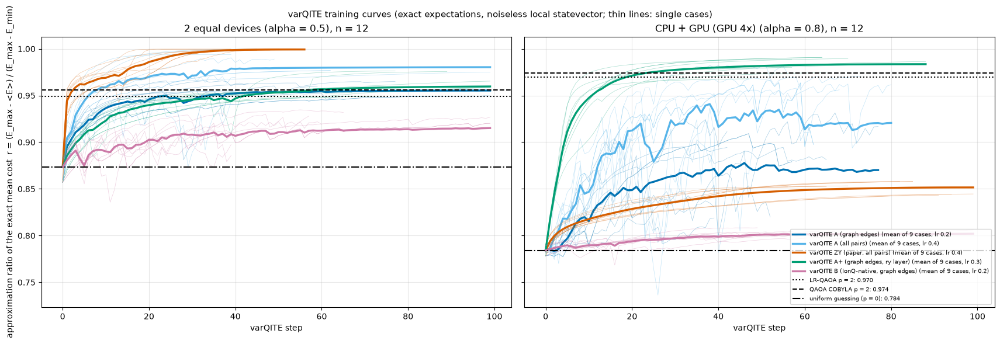

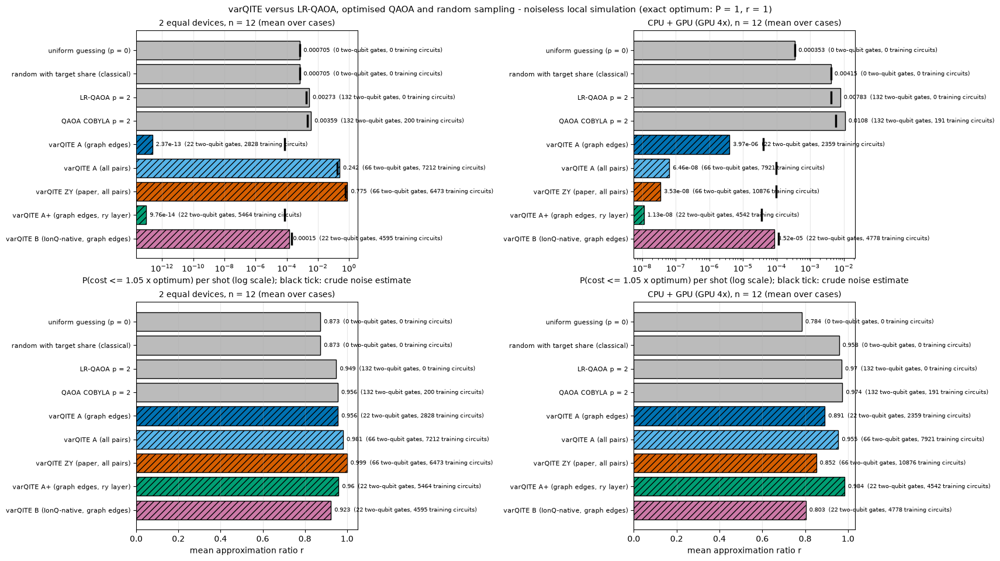

TASK 04b RESULT: varQITE trained on 18 instances x up to 5 ansatz variants = 90 runs (mode 'small'); measured wall-clock 3 s (step-size calibration 0 s)
  method: arXiv:2404.16135 (IonQ + ORNL). Each step: E = <H>; d_k = -(<P_k H> - <P_k><H>); G[k, j] = d<P_k>/d theta_j by parameter shift; G dtheta = d by least squares (rcond 0.01); theta <- theta + lr dtheta. Exact expectations, noiseless.
  stopping: at most 100 steps, at least 40, stop after 10 steps without an improvement of 0.0001 in the approximation ratio; the parameters with the lowest energy are kept
  step size lr, chosen per variant and scenario on the Task 04 calibration meshes (grid 0.05, 0.1, 0.2, 0.3, 0.4):
    equal   varQITE A (graph edges)                  lr = 0.4  (calibration mean r: 0.05: 0.948, 0.1: 0.961, 0.2: 0.966, 0.3: 0.962, 0.4: 0.968)
    equal   varQITE A (all pairs)                    lr = 0.4  (calibration mean r: 0.1: 0.976, 0.2: 0.976, 0.4: 0.985)
    equal   varQITE ZY (paper, all pairs)            l

In [11]:
# TASK_04B_IMPLEMENTATION_CELL_START
# Task 04b: varQITE (variational quantum imaginary time evolution) as an extra method in the Task 04 benchmark.
# Method: T. D. Morris, A. Kaushik, M. Roetteler, P. C. Lotshaw, "Performant near-term quantum combinatorial optimization",
# arXiv:2404.16135 (2024); used by IonQ + Ansys for graph partitioning in LS-DYNA (arXiv:2503.13128).
# Implemented from the team's written description and the paper; no code copied from any other notebook.
# Training: noiseless local statevector with exact expectations. Only the final trained circuit is meant for the IonQ batch.
import gzip
import hashlib
import json
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

VARQITE = dict(
    # ansatz variants (all parameters start at 0 unless stated)
    variants={
        "varQITE A (graph edges)": dict(ansatz="A", edges="graph"),        # team spec: H; per edge ry(theta, j), cx(i, j)
        "varQITE A (all pairs)": dict(ansatz="A", edges="all"),
        "varQITE ZY (paper, all pairs)": dict(ansatz="ZY", edges="all"),   # paper Eq. (3): prod exp(i theta Z_r Y_q) on |+>^n
        "varQITE A+ (graph edges, ry layer)": dict(ansatz="A+", edges="graph"),   # OUR extension: one ry per qubit first
        "varQITE B (IonQ-native, graph edges)": dict(ansatz="B", edges="graph"),  # rzz(theta, i, j) per edge + one rx layer
    },
    all_pairs_max_qubits=12,          # all-pairs variants only up to this size (cost grows with the square of the gate count)
    max_qubits=16,                    # varQITE is trained on a local statevector up to this size
    lr_grid=(0.05, 0.1, 0.2, 0.3, 0.4),   # step size of theta <- theta + lr * dtheta (chosen on the calibration meshes)
    lr_grid_all_pairs=(0.1, 0.2, 0.4),    # shorter grid for the two all-pairs variants (their training is 10-20x more expensive)
    threads=4,                            # independent trainings run in parallel threads (results do not depend on this)
    max_steps=100, min_steps=40, patience=10, improvement_tol=1e-4,   # stop when the approximation ratio stops improving
    rcond=1e-2,                       # least-squares cut-off: singular values below 1 % of the largest are discarded (paper)
    rx_layer_start=-np.pi / 4,        # ansatz B: rx angles start here (at all-zero parameters every gradient of B vanishes)
    use_checkpoint=True,
)
VARQITE.update(globals().get("VARQITE_OVERRIDES", {}))
VQ_RESULTS_DIR = Path("results")
VQ_CHECKPOINT = VQ_RESULTS_DIR / f"varqite_checkpoint_{RUN_MODE}.json.gz"
VQ_SHIFT = {"ry": (np.pi / 2, 0.5), "rzz": (np.pi / 2, 0.5), "rx": (np.pi / 2, 0.5), "zy": (np.pi / 4, 1.0)}  # (shift, factor)


# ------------------------------------------------------------------ circuits ----
def vq_edges(inst, edge_set):
    """Edges of the ansatz, ordered by vertex importance rho_j = sum_k |J_jk| (paper, Suppl. Eq. S10): the more important
    vertex is the control (Z side), edges sorted by (rank of control, rank of target). 'graph' = neighbouring regions only."""
    n, J = inst["n"], inst["model"]["J_scaled"]
    rho = np.abs(J + J.T).sum(axis=1)
    rank = np.empty(n, dtype=int)
    rank[np.argsort(-rho, kind="stable")] = np.arange(n)
    pairs = inst["regions"]["region_pairs"] if edge_set == "graph" else np.array([(i, j) for i in range(n) for j in range(i + 1, n)])
    oriented = [(int(a), int(b)) if rank[a] < rank[b] else (int(b), int(a)) for a, b in pairs]
    return sorted(oriented, key=lambda e: (rank[e[0]], rank[e[1]]))


def vq_gate_list(inst, spec):
    """Gate sequence after the Hadamard layer: (kind, qubits, parameter index or None)."""
    n, edges, gates, index = inst["n"], vq_edges(inst, spec["edges"]), [], 0
    if spec["ansatz"] == "A+":
        for q in range(n):
            gates.append(("ry", (q,), index))
            index += 1
    for control, target in edges:
        if spec["ansatz"] in ("A", "A+"):
            gates += [("ry", (target,), index), ("cx", (control, target), None)]
        elif spec["ansatz"] == "ZY":
            gates.append(("zy", (control, target), index))
        else:
            gates.append(("rzz", (control, target), index))
        index += 1
    if spec["ansatz"] == "B":
        for q in range(n):
            gates.append(("rx", (q,), index))
            index += 1
    return gates, index


def vq_initial_parameters(spec, gates, n_params):
    params = np.zeros(n_params)
    if spec["ansatz"] == "B":
        params[[g[2] for g in gates if g[0] == "rx"]] = VARQITE["rx_layer_start"]
    return params


VQ_INDEX_CACHE = {}


def vq_bit_index(n, qubits):
    """Index arrays of the state vector grouped by the values of the given bits (qubit q = bit q of the index)."""
    key = (n, qubits)
    if key not in VQ_INDEX_CACHE:
        k = np.arange(2**n)
        bits = [(k >> q) & 1 for q in qubits]
        if len(qubits) == 1:
            VQ_INDEX_CACHE[key] = (k[bits[0] == 0], k[bits[0] == 1])
        else:
            VQ_INDEX_CACHE[key] = {(a, b): k[(bits[0] == a) & (bits[1] == b)] for a in (0, 1) for b in (0, 1)}
    return VQ_INDEX_CACHE[key]


def vq_apply(state, gate, value, n):
    """Apply one gate in place-free form. ry(t) = exp(-i t Y/2); rx(t) = exp(-i t X/2); rzz(t) = exp(-i t ZZ/2);
    cx(control, target); zy(t) = exp(i t Z_control Y_target) (paper Eq. 3)."""
    kind, qubits, _ = gate
    state = state.copy()
    if kind in ("ry", "rx"):
        i0, i1 = vq_bit_index(n, qubits)
        c, s = np.cos(value / 2), np.sin(value / 2)
        v0, v1 = state[i0], state[i1]
        if kind == "ry":
            state[i0], state[i1] = c * v0 - s * v1, s * v0 + c * v1
        else:
            state[i0], state[i1] = c * v0 - 1j * s * v1, -1j * s * v0 + c * v1
    elif kind == "cx":
        idx = vq_bit_index(n, qubits)
        state[idx[(1, 0)]], state[idx[(1, 1)]] = state[idx[(1, 1)]], state[idx[(1, 0)]].copy()
    elif kind == "zy":                                # control bit 0 (Z = +1): RY(-2t) on the target; bit 1: RY(+2t)
        idx = vq_bit_index(n, qubits)
        for a, angle in ((0, -2.0 * value), (1, 2.0 * value)):
            c, s = np.cos(angle / 2), np.sin(angle / 2)
            v0, v1 = state[idx[(a, 0)]], state[idx[(a, 1)]]
            state[idx[(a, 0)]], state[idx[(a, 1)]] = c * v0 - s * v1, s * v0 + c * v1
    elif kind == "rzz":
        idx = vq_bit_index(n, qubits)
        for (a, b), positions in idx.items():
            state[positions] *= np.exp(-0.5j * value * (1 - 2 * a) * (1 - 2 * b))
    return state


def vq_complex(spec):
    return spec["ansatz"] == "B"


def vq_statevector(gates, params, n, spec, start=None, from_gate=0):
    state = np.full(2**n, 2.0 ** (-n / 2), dtype=complex if vq_complex(spec) else float) if start is None else start
    for gate in gates[from_gate:]:
        state = vq_apply(state, gate, None if gate[2] is None else params[gate[2]], n)
    return state


def vq_apply_rows(rows, gate, value, n):
    """Apply one gate (same angle) to every row of a batch of state vectors (rows x 2^n)."""
    kind, qubits, _ = gate
    count = rows.shape[0]
    if kind in ("ry", "rx"):
        q = qubits[0]
        v = rows.reshape(count, 2 ** (n - q - 1), 2, 2**q)
        c, s = np.cos(value / 2), np.sin(value / 2)
        out = np.empty_like(v)
        a0, a1 = v[:, :, 0, :], v[:, :, 1, :]
        if kind == "ry":
            out[:, :, 0, :], out[:, :, 1, :] = c * a0 - s * a1, s * a0 + c * a1
        else:
            out[:, :, 0, :], out[:, :, 1, :] = c * a0 - 1j * s * a1, -1j * s * a0 + c * a1
        return out.reshape(count, -1)
    if kind == "rzz":
        k = np.arange(2**n)
        same = (((k >> qubits[0]) ^ (k >> qubits[1])) & 1) == 0
        return rows * np.where(same, np.exp(-0.5j * value), np.exp(0.5j * value))[None, :]
    hi, lo = max(qubits), min(qubits)
    v = rows.reshape(count, 2 ** (n - 1 - hi), 2, 2 ** (hi - lo - 1), 2, 2**lo)
    axis = {hi: 2, lo: 4}
    control_axis, target_axis = axis[qubits[0]], axis[qubits[1]]
    out = np.empty_like(v)
    for a in (0, 1):
        index = [slice(None)] * 6
        index[control_axis] = a
        sub = v[tuple(index)]
        reduced_target = target_axis if target_axis < control_axis else target_axis - 1
        if kind == "cx":
            out[tuple(index)] = np.flip(sub, axis=reduced_target) if a == 1 else sub
        else:                                         # zy: control bit 0 (Z = +1) -> RY(-2t) on the target, bit 1 -> RY(+2t)
            angle = -2.0 * value if a == 0 else 2.0 * value
            c, s = np.cos(angle / 2), np.sin(angle / 2)
            s0, s1 = np.take(sub, 0, axis=reduced_target), np.take(sub, 1, axis=reduced_target)
            out[tuple(index)] = np.stack([c * s0 - s * s1, s * s0 + c * s1], axis=reduced_target)
    return out.reshape(count, -1)


def vq_probabilities_with_shifts(gates, params, n, spec):
    """Probabilities of the circuit at `params` (row 0) and with each parameter shifted by +s and -s (rows 1 .. 2m, in gate
    order). All rows run through the gates together: at a parametrised gate the two shifted copies of the current state are
    added to the batch (parameter-shift rule)."""
    shifted_gates = [g for g in gates if g[2] is not None]
    rows = np.zeros((1 + 2 * len(shifted_gates), 2**n), dtype=complex if vq_complex(spec) else float)
    rows[0] = 2.0 ** (-n / 2)
    active = 1
    for gate in gates:
        if gate[2] is None:
            rows[:active] = vq_apply_rows(rows[:active], gate, None, n)
            continue
        value, shift = params[gate[2]], VQ_SHIFT[gate[0]][0]
        base = rows[0:1].copy()
        rows[active] = vq_apply_rows(base, gate, value + shift, n)[0]
        rows[active + 1] = vq_apply_rows(base, gate, value - shift, n)[0]
        rows[:active] = vq_apply_rows(rows[:active], gate, value, n)
        active += 2
    return np.abs(rows) ** 2, shifted_gates


def vq_qiskit_circuit(gates, params, n, measure=False):
    """The same circuit in Qiskit (zy is decomposed as sdg, h, rzz(-2 theta), h, s on the target: one native two-qubit gate)."""
    circuit = QuantumCircuit(n)
    circuit.h(range(n))
    for kind, qubits, index in gates:
        value = None if index is None else float(params[index])
        if kind == "ry":
            circuit.ry(value, qubits[0])
        elif kind == "rx":
            circuit.rx(value, qubits[0])
        elif kind == "cx":
            circuit.cx(*qubits)
        elif kind == "rzz":
            circuit.rzz(value, *qubits)
        elif kind == "zy":
            control, target = qubits
            circuit.sdg(target)
            circuit.h(target)
            circuit.rzz(-2.0 * value, control, target)
            circuit.h(target)
            circuit.s(target)
    if measure:
        circuit.measure_all()
    return circuit


# ------------------------------------------------------------------ training ----
def vq_pauli_features(inst):
    """Every Pauli term P_k of the scaled cost H: Z_i Z_j for each non-zero coupling, Z_i for each non-zero field.
    Returns (feature matrix 2^n x K with the +-1 values of each P_k on each basis state, coefficients c_k, scaled H per state)."""
    n, J, h = inst["n"], inst["model"]["J_scaled"], inst["model"]["h_scaled"]
    z = 1.0 - 2.0 * state_index_to_x(np.arange(2**n), n)
    columns, coefficients = [], []
    for i in range(n):
        for j in range(i + 1, n):
            if J[i, j] != 0:
                columns.append(z[:, i] * z[:, j])
                coefficients.append(J[i, j])
    for i in range(n):
        if h[i] != 0:
            columns.append(z[:, i])
            coefficients.append(h[i])
    features, coefficients = np.array(columns).T, np.array(coefficients)
    return features, coefficients, features @ coefficients


def vq_step_quantities(probs_rows, shifted_gates, features, h_scaled_states):
    """E = <H>; d_k = -(<P_k H> - <P_k><H>); G[k, j] = d<P_k>/d theta_j by the parameter-shift rule."""
    p0 = probs_rows[0]
    expect = probs_rows @ features                              # <P_k> for every circuit (rows)
    energy = float(p0 @ h_scaled_states)
    d = -(features.T @ (p0 * h_scaled_states) - expect[0] * energy)
    factors = np.array([VQ_SHIFT[g[0]][1] for g in shifted_gates])
    G = ((expect[1::2] - expect[2::2]) * factors[:, None]).T   # K x m
    return energy, d, G


def vq_train(inst, spec, lr, keep_history=True):
    """varQITE: theta <- theta + lr * dtheta with G dtheta = d solved by least squares (rcond). Exact expectations.
    The returned parameters are those with the lowest exact energy seen. (Paper: G_paper = G / 2, so lr = 2 x its time step.)"""
    n = inst["n"]
    gates, n_params = vq_gate_list(inst, spec)
    params = vq_initial_parameters(spec, gates, n_params)
    features, _, h_states = vq_pauli_features(inst)
    spread = inst["e_max"] - inst["e_min"]
    best = dict(ratio=-np.inf, params=params.copy(), step=0)
    history, circuits, step = [], 0, 0
    for step in range(VARQITE["max_steps"]):
        probs_rows, shifted = vq_probabilities_with_shifts(gates, params, n, spec)
        circuits += probs_rows.shape[0]
        energy_scaled, d, G = vq_step_quantities(probs_rows, shifted, features, h_states)
        cost = float(probs_rows[0] @ inst["energies"])
        ratio = (inst["e_max"] - cost) / spread
        dtheta, _, rank, _ = np.linalg.lstsq(G, d, rcond=VARQITE["rcond"])
        if keep_history:
            history.append(dict(step=step, cost=cost, ratio=ratio, energy_scaled=energy_scaled, rank=int(rank), step_norm=float(np.linalg.norm(dtheta))))
        if ratio > best["ratio"] + VARQITE["improvement_tol"]:
            best = dict(ratio=ratio, params=params.copy(), step=step)
        elif ratio > best["ratio"]:
            best["params"], best["ratio"] = params.copy(), ratio
        if step + 1 >= VARQITE["min_steps"] and step - best["step"] >= VARQITE["patience"]:
            break
        params = params + lr * dtheta
    return dict(params=best["params"], best_ratio=best["ratio"], best_step=best["step"], steps=step + 1, circuits=circuits,
                history=history, gates=gates, n_params=n_params)


# ------------------------------------------------------------- calibration ----
vq_clock = time.perf_counter()
vq_instance_keys = [key for key in task04_ising_cases if key[0] in RUN["quantum_cases"] and key[1] <= VARQITE["max_qubits"]]
vq_skipped = [f"{'|'.join(map(str, key))}: varQITE not run (n = {key[1]} > {VARQITE['max_qubits']})"
              for key in task04_ising_cases if key[0] in RUN["quantum_cases"] and key[1] > VARQITE["max_qubits"]]


def vq_variants_for(n):
    return {name: spec for name, spec in VARQITE["variants"].items() if spec["edges"] == "graph" or n <= VARQITE["all_pairs_max_qubits"]}


def vq_run_one(job):
    """Train one variant on one instance and evaluate the final circuit. Returns (cache key, entry or error text)."""
    key, name, inst = job
    spec, n, view = VARQITE["variants"][name], inst["n"], t4_view(inst)
    try:
        clock = time.perf_counter()
        lr = vq_lr[(key[3], name)]["lr"]
        trained = vq_train(inst, spec, lr)
        wall = time.perf_counter() - clock
        probs = np.abs(vq_statevector(trained["gates"], trained["params"], n, spec)) ** 2
        sampled, full_states = sampled_metrics(probs, view, [TASK04["start_seed"], t4_key_seed(key), 77])
        circuit = vq_qiskit_circuit(trained["gates"], trained["params"], n)
        entry = dict(fingerprint=inst["fingerprint"], variant=name, lr=lr, params=trained["params"], steps=trained["steps"],
                     best_step=trained["best_step"], training_circuits=trained["circuits"], n_params=trained["n_params"],
                     measured_wall_seconds=wall, history=trained["history"],
                     two_qubit_gates=int(sum(1 for instruction in circuit.data if instruction.operation.num_qubits == 2)),
                     depth=int(circuit.depth()), **distribution_metrics(probs, view), **sampled,
                     outcome=modelled_outcome(inst, sampled["best_state"]),
                     outcome_runtime_scored=modelled_outcome(inst, int(full_states[np.argmin(inst["modelled_hours_all"][full_states])])),
                     control_marginals=[float(probs[vq_bit_index(n, (q,))[1]].sum()) for q in range(n)])
        return key, name, t4_jsonable(entry)
    except Exception as error:                        # recorded and reported, never replaced by invented values
        return key, name, f"{type(error).__name__}: {error}"


vq_config_hash = hashlib.sha256(json.dumps(t4_jsonable({k: v for k, v in VARQITE.items() if k not in ("use_checkpoint", "threads")}),
                                           sort_keys=True).encode()).hexdigest()[:16]
vq_cell_file = vq_train.__code__.co_filename
VQ_CODE_HASH = hashlib.sha256(b"".join(t4_code_digest(value.__code__) for name, value in sorted(globals().items())
                                       if callable(value) and getattr(getattr(value, "__code__", None), "co_filename", None) == vq_cell_file)).hexdigest()[:16]
# parallel runs outside the notebook: VARQITE_SHARD = "calibration" (step-size calibration only) or (index, count)
VQ_SHARD = globals().get("VARQITE_SHARD")
VQ_SAVE_PATH = (VQ_CHECKPOINT.with_name(VQ_CHECKPOINT.name.replace(".json.gz", f".shard{VQ_SHARD[0]}of{VQ_SHARD[1]}.json.gz"))
                if isinstance(VQ_SHARD, tuple) else VQ_CHECKPOINT)
vq_cache = {}
if VARQITE["use_checkpoint"] and VQ_CHECKPOINT.exists():
    with gzip.open(VQ_CHECKPOINT, "rt") as handle:
        stored = json.load(handle)
    if (stored.get("config_hash") == vq_config_hash and stored.get("code_hash") == VQ_CODE_HASH and stored.get("task04_code_hash") == T4_CODE_HASH
            and stored.get("task04_config_hash") == T4_CONFIG_HASH):
        vq_cache = stored["entries"]


if isinstance(VQ_SHARD, tuple):                     # a shard reads the main checkpoint but saves to its own file
    VQ_CHECKPOINT = VQ_SAVE_PATH


def vq_save_checkpoint():
    if VARQITE["use_checkpoint"]:
        with gzip.open(VQ_CHECKPOINT, "wt") as handle:
            json.dump(dict(config_hash=vq_config_hash, code_hash=VQ_CODE_HASH, task04_code_hash=T4_CODE_HASH, task04_config_hash=T4_CONFIG_HASH,
                           entries=vq_cache), handle)


# step size chosen once per variant and scenario on the Task 04 calibration meshes (never on scored instances)
vq_lr = {}
for scenario in TARGET_SHARES:
    for name, spec in vq_variants_for(TASK04["calibration_n"]).items():
        cache_key = f"calibration|{scenario}|{name}"
        grid = VARQITE["lr_grid_all_pairs"] if spec["edges"] == "all" else VARQITE["lr_grid"]
        if cache_key not in vq_cache:
            jobs = [(lr, inst) for lr in grid for inst in calibration_instances[scenario]]
            with ThreadPoolExecutor(VARQITE["threads"]) as pool:
                ratios = list(pool.map(lambda job: vq_train(job[1], spec, job[0], keep_history=False)["best_ratio"], jobs))
            scores = {str(lr): float(np.mean([r for (job_lr, _), r in zip(jobs, ratios) if job_lr == lr])) for lr in grid}
            vq_cache[cache_key] = scores
            vq_save_checkpoint()
        scores = vq_cache[cache_key]
        best_lr = max(grid, key=lambda lr: (round(scores[str(lr)], 9), -lr))
        vq_lr[(scenario, name)] = dict(lr=best_lr, scores=scores, grid=grid)
vq_calibration_seconds = time.perf_counter() - vq_clock
if VQ_SHARD == "calibration":
    raise SystemExit(f"varQITE step-size calibration finished in {vq_calibration_seconds:.0f} s")

# ------------------------------------------------------------------ benchmark ----
varqite_results, varqite_ionq_circuits, vq_failures = {}, {}, []
vq_examples, vq_instances = {}, {}
for key in vq_instance_keys:
    vq_instances[key] = t4_build_instance(region_cases[key[:3]], *key)
    if key[3] not in vq_examples and key[1] == min(RUN["region_counts"]):
        vq_examples[key[3]] = vq_instances[key]
vq_jobs = [(key, name, inst) for key, inst in vq_instances.items() for name in vq_variants_for(key[1])
           if vq_cache.get("|".join(map(str, key)) + "|" + name, {}).get("fingerprint") != inst["fingerprint"]]
if isinstance(VQ_SHARD, tuple):
    vq_jobs = vq_jobs[VQ_SHARD[0]::VQ_SHARD[1]]
for start in range(0, len(vq_jobs), 4 * VARQITE["threads"]):          # save the checkpoint after every chunk
    with ThreadPoolExecutor(VARQITE["threads"]) as pool:
        for key, name, outcome in pool.map(vq_run_one, vq_jobs[start:start + 4 * VARQITE["threads"]]):
            if isinstance(outcome, str):
                vq_failures.append(dict(key="|".join(map(str, key)) + "|" + name, error=outcome))
            else:
                vq_cache["|".join(map(str, key)) + "|" + name] = outcome
    vq_save_checkpoint()
for key, inst in vq_instances.items():
    for name, spec in vq_variants_for(key[1]).items():
        entry = vq_cache.get("|".join(map(str, key)) + "|" + name)
        if entry is None or entry.get("fingerprint") != inst["fingerprint"]:
            continue
        gates, _ = vq_gate_list(inst, spec)
        varqite_results[key + (name,)] = entry
        varqite_ionq_circuits[key + (name,)] = vq_qiskit_circuit(gates, np.array(entry["params"]), key[1], measure=True)
if isinstance(VQ_SHARD, tuple):
    raise SystemExit(f"varQITE shard {VQ_SHARD[0]} of {VQ_SHARD[1]} finished ({len(vq_jobs)} trainings, {len(vq_failures)} failures)")
vq_benchmark_seconds = time.perf_counter() - vq_clock - vq_calibration_seconds

# ------------------------------------------------------------------ tests ----
vq_tests = {}
test_rng = np.random.default_rng(404)
for scenario, inst in vq_examples.items():
    features, coefficients, h_states = vq_pauli_features(inst)
    assert np.allclose(h_states, inst["energy_scaled"], atol=1e-9), "Pauli expansion does not reproduce the scaled cost"
    for name, spec in vq_variants_for(inst["n"]).items():
        gates, n_params = vq_gate_list(inst, spec)
        params = test_rng.uniform(-1.0, 1.0, n_params)
        # numpy = Qiskit (random parameters and trained parameters)
        for trial in (params, np.array(varqite_results[(inst["case"], inst["n"], inst["seed"], scenario, name)]["params"])):
            mine = np.abs(vq_statevector(gates, trial, inst["n"], spec)) ** 2
            assert np.max(np.abs(Statevector(vq_qiskit_circuit(gates, trial, inst["n"])).probabilities() - mine)) < 1e-10, f"{name}: Qiskit differs"
        # parameter-shift derivatives = finite differences of the exact expectation values
        probs_rows, shifted = vq_probabilities_with_shifts(gates, params, inst["n"], spec)
        energy, d, G = vq_step_quantities(probs_rows, shifted, features, h_states)
        for j in test_rng.choice(n_params, size=min(4, n_params), replace=False):
            step = np.zeros(n_params)
            step[j] = 1e-5
            plus = (np.abs(vq_statevector(gates, params + step, inst["n"], spec)) ** 2) @ features
            minus = (np.abs(vq_statevector(gates, params - step, inst["n"], spec)) ** 2) @ features
            assert np.allclose(G[:, j], (plus - minus) / 2e-5, atol=1e-6), f"{name}: parameter-shift gradient is wrong"
        # sum_k c_k d_k = -Var(H), and a small step along dtheta lowers the energy
        variance = probs_rows[0] @ h_states**2 - energy**2
        assert np.isclose(coefficients @ d, -variance, atol=1e-10), "d is not the imaginary-time direction"
        dtheta = np.linalg.lstsq(G, d, rcond=VARQITE["rcond"])[0]
        lower = (np.abs(vq_statevector(gates, params + 1e-3 * dtheta, inst["n"], spec)) ** 2) @ h_states
        assert lower < energy, f"{name}: a small varQITE step does not lower the energy"
    # all-zero parameters of ansatz B: every derivative vanishes (why its rx layer starts at a non-zero angle)
    spec_b = VARQITE["variants"]["varQITE B (IonQ-native, graph edges)"]
    gates_b, m_b = vq_gate_list(inst, spec_b)
    rows_b, shifted_b = vq_probabilities_with_shifts(gates_b, np.zeros(m_b), inst["n"], spec_b)
    assert np.allclose(vq_step_quantities(rows_b, shifted_b, features, h_states)[2], 0.0, atol=1e-12)
    # ansatz A: a qubit that is never a target keeps a 50/50 marginal
    spec_a = VARQITE["variants"]["varQITE A (graph edges)"]
    gates_a, m_a = vq_gate_list(inst, spec_a)
    never_target = sorted(set(range(inst["n"])) - {g[1][-1] for g in gates_a if g[0] in ("ry", "cx")})
    probs_a = np.abs(vq_statevector(gates_a, test_rng.uniform(-2, 2, m_a), inst["n"], spec_a)) ** 2
    assert all(np.isclose(probs_a[vq_bit_index(inst["n"], (q,))[1]].sum(), 0.5) for q in never_target)
vq_tests["Pauli expansion, numpy = Qiskit, parameter shift = finite differences, d = imaginary-time direction, small step lowers E"] = f"passed ({len(vq_examples)} instances, {len(VARQITE['variants'])} ansatz variants)"
vq_tests["ansatz B at all-zero parameters has zero gradient; ansatz A keeps 50/50 on qubits that are never a target"] = "passed"
for key, entry in varqite_results.items():
    m = entry["n_params"]
    assert entry["training_circuits"] == entry["steps"] * (2 * m + 1), "circuit count does not match steps x (2m + 1)"
    assert np.isfinite(entry["p_near"]) and 0 <= entry["p_opt"] <= entry["p_near"] + 1e-12 <= 1 + 1e-9
vq_tests["training circuits = steps x (2m + 1); finite, consistent metrics"] = f"passed ({len(varqite_results)} runs)"
repeat_key = next(iter(varqite_results)) if varqite_results else None
if repeat_key:
    repeat_inst = t4_build_instance(region_cases[repeat_key[:3]], *repeat_key[:4])
    again = vq_train(repeat_inst, VARQITE["variants"][repeat_key[4]], varqite_results[repeat_key]["lr"], keep_history=False)
    assert np.allclose(again["params"], varqite_results[repeat_key]["params"], atol=1e-10), "varQITE training is not reproducible"
    vq_tests["deterministic training (rerun gives the same parameters)"] = "passed"

# ---------------------------------------------------------------- comparison ----
noise_error = TASK04["noise_error_per_two_qubit_gate"]
vq_rows = []
for key, entry in varqite_results.items():
    uniform_group = qaoa_results.get(key[:4] + ("uniform control", "none", 0))
    if uniform_group is None:
        continue
    fidelity = (1.0 - noise_error) ** entry["two_qubit_gates"]
    vq_rows.append(dict(case=key[0], n=key[1], seed=key[2], scenario=key[3], method=key[4], two_qubit_gates=entry["two_qubit_gates"],
                        training_circuits=entry["training_circuits"], steps=entry["steps"], lr=entry["lr"], p_opt=entry["p_opt"], p_near=entry["p_near"],
                        mean_ratio=entry["mean_ratio"], p_balanced=entry["p_balanced"], hit_near=entry["hit_near"],
                        p_near_noise_estimate=fidelity * entry["p_near"] + (1 - fidelity) * uniform_group["uniform_p_near"],
                        modelled_hours=entry["outcome"]["modelled_hours"]))
vq_reference_methods = [("uniform guessing (p = 0)", ("uniform control", "none", 0)), (f"LR-QAOA p = {T4_P_MAIN}", ("LR-QAOA", "fixed schedule", T4_P_MAIN)),
                        (f"QAOA COBYLA p = {T4_P_MAIN}", ("QAOA", "COBYLA", T4_P_MAIN))]
for key in {row_key[:4] for row_key in varqite_results}:
    for label, suffix in vq_reference_methods:
        group = qaoa_results.get(key + suffix)
        if group is None:
            continue
        run = group["runs"][0]
        fidelity = (1.0 - noise_error) ** group["two_qubit_gates"]
        vq_rows.append(dict(case=key[0], n=key[1], seed=key[2], scenario=key[3], method=label, two_qubit_gates=group["two_qubit_gates"],
                            training_circuits=run["n_evals"], steps=0, lr=float("nan"), p_opt=run["p_opt"], p_near=run["p_near"], mean_ratio=run["mean_ratio"],
                            p_balanced=run["p_balanced"], hit_near=run["hit_near"],
                            p_near_noise_estimate=fidelity * run["p_near"] + (1 - fidelity) * group["uniform_p_near"], modelled_hours=run["outcome"]["modelled_hours"]))
    share = classical_results[key + ("random with target share",)].get("per_shot")
    if share:
        vq_rows.append(dict(case=key[0], n=key[1], seed=key[2], scenario=key[3], method="random with target share (classical)", two_qubit_gates=0,
                            training_circuits=0, steps=0, lr=float("nan"), p_opt=share["p_opt"], p_near=share["p_near"], mean_ratio=share["mean_ratio"],
                            p_balanced=share["p_balanced"], hit_near=share["hit_near"], p_near_noise_estimate=share["p_near"], modelled_hours=float("nan")))
VQ_METHOD_ORDER = [label for label, _ in vq_reference_methods[:1]] + ["random with target share (classical)"] + [label for label, _ in vq_reference_methods[1:]] + list(VARQITE["variants"])


def vq_summary(scenario, method, n):
    rows = [row for row in vq_rows if row["scenario"] == scenario and row["method"] == method and row["n"] == n]
    if not rows:
        return None
    mean = {field: float(np.mean([row[field] for row in rows])) for field in ("two_qubit_gates", "training_circuits", "steps", "p_opt", "p_near",
                                                                              "mean_ratio", "p_balanced", "hit_near", "p_near_noise_estimate")}
    mean["instances"] = len(rows)
    return mean


# ------------------------------------------------------------------ plots ----
VQ_COLOURS = {name: colour for name, colour in zip(VARQITE["variants"], ["#0072B2", "#56B4E9", "#D55E00", "#009E73", "#CC79A7"])}
vq_plot_paths = []
vq_n_plot = min(RUN["region_counts"])
fig, axes = plt.subplots(1, len(TARGET_SHARES), figsize=(8.5 * len(TARGET_SHARES), 5.6), constrained_layout=True, sharey=True)
for ax, scenario in zip(np.atleast_1d(axes), TARGET_SHARES):
    for name in VARQITE["variants"]:
        curves = [np.array([h["ratio"] for h in entry["history"]]) for key, entry in varqite_results.items()
                  if key[3] == scenario and key[4] == name and key[1] == vq_n_plot]
        if not curves:
            continue
        length = max(len(c) for c in curves)
        padded = np.array([np.concatenate([c, np.full(length - len(c), c[-1])]) for c in curves])   # a stopped run keeps its last value
        for curve in curves:
            ax.plot(curve, color=VQ_COLOURS[name], lw=0.5, alpha=0.35)
        ax.plot(padded.mean(axis=0), color=VQ_COLOURS[name], lw=2.4, label=f"{name} (mean of {len(curves)} cases, lr {vq_lr[(scenario, name)]['lr']})")
    for label, style in ((f"LR-QAOA p = {T4_P_MAIN}", ":"), (f"QAOA COBYLA p = {T4_P_MAIN}", "--"), ("uniform guessing (p = 0)", "-.")):
        summary = vq_summary(scenario, label, vq_n_plot)
        if summary:
            ax.axhline(summary["mean_ratio"], color="black", ls=style, lw=1.5, label=f"{label}: {summary['mean_ratio']:.3f}")
    ax.set_xlabel("varQITE step")
    ax.set_title(f"{scenario} (alpha = {TARGET_SHARES[scenario]}), n = {vq_n_plot}")
    ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("approximation ratio of the exact mean cost  r = (E_max - <E>) / (E_max - E_min)")
np.atleast_1d(axes)[-1].legend(fontsize=7.5, loc="lower right")
fig.suptitle("varQITE training curves (exact expectations, noiseless local statevector; thin lines: single cases)", fontsize=11)
vq_plot_paths.append(VQ_RESULTS_DIR / f"varqite_energy_curves_{RUN_MODE}.png")
fig.savefig(vq_plot_paths[-1], dpi=110)
plt.show()

fig, axes = plt.subplots(2, len(TARGET_SHARES), figsize=(8.5 * len(TARGET_SHARES), 9.5), constrained_layout=True)
axes = np.asarray(axes).reshape(2, -1)
for column, scenario in enumerate(TARGET_SHARES):
    methods = [m for m in VQ_METHOD_ORDER if vq_summary(scenario, m, vq_n_plot)]
    for row_index, (field, label, log) in enumerate((("p_near", "P(cost <= 1.05 x optimum) per shot (log scale)", True), ("mean_ratio", "mean approximation ratio r", False))):
        ax = axes[row_index, column]
        for position, method in enumerate(methods):
            summary = vq_summary(scenario, method, vq_n_plot)
            is_vq = method.startswith("varQITE")
            ax.barh(position, summary[field], color=VQ_COLOURS.get(method, "#BBBBBB"), edgecolor="black", hatch="///" if is_vq else "")
            if field == "p_near":
                ax.plot(summary["p_near_noise_estimate"], position, marker="|", ms=16, mew=2.5, color="black")
            ax.text(summary[field], position, f"  {summary[field]:.3g}  ({summary['two_qubit_gates']:.0f} two-qubit gates, {summary['training_circuits']:.0f} training circuits)",
                    va="center", fontsize=7.5)
        ax.set_yticks(range(len(methods)))
        ax.set_yticklabels(methods, fontsize=8)
        ax.invert_yaxis()
        if log:
            ax.set_xscale("log")
        ax.set_xlabel(label + ("; black tick: crude noise estimate" if field == "p_near" else ""))
        ax.set_title(f"{scenario}, n = {vq_n_plot} (mean over cases)", fontsize=10)
        ax.grid(axis="x", alpha=0.3)
fig.suptitle("varQITE versus LR-QAOA, optimised QAOA and random sampling - noiseless local simulation (exact optimum: P = 1, r = 1)", fontsize=11)
vq_plot_paths.append(VQ_RESULTS_DIR / f"varqite_comparison_{RUN_MODE}.png")
fig.savefig(vq_plot_paths[-1], dpi=110)
plt.show()
for path in vq_plot_paths:
    assert path.exists() and path.stat().st_size < 2_000_000

# ------------------------------------------------------------------ files ----
vq_summary_path = VQ_RESULTS_DIR / f"varqite_summary_{RUN_MODE}.json"
vq_summary_path.write_text(json.dumps(t4_jsonable(dict(
    method="varQITE after Morris, Kaushik, Roetteler, Lotshaw, arXiv:2404.16135 (2024); trained on a noiseless local statevector with exact expectations",
    config=VARQITE, lr_selected={f"{s} | {v}": c for (s, v), c in vq_lr.items()}, tests=vq_tests, skipped=vq_skipped, failures=vq_failures,
    rows=vq_rows, measured_wall_seconds=time.perf_counter() - vq_clock)), indent=1))
assert vq_summary_path.stat().st_size < 2_000_000

# ------------------------------------------------------------------ summary ----
print(f"TASK 04b RESULT: varQITE trained on {len({k[:4] for k in varqite_results})} instances x up to {len(VARQITE['variants'])} ansatz variants "
      f"= {len(varqite_results)} runs (mode '{RUN_MODE}'); measured wall-clock {time.perf_counter() - vq_clock:.0f} s "
      f"(step-size calibration {vq_calibration_seconds:.0f} s)")
print("  method: arXiv:2404.16135 (IonQ + ORNL). Each step: E = <H>; d_k = -(<P_k H> - <P_k><H>); G[k, j] = d<P_k>/d theta_j by parameter shift; "
      f"G dtheta = d by least squares (rcond {VARQITE['rcond']}); theta <- theta + lr dtheta. Exact expectations, noiseless.")
print(f"  stopping: at most {VARQITE['max_steps']} steps, at least {VARQITE['min_steps']}, stop after {VARQITE['patience']} steps without an improvement "
      f"of {VARQITE['improvement_tol']} in the approximation ratio; the parameters with the lowest energy are kept")
print("  step size lr, chosen per variant and scenario on the Task 04 calibration meshes (grid " + ", ".join(map(str, VARQITE["lr_grid"])) + "):")
for (scenario, name), choice in vq_lr.items():
    print(f"    {SCENARIO_SLUGS.get(scenario, scenario):<8}{name:<40} lr = {choice['lr']}  (calibration mean r: " +
          ", ".join(f"{lr}: {choice['scores'][str(lr)]:.3f}" for lr in choice["grid"]) + ")")
print("  tests:")
for name, result in vq_tests.items():
    print(f"    {name}: {result}")
for n in sorted({k[1] for k in varqite_results}):
    print(f"  comparison at n = {n} (mean over cases; per shot; noiseless; 'noise est.' = crude estimate with e = {noise_error} per two-qubit gate):")
    print(f"    {'scenario':<9}{'method':<40}{'2q gates':>9}{'training circuits':>18}{'total evals':>12}{'steps':>6}{'P(opt)':>9}{'P(<=1.05)':>10}{'mean r':>8}"
          f"{'P(bal.)':>8}{'hit 1.05':>9}{'noise est.':>11}")
    print(f"    ('total evals' = hardware-equivalent cost evaluations: (training circuits + 1) x {T4_SHOTS} shots; the classical sampler counts {T4_SHOTS})")
    for scenario in TARGET_SHARES:
        for method in VQ_METHOD_ORDER:
            s = vq_summary(scenario, method, n)
            if s:
                total = T4_SHOTS if method.startswith("random") or method.startswith("uniform") else (s["training_circuits"] + 1) * T4_SHOTS
                print(f"    {SCENARIO_SLUGS.get(scenario, scenario):<9}{method:<40}{s['two_qubit_gates']:>9.0f}{s['training_circuits']:>18.0f}{total:>12,.0f}{s['steps']:>6.0f}"
                      f"{s['p_opt']:>9.4f}{s['p_near']:>10.4f}{s['mean_ratio']:>8.4f}{s['p_balanced']:>8.3f}{s['hit_near']:>9.3f}{s['p_near_noise_estimate']:>11.4f}")
    print("    exact optimum (brute force): P(opt) = 1, r = 1, by definition")
# limitation of ansatz A / ZY with unequal shares, measured
for scenario in TARGET_SHARES:
    capped = [any(abs(m - 0.5) < 1e-9 for m in entry["control_marginals"]) for key, entry in varqite_results.items()
              if key[3] == scenario and key[4] in ("varQITE A (graph edges)", "varQITE A (all pairs)", "varQITE ZY (paper, all pairs)")]
    if capped:
        print(f"  {SCENARIO_SLUGS.get(scenario, scenario)}: in {sum(capped)} of {len(capped)} trained A / ZY circuits at least one qubit has a marginal of exactly 0.5 "
              "(a qubit that is only ever a control cannot leave 50/50); with an unequal share that caps the probability of a unique optimum at 0.5. "
              "Variant A+ (our extension) adds one ry per qubit to remove the cap.")
print(f"  IonQ batch: {len(varqite_ionq_circuits)} final trained circuits with measurement are stored in `varqite_ionq_circuits` for the single IonQ job "
      "(with the p = 0 control and the QAOA circuits). Training stays local and noiseless; only the final sampling is meant for the IonQ Forte 1 noise model.")
print("  fairness note: varQITE spends steps x (2m + 1) training circuits with EXACT expectations (on hardware each would need shots); "
      f"the optimised QAOA variants used at most {TASK04['eval_budget']} evaluations, LR-QAOA none.")
if vq_skipped:
    print(f"  skipped: {len(vq_skipped)} instance(s) above {VARQITE['max_qubits']} qubits")
print(f"  failures: {len(vq_failures)}" + "".join(f"\n    {f['key']}: {f['error']}" for f in vq_failures))
print(f"  files: {vq_summary_path}, {VQ_CHECKPOINT}; plots: {', '.join(str(p) for p in vq_plot_paths)}")
# TASK_04B_IMPLEMENTATION_CELL_END

## Task 04c — The region graph before and after the cut

A picture of what the algorithms decide, from the saved results (nothing is recomputed). For the headline cases and both device scenarios:
1. the original region graph on the mesh (node size = work, line width = border cost);
2. the split returned by QAOA + COBYLA (p = 2): the lowest-cost of 1,000 sampled shots;
3. the split returned by varQITE (the paper's ZY ansatz), chosen the same way;
4. the exact optimum.

Device A is a blue circle, device B an orange square (shape and colour both carry the information); cut borders are dashed. Titles give the work share of device B, the cut cost and the gap to the optimum.

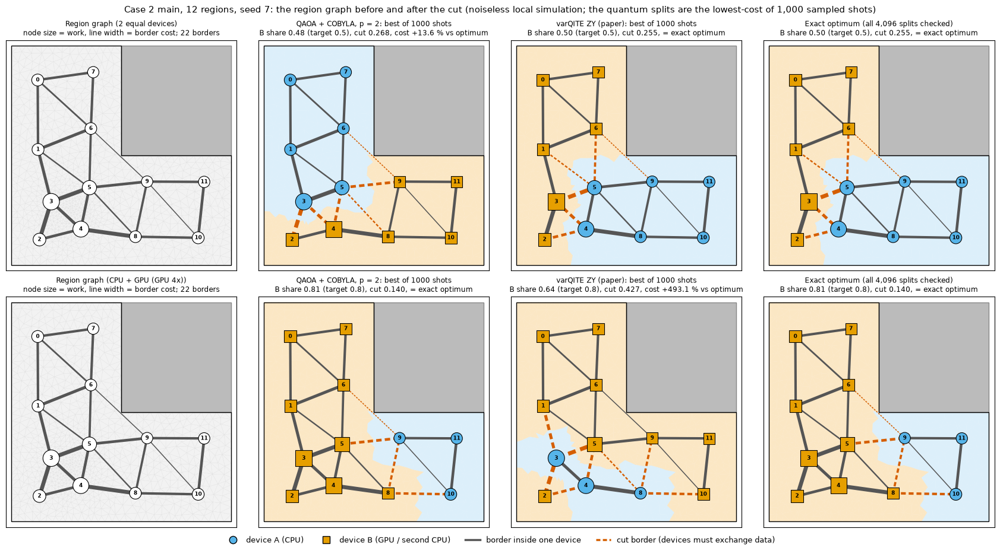

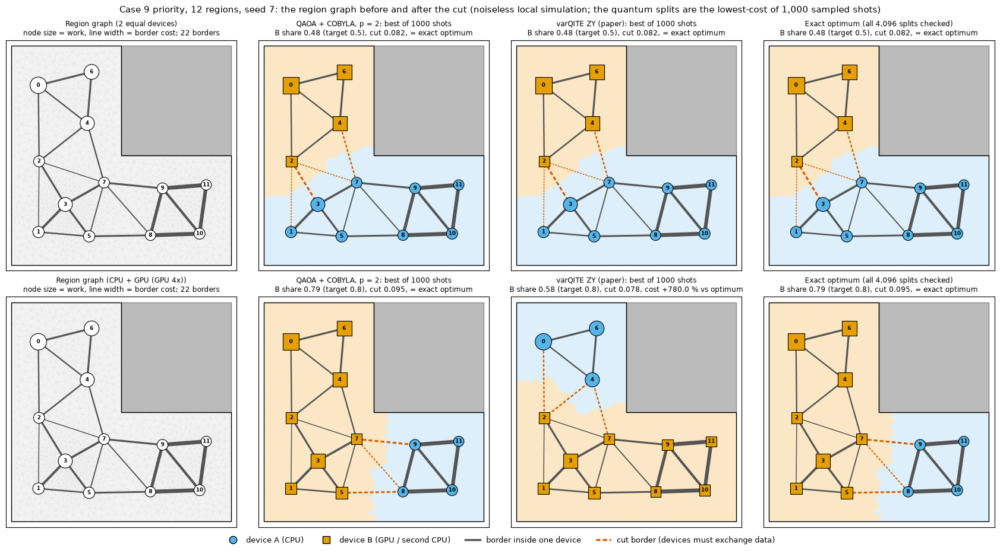

TASK 04c RESULT: 2 figure(s) of the region graph before and after the cut: results/graph_cut_2_main_n12_seed7.png, results/graph_cut_9_priority_n12_seed7.png
  columns: original region graph | QAOA + COBYLA (best of 1,000 shots) | varQITE ZY (best of 1,000 shots) | exact optimum; rows: equal devices, CPU + GPU


In [12]:
# TASK_04C_IMPLEMENTATION_CELL_START
# Task 04c: the region graph before and after the cut - original graph, the split returned by QAOA, the split returned
# by varQITE and the exact optimum, drawn on the mesh. Uses only saved results (nothing is recomputed).
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

GRAPH_FIGURE_CASES = [case for case in ("2 main", "9 priority") if case in RUN["quantum_cases"]] or RUN["quantum_cases"][:1]
GRAPH_N, GRAPH_SEED = min(RUN["region_counts"]), RUN["seeds"][0]
GRAPH_QAOA = ("QAOA", "COBYLA", max(T4_LAYERS))
GRAPH_VARQITE = "varQITE ZY (paper, all pairs)"
COLOUR_A, COLOUR_B, COLOUR_CUT = "#56B4E9", "#E69F00", "#D55E00"
graph_plot_paths = []


def draw_region_graph(ax, case_name, scenario, state=None, title=""):
    """Mesh in the background, region graph on top. state = None: original graph; otherwise the split (bit 1 = device B)."""
    regions = region_cases[(case_name, GRAPH_N, GRAPH_SEED)]
    mesh, spec = regions["mesh"], MESH_CASES[case_name]
    tri_xy = mesh["points"][mesh["triangles"]]
    centres, pairs, cost, work = regions["region_centroids"], regions["region_pairs"], regions["region_boundary_cost"], regions["region_work"]
    if state is None:
        ax.add_collection(PolyCollection(tri_xy, facecolors="#F2F2F2", edgecolors="#DDDDDD", linewidths=0.2))
        bits = np.zeros(GRAPH_N, dtype=int)
    else:
        bits = state_index_to_x(state, GRAPH_N)
        on_b = bits[regions["cell_region"]].astype(bool)
        ax.add_collection(PolyCollection(tri_xy[~on_b], facecolors="#DCEFFA", edgecolors="#DCEFFA", linewidths=0.2))
        ax.add_collection(PolyCollection(tri_xy[on_b], facecolors="#FBE7C4", edgecolors="#FBE7C4", linewidths=0.2))
    for cut in spec["cutouts"]:
        ax.add_patch(plt.Polygon(cut, closed=True, facecolor="#BBBBBB", edgecolor="#888888"))
    for loop in spec["loops"]:
        ax.add_patch(plt.Polygon(loop, closed=True, fill=False, edgecolor="black", lw=1.0))
    widths = 0.8 + 4.0 * cost / cost.max()
    is_cut = bits[pairs[:, 0]] != bits[pairs[:, 1]]
    segments = centres[pairs]
    ax.add_collection(LineCollection(segments[~is_cut], colors="#555555", linewidths=widths[~is_cut], zorder=3))
    if is_cut.any():
        ax.add_collection(LineCollection(segments[is_cut], colors=COLOUR_CUT, linewidths=widths[is_cut], linestyles=(0, (2, 1.2)), zorder=3))
    sizes = 60 + 340 * work / work.max()
    for side, colour, marker in ((0, COLOUR_A if state is not None else "white", "o"), (1, COLOUR_B, "s")):
        chosen = bits == side
        if chosen.any():
            ax.scatter(centres[chosen, 0], centres[chosen, 1], s=sizes[chosen], c=colour, marker=marker, edgecolors="black", linewidths=0.8, zorder=4)
    for r in range(GRAPH_N):
        ax.text(*centres[r], str(r), ha="center", va="center", fontsize=6.5, fontweight="bold", zorder=5)
    lo, hi = spec["hull"].min(axis=0), spec["hull"].max(axis=0)
    ax.set_xlim(lo[0] - 0.05, hi[0] + 0.05)
    ax.set_ylim(lo[1] - 0.05, hi[1] + 0.05)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=8.5)


def split_label(case_name, scenario, method, state, probability=None):
    inst = task04_ising_cases[(case_name, GRAPH_N, GRAPH_SEED, scenario)]
    outcome = modelled_outcome(inst, int(state))
    cost = state_cost(inst, int(state))
    gap = "= exact optimum" if cost <= inst["e_min"] + 1e-9 else f"cost +{100 * (cost / inst['e_min'] - 1):.1f} % vs optimum"
    extra = "" if probability is None else f", P(per shot) {probability:.3f}"
    return (f"{method}\nB share {outcome['share_b']:.2f} (target {inst['alpha']}), cut {outcome['cut_fraction']:.3f}, {gap}{extra}")


for case_name in GRAPH_FIGURE_CASES:
    fig, axes = plt.subplots(len(TARGET_SHARES), 4, figsize=(17, 4.6 * len(TARGET_SHARES)), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for row, scenario in enumerate(TARGET_SHARES):
        key = (case_name, GRAPH_N, GRAPH_SEED, scenario)
        regions = region_cases[key[:3]]
        draw_region_graph(axes[row, 0], case_name, scenario, None,
                          f"Region graph ({scenario})\nnode size = work, line width = border cost; {len(regions['region_pairs'])} borders")
        qaoa_group = qaoa_results.get(key + GRAPH_QAOA)
        if qaoa_group:
            run = qaoa_group["runs"][0]
            draw_region_graph(axes[row, 1], case_name, scenario, run["best_state"],
                              split_label(case_name, scenario, f"QAOA + COBYLA, p = {GRAPH_QAOA[2]}: best of {T4_SHOTS} shots", run["best_state"]))
        vq_entry = globals().get("varqite_results", {}).get(key + (GRAPH_VARQITE,))
        if vq_entry:
            draw_region_graph(axes[row, 2], case_name, scenario, vq_entry["best_state"],
                              split_label(case_name, scenario, f"varQITE ZY (paper): best of {T4_SHOTS} shots", vq_entry["best_state"]))
        reference = task04_references.get(key, {}).get("ising_optimum")
        if reference:
            draw_region_graph(axes[row, 3], case_name, scenario, reference["state"],
                              split_label(case_name, scenario, "Exact optimum (all 4,096 splits checked)", reference["state"]))
    handles = [Line2D([], [], marker="o", ls="none", markerfacecolor=COLOUR_A, markeredgecolor="black", ms=9, label="device A (CPU)"),
               Line2D([], [], marker="s", ls="none", markerfacecolor=COLOUR_B, markeredgecolor="black", ms=9, label="device B (GPU / second CPU)"),
               Line2D([], [], color="#555555", lw=2.5, label="border inside one device"),
               Line2D([], [], color=COLOUR_CUT, lw=2.5, ls=(0, (2, 1.2)), label="cut border (devices must exchange data)")]
    fig.legend(handles=handles, loc="outside lower center", ncol=4, fontsize=9, frameon=False)
    fig.suptitle(f"Case {case_name}, {GRAPH_N} regions, seed {GRAPH_SEED}: the region graph before and after the cut "
                 "(noiseless local simulation; the quantum splits are the lowest-cost of 1,000 sampled shots)", fontsize=11)
    graph_plot_paths.append(Path("results") / f"graph_cut_{case_name.replace(' ', '_')}_n{GRAPH_N}_seed{GRAPH_SEED}.png")
    fig.savefig(graph_plot_paths[-1], dpi=110)
    plt.show()
    assert graph_plot_paths[-1].exists() and graph_plot_paths[-1].stat().st_size < 2_000_000

print(f"TASK 04c RESULT: {len(graph_plot_paths)} figure(s) of the region graph before and after the cut: " + ", ".join(map(str, graph_plot_paths)))
print("  columns: original region graph | QAOA + COBYLA (best of 1,000 shots) | varQITE ZY (best of 1,000 shots) | exact optimum; "
      "rows: equal devices, CPU + GPU")
# TASK_04C_IMPLEMENTATION_CELL_END

## Task 05 — One IonQ batch for Qollab

Exports everything needed for a **single IonQ job** to `qollab/mesh_batch.json`. The job covers the headline case (L-plate, 12 regions) and both device scenarios: the p = 0 control, LR-QAOA (p = 1, 2), QAOA + COBYLA (p = 2) and the final trained varQITE circuits (ZY and A+), 12 circuits × 1,000 shots in total.

`qollab/main.py` rebuilds the circuits from this file, re-checks the exact optimum by brute force, sends one `backend.run(...)`, grades every shot and prints the measured results next to the noiseless predictions. The export is rebuilt and checked against the local simulation here.

**How to run:** upload the `qollab/` folder as a Qollab project and press Run with *IonQ Forte 1 (29q) noise model* (never the paid "Quantum Computer" entries), or run `scripts/run_ionq_batch.py` with an IonQ API key in `IONQ_API_KEY`. varQITE was trained on a noiseless local simulator; only the final sampling runs on IonQ.

In [13]:
# TASK_05_IMPLEMENTATION_CELL_START
# Task 05: export ONE IonQ batch for the Qollab run - the p = 0 control, LR-QAOA, optimised QAOA and the final trained
# varQITE circuits for the headline case, both device scenarios. Qollab's main.py rebuilds the circuits from this file,
# sends them in a single backend.run(...) and grades every shot against the exact optimum.
import json
from datetime import date
from pathlib import Path

import numpy as np
from qiskit.quantum_info import Statevector

IONQ_CASE, IONQ_N, IONQ_SEED = "2 main", min(RUN["region_counts"]), RUN["seeds"][0]
IONQ_VARQITE = ["varQITE ZY (paper, all pairs)", "varQITE A+ (graph edges, ry layer)"]
IONQ_EXPORT = Path("qollab") / "mesh_batch.json"
IONQ_EXPORT.parent.mkdir(parents=True, exist_ok=True)

batch = dict(created=str(date.today()), case=IONQ_CASE, n=IONQ_N, seed=IONQ_SEED, shots=int(RUN["shots"]),
             note="Noiseless predictions come from the local exact simulation (Task 04 / 04b). varQITE was trained locally "
                  "and noiselessly; only the final trained circuits are sampled on IonQ.",
             references=dict(varQITE="arXiv:2404.16135", LR_QAOA="doi:10.1038/s41534-025-01082-1"), scenarios=[])
for scenario in TARGET_SHARES:
    key = (IONQ_CASE, IONQ_N, IONQ_SEED, scenario)
    inst = t4_build_instance(region_cases[key[:3]], *key)
    model = inst["model"]
    circuits = [dict(name="p = 0 control (uniform)", kind="qaoa", gammas=[], betas=[],
                     predicted=dict(p_opt=float(len(inst["optimal_states"]) / 2**IONQ_N), p_near=float(inst["near_mask"].mean())))]
    for p in (1, 2):
        angles = lr_angles(p, *T4_LR_DELTAS[scenario]["LR-QAOA"])
        probs = view_probabilities(t4_view(inst), angles)
        circuits.append(dict(name=f"LR-QAOA p = {p}", kind="qaoa", gammas=list(split_angles(angles)[0]), betas=list(split_angles(angles)[1]),
                             predicted=dict(p_opt=float(probs[inst["optimal_states"]].sum()), p_near=float(probs[inst["near_mask"]].sum()))))
    run = qaoa_results[key + ("QAOA", "COBYLA", 2)]["runs"][0]
    gammas, betas = split_angles(run["final_angles"])
    circuits.append(dict(name="QAOA + COBYLA p = 2", kind="qaoa", gammas=list(gammas), betas=list(betas),
                         predicted=dict(p_opt=run["p_opt"], p_near=run["p_near"])))
    for variant in IONQ_VARQITE:
        entry = varqite_results[key + (variant,)]
        gates, _ = vq_gate_list(inst, VARQITE["variants"][variant])
        circuits.append(dict(name=variant, kind="varqite", gates=[[g[0], list(g[1]), g[2]] for g in gates], params=list(entry["params"]),
                             predicted=dict(p_opt=entry["p_opt"], p_near=entry["p_near"])))
    # self-check: the exported description rebuilds exactly the circuits that were simulated
    for spec in circuits:
        if spec["kind"] == "qaoa":
            circuit = build_qaoa_circuit(model["J_scaled"], model["h_scaled"], spec["gammas"], spec["betas"])
        else:
            circuit = vq_qiskit_circuit([(g[0], tuple(g[1]), g[2]) for g in spec["gates"]], np.array(spec["params"]), IONQ_N)
        probs = Statevector(circuit).probabilities()
        assert abs(probs[inst["optimal_states"]].sum() - spec["predicted"]["p_opt"]) < 1e-9, f"{spec['name']}: export does not reproduce P(opt)"
        spec["two_qubit_gates"] = int(sum(1 for instruction in circuit.data if instruction.operation.num_qubits == 2))
    batch["scenarios"].append(dict(name=scenario, alpha=float(inst["alpha"]), J_scaled=model["J_scaled"].tolist(), h_scaled=model["h_scaled"].tolist(),
                                   J=model["J"].tolist(), h=model["h"].tolist(), const=float(model["const"]), scale=float(model["scale"]),
                                   work=region_cases[key[:3]]["region_work"].tolist(), e_min=float(inst["e_min"]),
                                   optimal_states=[int(s) for s in inst["optimal_states"]], circuits=circuits))
IONQ_EXPORT.write_text(json.dumps(t4_jsonable(batch), indent=1))
assert IONQ_EXPORT.stat().st_size < 2_000_000
n_circuits = sum(len(s["circuits"]) for s in batch["scenarios"])
print(f"TASK 05 RESULT: {n_circuits} circuits for ONE IonQ job written to {IONQ_EXPORT} ({IONQ_EXPORT.stat().st_size / 1e3:.0f} kB); "
      f"case {IONQ_CASE}, {IONQ_N} qubits, {batch['shots']} shots each")
for scenario in batch["scenarios"]:
    for spec in scenario["circuits"]:
        print(f"  {SCENARIO_SLUGS.get(scenario['name'], scenario['name']):<8}{spec['name']:<38} two-qubit gates {spec['two_qubit_gates']:>4}   "
              f"noiseless prediction: P(opt) {spec['predicted']['p_opt']:.4f}, P(cost <= 1.05 x opt) {spec['predicted']['p_near']:.4f}")
print("  rebuilt from the file and checked against the local simulation: passed")
print("  run it: upload the qollab/ folder as a Qollab project and press Run with 'IonQ Forte 1 (29q) noise model', "
      "or run scripts/run_ionq_batch.py with an IonQ API key")
# TASK_05_IMPLEMENTATION_CELL_END

TASK 05 RESULT: 12 circuits for ONE IonQ job written to qollab/mesh_batch.json (40 kB); case 2 main, 12 qubits, 1000 shots each
  equal   p = 0 control (uniform)                two-qubit gates    0   noiseless prediction: P(opt) 0.0005, P(cost <= 1.05 x opt) 0.0005
  equal   LR-QAOA p = 1                          two-qubit gates   66   noiseless prediction: P(opt) 0.0013, P(cost <= 1.05 x opt) 0.0013
  equal   LR-QAOA p = 2                          two-qubit gates  132   noiseless prediction: P(opt) 0.0014, P(cost <= 1.05 x opt) 0.0014
  equal   QAOA + COBYLA p = 2                    two-qubit gates  132   noiseless prediction: P(opt) 0.0022, P(cost <= 1.05 x opt) 0.0022
  equal   varQITE ZY (paper, all pairs)          two-qubit gates   66   noiseless prediction: P(opt) 0.7501, P(cost <= 1.05 x opt) 0.7501
  equal   varQITE A+ (graph edges, ry layer)     two-qubit gates   22   noiseless prediction: P(opt) 0.0000, P(cost <= 1.05 x opt) 0.0000
  cpu_gpu p = 0 control (uniform)           